# CV_3DVision — 3D Vision & Video Processing
### Hands-on lab · Research Intake 2026 · Day 36 · Gudsky Research Foundation

**Module:** Computer Vision Fundamentals  |  **Duration:** 90 minutes  |  **Needs:** a laptop or Colab (CPU is enough)

This notebook is the practical companion to the Day 36 notes *"3D Vision & Video Processing"*.
The notes explain **why**; here you **measure it yourself** on real photographs, a real stereo rig,
a real benchmark with ground truth and a real surveillance video.
Section numbers such as **§4.1** point back to the notes.

---
### What you will be able to do after 90 minutes
1. Explain — and demonstrate with numbers — why one image cannot give depth (§1).
2. Build a camera projection matrix `P = K [R | t]` and calibrate a real camera from checkerboard photos (§2).
3. Estimate fundamental / essential matrices from matched keypoints and rectify a real stereo pair (§3).
4. Write block matching from scratch, run SGBM, convert disparity to metric depth and **evaluate it honestly** (§4).
5. Reproduce the three classic stereo failure modes and compare stereo with a learned monocular model (§5).
6. Turn depth into point clouds / voxels / meshes / implicit functions and train a mini PointNet (§6).
7. Run a two-view Structure-from-Motion reconstruction, bundle adjustment and a loop closure (§7).
8. Compute optical flow, quantify flicker, and read I/P/B frames out of a real video file (§8).
9. Render a radiance field (NeRF-style) and a Gaussian-splat scene and compare their costs (§9).

---
### Agenda — 90 minutes

| # | Part | Notes | Data | Min |
|---|------|-------|------|----:|
| 0 | Setup and data download | — | ≈ 11 MB from GitHub | 4 |
| 1 | Why depth matters: the single-image ambiguity | §1 | simulation | 5 |
| 2 | Pinhole camera: intrinsics, extrinsics, projection matrix | §2.1–2.3 | simulation | 8 |
| 3 | Lens distortion and checkerboard calibration (+ AR demo) | §2.4 | **real** checkerboard photos | 10 |
| 4 | Epipolar geometry, F / E matrices, rectification | §3 | **real** stereo rig | 11 |
| 5 | Stereo matching: disparity → depth → evaluation | §4 | **real** Middlebury *Cones* + our rig | 14 |
| 6 | Classical → learned: failure modes, monocular depth | §5 | controlled simulation + **real** model | 7 |
| 7 | Point clouds, voxels, meshes, implicit functions, PointNet | §6 | **real** cloud + synthetic shapes | 8 |
| 8 | Structure from Motion and visual SLAM | §7 | **real** street pair + simulation | 8 |
| 9 | Video: optical flow, temporal consistency, codecs | §8 | **real** surveillance clip | 8 |
| 10 | Video diffusion and neural 3D (NeRF, Gaussian splatting) | §9 | toy models | 5 |
| 11 | Debugging checklist, PP17 bridge, research frontiers | §10–11 | — | 2 |
| | | | **Total** | **90** |

**Pacing tip for the instructor:** every part is *run → look → answer one question*.
Cells marked 🔶 are optional extras — skip them in class, do them at home.

---
### How to read this notebook

| Icon | Meaning |
|---|---|
| 🧠 | concept recap (2–3 lines, details are in the notes) |
| 🔬 | experiment — run it and read the numbers |
| 🌍 | where this is used in the real world |
| ✍️ | your turn (answers are hidden under *“Show answer”*) |
| ⚠️ | common pitfall from the §11 debugging checklist |
| 🔶 | optional / take-home |

**Research habit used throughout — say where every number comes from:**
`[measured]` = computed in this notebook from real data · `[simulated]` = synthetic data we generated ·
`[assumed]` = a parameter we chose because the true value is not published.

**Running it**
- **Google Colab:** *Runtime → Run all*. Everything needed is pre-installed.
- **Local Jupyter:** `pip install opencv-python numpy matplotlib scipy scikit-image torch`
- Works with OpenCV 4.x **and** 5.x (tested on both). Parts are meant to be run **in order**.

---
# Part 0 — Setup and data  *(4 min)*

Three cells: imports, data download, small helper functions. Just run them.

In [1]:
# --- 0.1 Imports, versions, reproducibility -------------------------------------------------
import csv
import math
import shutil
import ssl
import subprocess
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Optional, Sequence

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from scipy.optimize import least_squares

SEED = 36  # Day 36 → one seed for everything
rng = np.random.default_rng(SEED)
cv2.setRNGSeed(SEED)  # OpenCV's RANSAC draws random samples too (§11 "A note on reproducibility")

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 10, "image.interpolation": "nearest"})
try:  # store figures as JPEG inside the .ipynb → a file of ~2 MB instead of ~10 MB
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    set_matplotlib_formats("jpeg", pil_kwargs={"quality": 88})
except Exception:  # not running in Jupyter / very old setup → default PNG, nothing else changes
    pass

print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | seed {SEED}")
assert hasattr(cv2, "SIFT_create"), "This lab needs SIFT (OpenCV >= 4.4). Run: pip install -U opencv-python"

OpenCV 4.14.0 | NumPy 2.4.6 | seed 36


In [2]:
# --- 0.2 Download the data (≈ 11 MB, pinned to a release tag so the files can never change) --
DATA = Path("day36_data")
OUT = Path("day36_outputs")
OUT.mkdir(exist_ok=True)

OPENCV_TAG = "4.12.0"
OPENCV_RAW = f"https://raw.githubusercontent.com/opencv/opencv/{OPENCV_TAG}/samples/data"
EXTRA_RAW = f"https://raw.githubusercontent.com/opencv/opencv_extra/{OPENCV_TAG}/testdata/cv/stereomatching/datasets"
PAIR_IDS = ["01", "02", "03", "04", "05", "06", "07", "08", "09", "11", "12", "13", "14"]  # there is no pair 10

FILES = {}  # local path  ->  URL
for i in PAIR_IDS:  # 13 stereo photos of a 9x6 checkerboard
    FILES[f"rig/left{i}.jpg"] = f"{OPENCV_RAW}/left{i}.jpg"
    FILES[f"rig/right{i}.jpg"] = f"{OPENCV_RAW}/right{i}.jpg"
FILES["rig/left_intrinsics.yml"] = f"{OPENCV_RAW}/left_intrinsics.yml"  # OpenCV's own calibration of this camera
for scene in ("cones", "teddy"):  # Middlebury 2003 stereo pairs + ground truth
    for name in ("im2.png", "im6.png", "disp2.png", "disp6.png"):
        FILES[f"middlebury/{scene}/{name}"] = f"{EXTRA_RAW}/{scene}/{name}"
FILES["sfm/leuvenA.jpg"] = f"{OPENCV_RAW}/leuvenA.jpg"  # two photos of one street, different viewpoints
FILES["sfm/leuvenB.jpg"] = f"{OPENCV_RAW}/leuvenB.jpg"
FILES["sfm/essential_mat_data.txt"] = (
    f"{OPENCV_RAW}/essential_mat_data.txt"  # the camera matrix K of that street camera
)
FILES["video/vtest.avi"] = f"{OPENCV_RAW}/vtest.avi"  # 80 s of surveillance footage (8 MB)


def open_url(url: str):
    """urlopen with one fallback: if Python cannot find the system's certificates (typical for python.org
    installers on macOS), try again with the certificate bundle of the `certifi` package."""
    try:
        return urllib.request.urlopen(url, timeout=120)
    except urllib.error.URLError as exc:
        if not isinstance(exc.reason, ssl.SSLCertVerificationError):
            raise
        try:
            import certifi
        except ImportError:
            raise exc from None
        return urllib.request.urlopen(url, timeout=120, context=ssl.create_default_context(cafile=certifi.where()))


def fetch(rel_path: str, url: str, retries: int = 3) -> bool:
    """Download `url` to DATA/rel_path unless it is already there. Returns True on success."""
    dest = DATA / rel_path
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    error = None
    for attempt in range(retries):
        try:
            tmp = dest.with_name(dest.name + ".part")
            with open_url(url) as response, open(tmp, "wb") as fh:
                shutil.copyfileobj(response, fh)
            tmp.replace(dest)
            return True
        except Exception as exc:  # network hiccup → wait and retry
            error = exc
            time.sleep(1.5 * (attempt + 1))
    print(f"  FAILED  {rel_path}: {error}")
    return False


t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(pool.map(lambda item: fetch(*item), FILES.items()))
size_mb = sum((DATA / p).stat().st_size for p, ok in zip(FILES, results) if ok) / 1e6
print(f"{sum(results)}/{len(FILES)} files ready in '{DATA}/' ({size_mb:.1f} MB, {time.time() - t0:.1f} s)")
if not all(results):
    print(
        "Some downloads failed. Check the internet connection and re-run this cell "
        "(finished files are skipped), or copy the files into the folders shown above by hand."
    )

39/39 files ready in 'day36_data/' (10.9 MB, 1.3 s)


In [3]:
# --- 0.3 Small helpers used everywhere ------------------------------------------------------
def imread_rgb(path) -> np.ndarray:
    """Read an image as RGB uint8 (OpenCV loads BGR — matplotlib wants RGB)."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    assert bgr is not None, f"could not read {path} — did the download in cell 0.2 succeed?"
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def imread_gray(path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    assert gray is not None, f"could not read {path} — did the download in cell 0.2 succeed?"
    return gray


def show(
    images: Sequence[np.ndarray],
    titles: Sequence[str] = (),
    cmap=None,
    figsize=None,
    suptitle: Optional[str] = None,
    vmin=None,
    vmax=None,
    colorbar: bool = False,
    cols: Optional[int] = None,
) -> None:
    """Show images in a grid (`cols` per row; default: one row). `cmap`: one name or a list (None = automatic)."""
    n = len(images)
    cols = cols or n
    rows = math.ceil(n / cols)
    cmaps = cmap if isinstance(cmap, (list, tuple)) else [cmap] * n
    fig, axes = plt.subplots(
        rows, cols, figsize=figsize or (4.6 * cols, 3.8 * rows), squeeze=False, constrained_layout=True
    )
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    for ax, img, title, cm in zip(axes.ravel(), images, list(titles) + [""] * n, cmaps):
        if img.ndim == 2 and cm is None:
            cm = "gray"
        handle = ax.imshow(img, cmap=cm, vmin=vmin if img.ndim == 2 else None, vmax=vmax if img.ndim == 2 else None)
        if colorbar and img.ndim == 2 and cm not in (None, "gray"):
            fig.colorbar(handle, ax=ax, fraction=0.046, pad=0.02)
        ax.set_title(title)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.show()


def table(rows: Sequence[Sequence], header: Sequence[str]) -> None:
    """Print a small aligned text table (keeps the notebook free of extra dependencies)."""
    cells = [[str(c) for c in header]] + [[f"{c:.4g}" if isinstance(c, float) else str(c) for c in row] for row in rows]
    widths = [max(len(r[i]) for r in cells) for i in range(len(header))]
    for k, row in enumerate(cells):
        print("  ".join(c.ljust(w) for c, w in zip(row, widths)))
        if k == 0:
            print("  ".join("-" * w for w in widths))


print("helpers ready: imread_rgb, imread_gray, show, table")

helpers ready: imread_rgb, imread_gray, show, table


---
# Part 1 — Why depth matters: the single-image ambiguity  *(5 min · §1)*

🧠 **Concept.** A camera maps a 3D point to a 2D pixel. A pixel therefore records a **direction**, not a
distance: every point along the same viewing ray lands on the same pixel. A small object nearby and a
large object far away can produce *exactly* the same image (Figure 1 of the notes).

For a pinhole camera with focal length $f$ (in pixels), an object of size $S$ at depth $Z$ appears with size

$$ s_{\text{pixels}} = f \cdot \frac{S}{Z} $$

Only the **ratio** $S/Z$ is visible. The rest of today is three ways of supplying the missing information:
a **second camera** (Parts 3–5), a **moving camera** (Part 8), or a **learned prior** (Part 6).

🌍 **Why it matters.** With $f = 700$ px, a 1.7 m adult at 20 m and a 0.85 m child at 10 m are both 59.5 px
tall. A 2D detector draws the same box for both — a car needs to know which one it is.

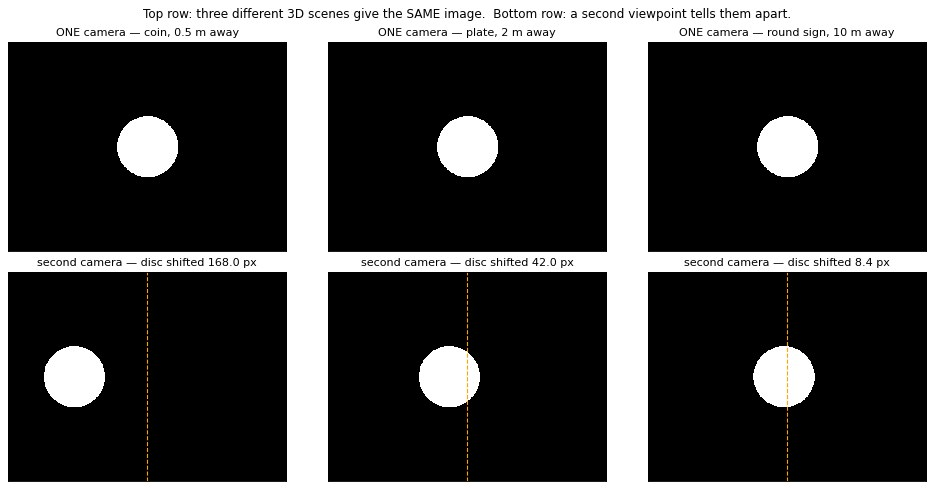

Are the three single-camera images pixel-for-pixel identical?  True

scene                  radius S (m)  depth Z (m)  image radius f*S/Z (px)  shift between cameras f*B/Z (px)
---------------------  ------------  -----------  -----------------------  --------------------------------
coin, 0.5 m away       0.05          0.5          70                       168                             
plate, 2 m away        0.2           2            70                       42                              
round sign, 10 m away  1             10           70                       8.4                             


In [4]:
# --- 1.1 🔬 Three different scenes, one identical image  [simulated] --------------------------
F_PX, W, H = 700.0, 640, 480  # same focal length as the worked example in §4.1
CX, CY = W / 2, H / 2
BASELINE_M = 0.12  # second camera 12 cm to the right (also from §4.1)

# (label, radius in metres, depth in metres) — flat discs facing the camera, centred on its optical axis
scenes = [("coin, 0.5 m away", 0.05, 0.5), ("plate, 2 m away", 0.20, 2.0), ("round sign, 10 m away", 1.00, 10.0)]


def render_disc(radius_m: float, depth_m: float, camera_x_m: float = 0.0) -> np.ndarray:
    """Image of the disc seen by a pinhole camera that sits `camera_x_m` to the right of the first camera."""
    u_centre = CX + F_PX * (0.0 - camera_x_m) / depth_m  # where the disc centre projects
    radius_px = F_PX * radius_m / depth_m  # s = f * S / Z
    v, u = np.mgrid[0:H, 0:W]
    return ((u - u_centre) ** 2 + (v - CY) ** 2 <= radius_px**2).astype(np.uint8) * 255


left_views = [render_disc(r, z) for _, r, z in scenes]
right_views = [render_disc(r, z, camera_x_m=BASELINE_M) for _, r, z in scenes]

fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
for k, (label, r, z) in enumerate(scenes):
    axes[0, k].imshow(left_views[k], cmap="gray")
    axes[0, k].set_title(f"ONE camera — {label}")
    axes[1, k].imshow(right_views[k], cmap="gray")
    axes[1, k].axvline(CX, color="orange", ls="--", lw=1)
    axes[1, k].set_title(f"second camera — disc shifted {F_PX * BASELINE_M / z:.1f} px")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(
    "Top row: three different 3D scenes give the SAME image.  Bottom row: a second viewpoint tells them apart."
)
plt.show()

identical = all(np.array_equal(left_views[0], view) for view in left_views)
print(f"Are the three single-camera images pixel-for-pixel identical?  {identical}\n")
table(
    [(label, r, z, F_PX * r / z, F_PX * BASELINE_M / z) for label, r, z in scenes],
    ["scene", "radius S (m)", "depth Z (m)", "image radius f*S/Z (px)", "shift between cameras f*B/Z (px)"],
)

**Read the result.** The image radius is 70 px in all three cases, so one camera cannot separate them.
The *shift between the two cameras* (called **disparity**, Part 5) is 168 px, 42 px and 8.4 px:
near things jump a lot, far things barely move. That inverse relation is the whole of stereo vision.

✍️ **Exercise 1 (1 min).** A drone camera with $f = 700$ px sees a car that is 140 px wide.
(a) How far away is it if it is a real car, 1.8 m wide? (b) And if it is a toy car, 9 cm wide?
(c) What extra knowledge did you just use to get a distance out of *one* image?

<details><summary>Show answer</summary>

$Z = f \cdot S / s$. (a) $700 \times 1.8 / 140 = 9.0$ m. (b) $700 \times 0.09 / 140 = 0.45$ m.
(c) You assumed the object's **true size** — a prior about the world. That is exactly how monocular depth
networks escape the ambiguity (§5.3): not with geometry, but with learned knowledge of what things usually look like.

</details>

---
# Part 2 — The pinhole camera: intrinsics, extrinsics, projection matrix  *(8 min · §2.1–2.3)*

🧠 **Concept.** Two sets of numbers describe a camera:

| | What it describes | Symbols | Changes when… |
|---|---|---|---|
| **Intrinsics** | the camera's own optics | focal length $f_x, f_y$, principal point $c_x, c_y$ → matrix $K$ | you zoom or change the lens |
| **Extrinsics** | where the camera is and where it points | rotation $R$ (3×3), translation $t$ (3×1) | the camera moves |

Together they form one 3×4 **projection matrix** that takes a 3D world point to a pixel in a single multiplication
(homogeneous coordinates):

$$ \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} \sim \underbrace{K\,[\,R \mid t\,]}_{P}
   \begin{bmatrix} X \\ Y \\ Z \\ 1 \end{bmatrix},
   \qquad K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} $$

"$\sim$" means *equal after dividing by the third coordinate* — that division by depth is the perspective effect.
Camera axes (OpenCV convention): **x right, y down, z forward**.

In [5]:
# --- 2.1 Build P = K [R | t] and project a 3D scene  [simulated] ------------------------------
F_PX, W, H = 700.0, 640, 480  # the "lecture camera" again, so this part also runs on its own
CX, CY = W / 2, H / 2


def make_K(f: float, cx: float, cy: float) -> np.ndarray:
    """Intrinsic matrix for square pixels."""
    return np.array([[f, 0.0, cx], [0.0, f, cy], [0.0, 0.0, 1.0]])


def rot_y(deg: float) -> np.ndarray:
    """Rotation about the vertical (y) axis: the direction a camera faces after turning right by `deg`."""
    a = np.radians(deg)
    return np.array([[np.cos(a), 0.0, np.sin(a)], [0.0, 1.0, 0.0], [-np.sin(a), 0.0, np.cos(a)]])


def projection_matrix(K: np.ndarray, yaw_deg: float, centre: Sequence[float]) -> np.ndarray:
    """P = K [R | t].  R turns world axes into camera axes; t = -R C puts the camera centre C at the origin."""
    R = rot_y(yaw_deg).T
    t = -R @ np.asarray(centre, dtype=float)
    return K @ np.hstack([R, t.reshape(3, 1)])


def project(P: np.ndarray, X: np.ndarray):
    """Project Nx3 world points. Returns (Nx2 pixels, N depths along the camera's z axis)."""
    x = np.hstack([X, np.ones((len(X), 1))]) @ P.T  # homogeneous multiply
    return x[:, :2] / x[:, 2:3], x[:, 2]  # divide by depth = perspective


# A small world: a house standing on the ground 8-12 m in front of us. Ground is at y = +1.5 (y points DOWN).
HOUSE = np.array(
    [
        [-1.5, 1.5, 8],
        [1.5, 1.5, 8],
        [1.5, 1.5, 12],
        [-1.5, 1.5, 12],  # 0-3  floor corners
        [-1.5, -0.5, 8],
        [1.5, -0.5, 8],
        [1.5, -0.5, 12],
        [-1.5, -0.5, 12],  # 4-7  top of the walls
        [0.0, -1.5, 8],
        [0.0, -1.5, 12],
    ],
    dtype=float,
)  # 8-9  roof ridge
FRONT_EDGES = [(0, 1), (1, 5), (5, 4), (4, 0), (4, 8), (5, 8)]  # front wall (z = 8 m)
OTHER_EDGES = [(1, 2), (2, 3), (3, 0), (2, 6), (3, 7), (5, 6), (6, 7), (7, 4), (6, 9), (7, 9), (8, 9)]
GRID = [np.column_stack([np.full(40, x), np.full(40, 1.5), np.linspace(2, 20, 40)]) for x in range(-5, 6)] + [
    np.column_stack([np.linspace(-5, 5, 40), np.full(40, 1.5), np.full(40, z)]) for z in range(2, 21, 2)
]


def draw_scene(ax, P: np.ndarray, title: str) -> None:
    for line in GRID:  # ground grid
        uv, z = project(P, line)
        uv[z < 0.2] = np.nan  # never draw points behind the camera
        ax.plot(uv[:, 0], uv[:, 1], color="0.8", lw=0.6)
    uv, z = project(P, HOUSE)
    for edges, colour in ((OTHER_EDGES, "tab:blue"), (FRONT_EDGES, "tab:red")):
        for i, j in edges:
            if z[i] > 0.2 and z[j] > 0.2:
                ax.plot(uv[[i, j], 0], uv[[i, j], 1], color=colour, lw=1.8)
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)


K_ref = make_K(F_PX, CX, CY)
P_ref = projection_matrix(K_ref, yaw_deg=0, centre=(0, 0, 0))
print("K =\n", K_ref, "\n\nP = K [R | t] =\n", P_ref)

# Trust, but verify: our 4 lines of NumPy must agree with OpenCV's own projection function.
R_test = rot_y(10).T
C_test = np.array([1.0, 0.0, 0.5])
uv_ours, _ = project(projection_matrix(K_ref, 10, C_test), HOUSE)
uv_cv, _ = cv2.projectPoints(HOUSE, cv2.Rodrigues(R_test)[0], -R_test @ C_test, K_ref, None)
print(f"\nmax difference to cv2.projectPoints: {np.abs(uv_ours - uv_cv.reshape(-1, 2)).max():.2e} px")

K =
 [[700.   0. 320.]
 [  0. 700. 240.]
 [  0.   0.   1.]] 

P = K [R | t] =
 [[700.   0. 320.   0.]
 [  0. 700. 240.   0.]
 [  0.   0.   1.   0.]]

max difference to cv2.projectPoints: 3.48e-13 px


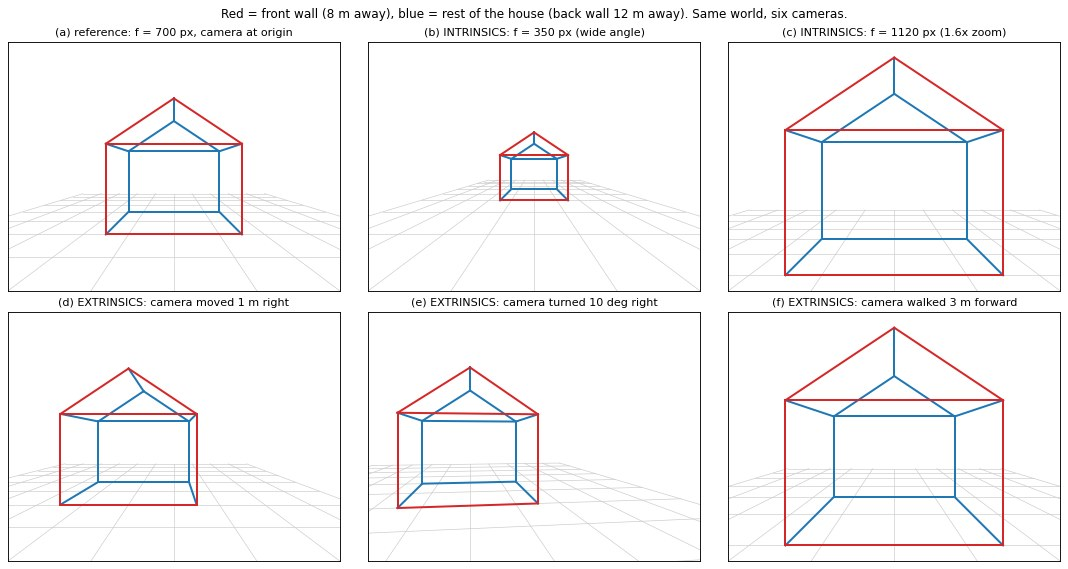

view  front wall width (px)  back wall width (px)
----  ---------------------  --------------------
(a)   262.5                  175                 
(b)   131.2                  87.5                
(c)   420                    280                 
(d)   262.5                  175                 
(e)   271                    180.5               
(f)   420                    233.3               

(c) zoom and (f) walking forward make the FRONT wall equally big — but look at the back wall.

Horizontal field of view at f = 700 px on a 640-px-wide sensor: 49.1 deg


In [6]:
# --- 2.2 🔬 Change intrinsics vs. change extrinsics — what moves in the image? ----------------
experiments = [
    ("(a) reference: f = 700 px, camera at origin", make_K(700, CX, CY), 0, (0, 0, 0)),
    ("(b) INTRINSICS: f = 350 px (wide angle)", make_K(350, CX, CY), 0, (0, 0, 0)),
    ("(c) INTRINSICS: f = 1120 px (1.6x zoom)", make_K(1120, CX, CY), 0, (0, 0, 0)),
    ("(d) EXTRINSICS: camera moved 1 m right", make_K(700, CX, CY), 0, (1, 0, 0)),
    ("(e) EXTRINSICS: camera turned 10 deg right", make_K(700, CX, CY), 10, (0, 0, 0)),
    ("(f) EXTRINSICS: camera walked 3 m forward", make_K(700, CX, CY), 0, (0, 0, 3)),
]
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7), constrained_layout=True)
rows = []
for ax, (title, K, yaw, centre) in zip(axes.ravel(), experiments):
    P = projection_matrix(K, yaw, centre)
    draw_scene(ax, P, title)
    uv, _ = project(P, HOUSE)
    rows.append((title[:3], uv[1, 0] - uv[0, 0], uv[2, 0] - uv[3, 0]))  # width of front wall, back wall (px)
fig.suptitle("Red = front wall (8 m away), blue = rest of the house (back wall 12 m away). Same world, six cameras.")
plt.show()

table(rows, ["view", "front wall width (px)", "back wall width (px)"])
print("\n(c) zoom and (f) walking forward make the FRONT wall equally big — but look at the back wall.")

fov_x = 2 * np.degrees(np.arctan(W / (2 * F_PX)))
print(f"\nHorizontal field of view at f = {F_PX:.0f} px on a {W}-px-wide sensor: {fov_x:.1f} deg")

**Read the result.**
- **(b), (c)** change only $K$: the picture scales about the principal point, but *what hides what* stays the same.
- **(d), (e), (f)** change only $[R\mid t]$: the camera sees the world from somewhere else.
- **(c) vs (f)** — zooming is **not** the same as walking closer. Zoom magnifies every depth by the same factor;
  walking changes $Z$, so near things grow more than far things. Depth information lives in exactly this
  difference — it is the reason a *moving* camera can recover 3D (Part 8) and a *zooming* one cannot.

🌍 **Real world.** Lens focal lengths are sold in millimetres, but geometry needs pixels:
$f_{px} = f_{mm} \times \dfrac{\text{image width (px)}}{\text{sensor width (mm)}}$ and
$\text{FOV} = 2\arctan\!\big(\tfrac{W}{2 f_{px}}\big)$.

✍️ **Exercise 2 (2 min).**
1. Before looking at panel (d) again: when the camera moves **right**, which way does the house move in the image?
2. A camera has a 4 mm lens, a sensor 5.6 mm wide and 640-px-wide images *(illustrative numbers)*.
   What is $f$ in pixels and what is its horizontal field of view?
3. In `draw_scene` we skip points with depth `z < 0.2`. What would the projection formula give for a point
   *behind* the camera, and why is that dangerous?

<details><summary>Show answer</summary>

1. **Left** — the image moves opposite to the camera. (Near objects move more than far ones: that is parallax.)
2. $f = 4 \times 640 / 5.6 \approx 457$ px, FOV $= 2\arctan(320/457) \approx 70°$.
3. Dividing by a negative $Z$ still returns a perfectly valid-looking pixel (mirrored through the centre).
   Nothing crashes — you just draw geometry that the camera cannot see. Always check $Z > 0$
   (the "cheirality" test that `cv2.recoverPose` performs for you in Part 4).

</details>

---
# Part 3 — Lens distortion and camera calibration  *(10 min · §2.4)*

🧠 **Concept.** The pinhole model draws straight lines as straight lines. Real lenses do not — wide lenses
bend lines outwards (*barrel distortion*). **Calibration** means *measuring* a specific camera's intrinsics
$K$ and distortion coefficients, by photographing a pattern whose geometry we know exactly
(a checkerboard) from several angles and solving for the parameters that best explain where the corners land.

The quality measure is the **reprojection error**: project the known 3D corners through the estimated
camera and measure how far (in pixels) they fall from the detected corners. Below ~0.5 px RMS is a good calibration.

**Real data.** 13 photo pairs from a real two-camera rig (OpenCV sample data). A person holds a checkerboard
with 9 × 6 inner corners. OpenCV's reference calibration of this camera assumes **25 mm squares**; we use the same value.

🌍 **Real world.** Every phone, robot, AR headset and car camera goes through this procedure — usually at the
factory, sometimes again in the field. Without it, "pixels" cannot be turned into "metres".

*Needs:* Part 0.

13 stereo pairs, image size (640, 480), corners found in every image: 13 left + 13 right, 54 corners each


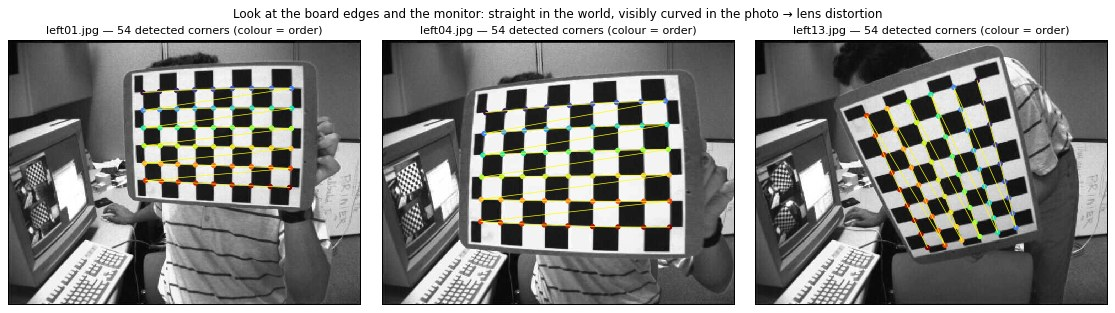

In [7]:
# --- 3.1 Detect the checkerboard corners in all 26 photos  [measured] -------------------------
PATTERN = (9, 6)  # inner corners per row, per column
SQUARE_M = 0.025  # side of one square in METRES (value used by OpenCV's reference calibration)

# 3D coordinates of the corners in the board's own frame: (0,0,0), (1,0,0), ... scaled by the square size, Z = 0
BOARD_PTS = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
BOARD_PTS[:, :2] = np.mgrid[0 : PATTERN[0], 0 : PATTERN[1]].T.reshape(-1, 2) * SQUARE_M


def find_corners(gray: np.ndarray) -> Optional[np.ndarray]:
    """Return the 54 checkerboard corners as a (54, 1, 2) float32 array, refined to sub-pixel accuracy."""
    found, corners = cv2.findChessboardCorners(gray, PATTERN)
    if not found:
        return None
    corners = np.asarray(corners, np.float32).reshape(-1, 1, 2)  # same shape on OpenCV 4 and 5
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)
    return cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria).reshape(-1, 1, 2)


GRAY_L = [imread_gray(DATA / f"rig/left{i}.jpg") for i in PAIR_IDS]
GRAY_R = [imread_gray(DATA / f"rig/right{i}.jpg") for i in PAIR_IDS]
CORN_L = [find_corners(g) for g in GRAY_L]
CORN_R = [find_corners(g) for g in GRAY_R]
IMG_SIZE = GRAY_L[0].shape[::-1]  # (width, height) = (640, 480)
assert all(c is not None for c in CORN_L + CORN_R), "a checkerboard was not detected"
print(
    f"{len(GRAY_L)} stereo pairs, image size {IMG_SIZE}, corners found in every image: "
    f"{len(CORN_L)} left + {len(CORN_R)} right, {len(BOARD_PTS)} corners each"
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for ax, k in zip(axes, (0, 3, 11)):
    pts = CORN_L[k].reshape(-1, 2)
    ax.imshow(GRAY_L[k], cmap="gray")
    ax.plot(pts[:, 0], pts[:, 1], "-", color="yellow", lw=0.6)
    ax.scatter(pts[:, 0], pts[:, 1], c=np.arange(len(pts)), cmap="turbo", s=14)
    ax.set_title(f"left{PAIR_IDS[k]}.jpg — 54 detected corners (colour = order)")
    ax.axis("off")
fig.suptitle(
    "Look at the board edges and the monitor: straight in the world, visibly curved in the photo → lens distortion"
)
plt.show()

In [8]:
# --- 3.2 Calibrate both cameras  [measured] ---------------------------------------------------
def calibrate(corner_list: Sequence[np.ndarray]):
    """Zhang's method: returns (rms_px, K, dist, rvecs, tvecs) for one camera."""
    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
        [BOARD_PTS] * len(corner_list), list(corner_list), IMG_SIZE, None, None
    )
    return float(rms), K, dist, rvecs, tvecs


rms1, K1, d1, rvecs1, tvecs1 = calibrate(CORN_L)  # left camera
rms2, K2, d2, _, _ = calibrate(CORN_R)  # right camera (needed for stereo in Part 4)

print("LEFT camera intrinsics K1 =\n", K1)
print("distortion (k1, k2, p1, p2, k3) =", np.ravel(d1))
print(f"RMS reprojection error: left {rms1:.3f} px, right {rms2:.3f} px\n")

# Cross-check against the calibration file that ships with OpenCV for the same 13 photos.
ref = cv2.FileStorage(str(DATA / "rig/left_intrinsics.yml"), cv2.FILE_STORAGE_READ)
K_ref_file = ref.getNode("camera_matrix").mat()
rms_ref = ref.getNode("avg_reprojection_error").real()
square_ref = ref.getNode("square_size").real()
ref.release()
table(
    [
        ("fx (px)", K1[0, 0], K_ref_file[0, 0]),
        ("fy (px)", K1[1, 1], K_ref_file[1, 1]),
        ("cx (px)", K1[0, 2], K_ref_file[0, 2]),
        ("cy (px)", K1[1, 2], K_ref_file[1, 2]),
        ("RMS error (px)", rms1, rms_ref),
        ("square size (m)", SQUARE_M, square_ref),
    ],
    ["quantity", "our calibration", "OpenCV reference file"],
)
print(f"\nOur focal length differs from the reference by {abs(K1[0, 0] - K_ref_file[0, 0]) / K_ref_file[0, 0]:.3%}.")
print(f"Field of view of this camera: {2 * np.degrees(np.arctan(IMG_SIZE[0] / (2 * K1[0, 0]))):.1f} deg horizontally")

LEFT camera intrinsics K1 =
 [[536.0734   0.     342.3705]
 [  0.     536.0163 235.5369]
 [  0.       0.       1.    ]]
distortion (k1, k2, p1, p2, k3) = [-0.2651 -0.0467  0.0018 -0.0003  0.2523]
RMS reprojection error: left 0.409 px, right 0.459 px

quantity         our calibration  OpenCV reference file
---------------  ---------------  ---------------------
fx (px)          536.1            535.9                
fy (px)          536              535.9                
cx (px)          342.4            342.3                
cy (px)          235.5            235.6                
RMS error (px)   0.4087           0.3926               
square size (m)  0.025            0.025                

Our focal length differs from the reference by 0.029%.
Field of view of this camera: 61.7 deg horizontally


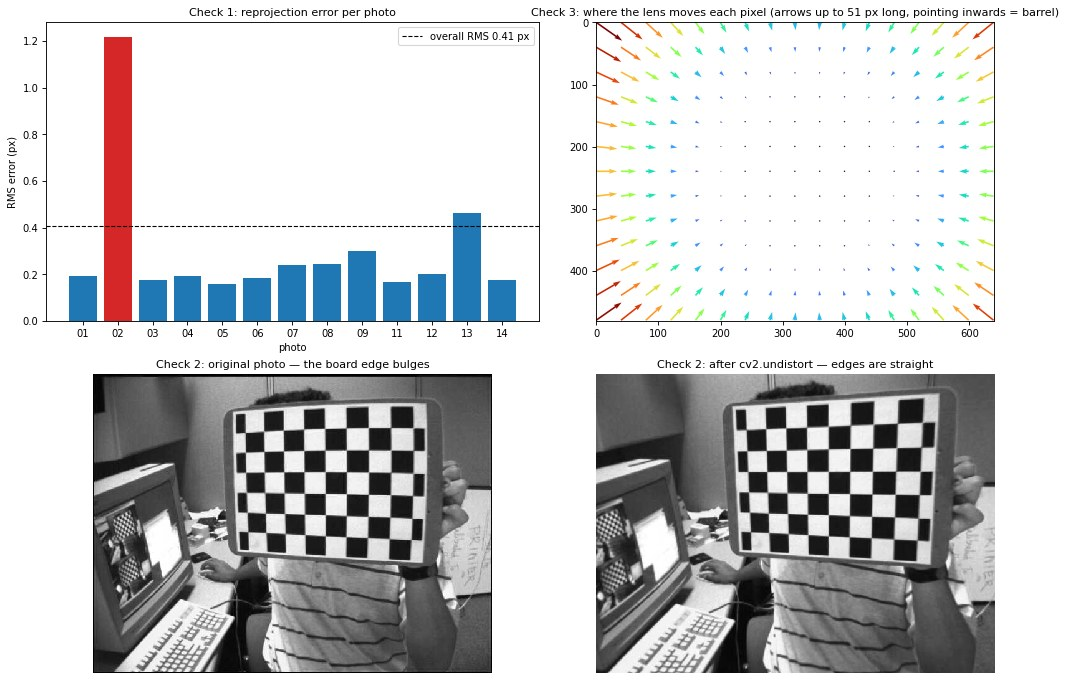

Check 1  worst photo: left02.jpg with 1.22 px (median of the others 0.19 px)
         calibrating WITHOUT it: RMS 0.234 px (was 0.409 px)
Check 2  board lines deviate from straight by 0.527 px before and 0.097 px after undistortion
Check 3  the lens moves image corners by up to 51.2 px — far too much to ignore


In [9]:
# --- 3.3 🔬 Is the calibration any good? Three checks  [measured] ------------------------------
def reprojection_rms(corners: np.ndarray, rvec, tvec, K, dist) -> float:
    projected, _ = cv2.projectPoints(BOARD_PTS, rvec, tvec, K, dist)
    return float(np.sqrt(np.mean(np.sum((projected.reshape(-1, 2) - corners.reshape(-1, 2)) ** 2, axis=1))))


def line_rms(points: np.ndarray) -> float:
    """RMS distance (px) of 2D points from their best-fit straight line — 0 means perfectly straight."""
    centred = points - points.mean(axis=0)
    return float(np.linalg.svd(centred, compute_uv=False)[-1] / np.sqrt(len(points)))


def straightness(corners: np.ndarray) -> float:
    """Mean line_rms over the 6 rows and 9 columns of board corners (which are straight lines in the world)."""
    grid = corners.reshape(PATTERN[1], PATTERN[0], 2)
    lines = [grid[r] for r in range(PATTERN[1])] + [grid[:, c] for c in range(PATTERN[0])]
    return float(np.mean([line_rms(line) for line in lines]))


# Check 1 — reprojection error per photo
per_view = [reprojection_rms(c, r, t, K1, d1) for c, r, t in zip(CORN_L, rvecs1, tvecs1)]
worst = int(np.argmax(per_view))

# Check 2 — are straight board lines straight again after undistortion?
undist = [cv2.undistortPoints(c, K1, d1, P=K1) for c in CORN_L]
bend_before = np.mean([straightness(c) for c in CORN_L])
bend_after = np.mean([straightness(c) for c in undist])

# Check 3 — how far does this lens push pixels? (ideal pinhole position vs. where the real lens puts it)
gx, gy = np.meshgrid(np.linspace(0, IMG_SIZE[0] - 1, 17), np.linspace(0, IMG_SIZE[1] - 1, 13))
ideal = np.column_stack([gx.ravel(), gy.ravel()])
rays = np.column_stack([(ideal[:, 0] - K1[0, 2]) / K1[0, 0], (ideal[:, 1] - K1[1, 2]) / K1[1, 1], np.ones(len(ideal))])
real, _ = cv2.projectPoints(rays, np.zeros(3), np.zeros(3), K1, d1)
shift = real.reshape(-1, 2) - ideal

fig, axes = plt.subplots(2, 2, figsize=(13, 8.4), constrained_layout=True)
axes = axes.ravel()
axes[0].bar(
    range(len(per_view)), per_view, color=["tab:red" if k == worst else "tab:blue" for k in range(len(per_view))]
)
axes[0].axhline(rms1, color="k", ls="--", lw=1, label=f"overall RMS {rms1:.2f} px")
axes[0].set_xticks(range(len(per_view)), PAIR_IDS)
axes[0].set_xlabel("photo")
axes[0].set_ylabel("RMS error (px)")
axes[0].set_title("Check 1: reprojection error per photo")
axes[0].legend()
axes[1].quiver(
    ideal[:, 0],
    ideal[:, 1],
    shift[:, 0],
    shift[:, 1],
    np.hypot(*shift.T),
    angles="xy",
    scale_units="xy",
    scale=1,
    cmap="turbo",
)
axes[1].set_xlim(0, IMG_SIZE[0])
axes[1].set_ylim(IMG_SIZE[1], 0)
axes[1].set_aspect("equal")
axes[1].set_title(
    f"Check 3: where the lens moves each pixel "
    f"(arrows up to {np.hypot(*shift.T).max():.0f} px long, pointing inwards = barrel)"
)
axes[2].imshow(GRAY_L[0], cmap="gray")
axes[2].set_title("Check 2: original photo — the board edge bulges")
axes[2].axis("off")
axes[3].imshow(cv2.undistort(GRAY_L[0], K1, d1), cmap="gray")
axes[3].set_title("Check 2: after cv2.undistort — edges are straight")
axes[3].axis("off")
plt.show()

print(
    f"Check 1  worst photo: left{PAIR_IDS[worst]}.jpg with {per_view[worst]:.2f} px (median of the others "
    f"{np.median(np.delete(per_view, worst)):.2f} px)"
)
keep = [k for k in range(len(CORN_L)) if k != worst]
print(f"         calibrating WITHOUT it: RMS {calibrate([CORN_L[k] for k in keep])[0]:.3f} px (was {rms1:.3f} px)")
print(
    f"Check 2  board lines deviate from straight by {bend_before:.3f} px before and {bend_after:.3f} px after undistortion"
)
print(f"Check 3  the lens moves image corners by up to {np.hypot(*shift.T).max():.1f} px — far too much to ignore")

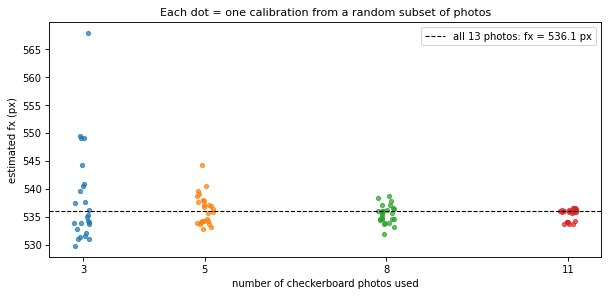

photos used  std of fx (px)  min fx  max fx
-----------  --------------  ------  ------
3            8.363           529.8   567.9 
5            2.675           532.7   544.3 
8            1.616           531.9   538.8 
11           1.046           533.7   536.6 
  if the lens is 4 mm (f = 700 px): depth = 0.12 * 700 / 28 = 3.00 m
  if the lens is 8 mm (f = 1400 px): depth = 0.12 * 1400 / 28 = 6.00 m
  Same pixels, depth differs by 2x → focal length must be measured, never guessed.


In [10]:
# --- 3.4 🔬 How many photos do we need? Calibration is an estimate, not a fact  [measured] ------
rng_cal = np.random.default_rng(SEED)
subset_sizes = (3, 5, 8, 11)
fx_runs = {}
for n_photos in subset_sizes:
    fx_runs[n_photos] = []
    for _ in range(25):  # 25 random choices of n photos
        chosen = rng_cal.choice(len(CORN_L), size=n_photos, replace=False)
        fx_runs[n_photos].append(calibrate([CORN_L[k] for k in chosen])[1][0, 0])

fig, ax = plt.subplots(figsize=(7.5, 3.6), constrained_layout=True)
for n_photos, values in fx_runs.items():
    ax.scatter(np.full(len(values), n_photos) + rng_cal.uniform(-0.15, 0.15, len(values)), values, s=14, alpha=0.7)
ax.axhline(K1[0, 0], color="k", ls="--", lw=1, label=f"all 13 photos: fx = {K1[0, 0]:.1f} px")
ax.set_xticks(subset_sizes)
ax.set_xlabel("number of checkerboard photos used")
ax.set_ylabel("estimated fx (px)")
ax.set_title("Each dot = one calibration from a random subset of photos")
ax.legend()
plt.show()

table(
    [(n, float(np.std(v)), float(np.min(v)), float(np.max(v))) for n, v in fx_runs.items()],
    ["photos used", "std of fx (px)", "min fx", "max fx"],
)

# Why this matters for depth (worked example in §2.4): same rig, same measured disparity, two possible lenses.
disparity_px, baseline_m = 28.0, 0.12
for lens_mm, f_px in ((4, 700.0), (8, 1400.0)):  # f in pixels is proportional to f in mm
    print(
        f"  if the lens is {lens_mm} mm (f = {f_px:.0f} px): depth = {baseline_m} * {f_px:.0f} / {disparity_px:.0f} "
        f"= {baseline_m * f_px / disparity_px:.2f} m"
    )
print("  Same pixels, depth differs by 2x → focal length must be measured, never guessed.")

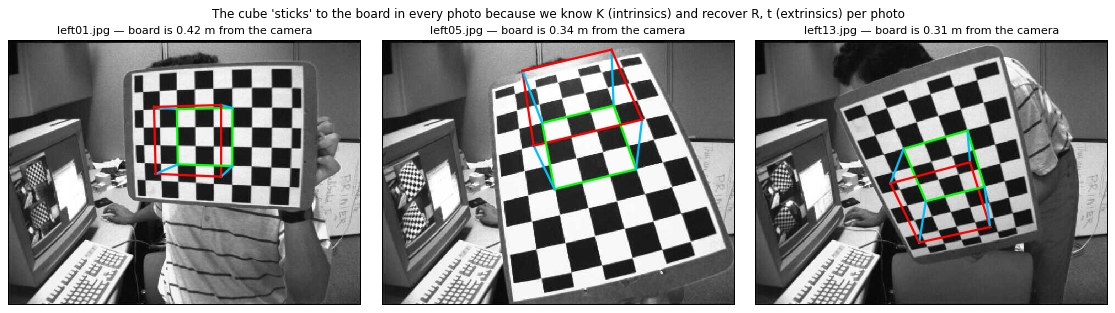

In [11]:
# --- 3.5 🌍 Application: augmented reality — glue a virtual cube onto the real board ----------
def draw_ar_cube(ax, gray: np.ndarray, corners: np.ndarray, K: np.ndarray, dist: np.ndarray) -> np.ndarray:
    """Estimate the board pose (extrinsics) from one photo and draw a 3-square virtual cube standing on it."""
    ok, rvec, tvec = cv2.solvePnP(BOARD_PTS, corners, K, dist)  # extrinsics of THIS photo: R (as rvec), t
    s = SQUARE_M
    base = np.float32([[2, 1, 0], [5, 1, 0], [5, 4, 0], [2, 4, 0]]) * s
    top = base + np.float32([0, 0, -3 * s])  # board's z axis points away from the camera
    pts, _ = cv2.projectPoints(np.vstack([base, top]), rvec, tvec, K, dist)
    p = pts.reshape(-1, 2)
    ax.imshow(gray, cmap="gray")
    for i in range(4):
        j = (i + 1) % 4
        ax.plot(p[[i, j], 0], p[[i, j], 1], color="lime", lw=2)  # base, on the board
        ax.plot(p[[i, i + 4], 0], p[[i, i + 4], 1], color="deepskyblue", lw=2)  # pillars
        ax.plot(p[[i + 4, j + 4], 0], p[[i + 4, j + 4], 1], color="red", lw=2)  # top face, floating towards us
    ax.axis("off")
    return tvec.ravel()


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for ax, k in zip(axes, (0, 4, 11)):
    t_board = draw_ar_cube(ax, GRAY_L[k], CORN_L[k], K1, d1)
    ax.set_title(f"left{PAIR_IDS[k]}.jpg — board is {np.linalg.norm(t_board):.2f} m from the camera")
fig.suptitle(
    "The cube 'sticks' to the board in every photo because we know K (intrinsics) and recover R, t (extrinsics) per photo"
)
plt.show()

**Read the result.**
- Our $K$ matches OpenCV's reference file to a fraction of a percent, with RMS error ≈ 0.4 px. `[measured]`
- One photo is clearly worse than the rest. Calibration is a least-squares fit, so **one bad photo pulls every parameter**.
- With only 3 photos the focal length varies a lot between runs; with 8–11 it settles. This is the notes'
  reproducibility warning (§11) made visible: *"run calibration more than once to check its own stability"*.
- The AR cube is the whole of Part 2 in one picture: **intrinsics** come from calibration (once), **extrinsics** are re-estimated for every photo.

⚠️ **Pitfall (§11).** *Verify calibration before debugging anything downstream.* A perfect disparity map
still gives wrong depth if $f$ or the baseline is wrong.

✍️ **Exercise 3 (2 min).**
1. Suppose you typed `SQUARE_M = 25` (millimetres) instead of `0.025`. Which outputs change: $K$? the distortion
   coefficients? the board distance printed above the AR images?
2. Why must the checkerboard photos be taken from *different angles and distances* (PP17 tip)?
3. Display the worst photo (`show([GRAY_L[worst]])`). What do you notice about the board's pose?

<details><summary>Show answer</summary>

1. $K$ and the distortion coefficients **do not change** — they are properties of the camera, measured in pixels.
   Only the extrinsics scale: the board distance would read `420` instead of `0.42`. Nothing warns you.
   Later the stereo baseline, and therefore every depth, would silently be "in millimetres" (units pitfall, §11).
2. A single flat board seen from one direction cannot separate "long focal length, board far away" from
   "short focal length, board close" — the same ambiguity as Part 1. Tilted and shifted views break it.
   Cell 3.4 showed what happens with too few views.
3. *Observation:* it is the closest and most strongly tilted board, and it reaches the image borders.
   *Likely reasons (hypotheses you can test):* distortion is largest at the borders, where a 5-coefficient model
   fits worst, and strongly foreshortened squares are harder to localise. Test idea: plot each corner's
   residual against its distance from the image centre.

</details>

---
# Part 4 — Epipolar geometry, F and E matrices, rectification  *(11 min · §3)*

🧠 **Concept.** Two cameras look at the same scene. For a pixel $x$ in the left image we want its partner
$x'$ in the right image (the **correspondence** problem). Geometry helps: the 3D point and the two camera centres
span a plane, and that plane cuts the right image in a line — the **epipolar line**. The partner *must* lie on it:

$$ x'^{\top} F \, x = 0 $$

- **Fundamental matrix $F$** (3×3): works directly on pixels, no calibration needed.
- **Essential matrix $E = K'^{\top} F K$**: the same constraint once intrinsics are known; it contains the
  relative rotation $R$ and the *direction* of the translation $t$ between the cameras.
- Both are estimated from matched keypoints with **RANSAC** — the Day 28 detect → match → RANSAC pipeline,
  with $F$ or $E$ as the model instead of a homography.
- **Rectification** warps both images so that every epipolar line becomes the *same horizontal row*.
  The 2D search for a match becomes a 1D search along a row — this is what makes dense stereo (Part 5) feasible.

**Two routes to a rectified pair** (they mirror the two paths of assignment PP17):

| | Path A — calibrated | Path B — self-calibrated |
|---|---|---|
| Relative pose from | checkerboard corners of all 13 pairs (`stereoCalibrate`) | SIFT matches of **one** ordinary photo pair |
| Needs | a calibration session with the rig | only intrinsics $K$ (Part 3) + the two photos |

🌍 **Real world.** Stereo cameras on robots, drones and cars are calibrated like Path A and rectified on the fly.
Path B is what you do with two phone photos, or when a rig has been bumped and its factory calibration is no longer true.

*Needs:* Parts 0 and 3.

pair 01: 385 matches after the ratio test → 208 RANSAC inliers (54%), 177 rejected


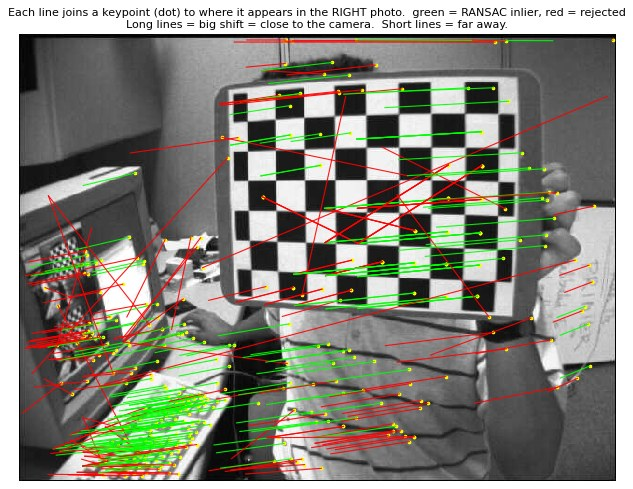

In [12]:
# --- 4.1 Correspondences: SIFT → ratio test → RANSAC fundamental matrix  [measured] -----------
PAIR = 0  # which of the 13 pairs to work on (0 → left01 / right01)
SIFT = cv2.SIFT_create()


def match_sift(gray_a: np.ndarray, gray_b: np.ndarray, ratio: float = 0.75):
    """Day 28 pipeline. Returns matched pixel coordinates as two (N, 2) float32 arrays."""
    kp_a, des_a = SIFT.detectAndCompute(gray_a, None)
    kp_b, des_b = SIFT.detectAndCompute(gray_b, None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_a, des_b, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]  # Lowe's ratio test
    return np.float32([kp_a[m.queryIdx].pt for m in good]), np.float32([kp_b[m.trainIdx].pt for m in good])


MATCHES = [match_sift(gl, gr) for gl, gr in zip(GRAY_L, GRAY_R)]  # all 13 pairs (re-used in 4.3)
pts_l, pts_r = MATCHES[PAIR]

F_raw, mask = cv2.findFundamentalMat(pts_l, pts_r, cv2.FM_RANSAC, 1.0, 0.999)  # 1 px threshold, 99.9 % confidence
inl = mask.ravel().astype(bool)
print(
    f"pair {PAIR_IDS[PAIR]}: {len(pts_l)} matches after the ratio test → {inl.sum()} RANSAC inliers "
    f"({inl.mean():.0%}), {(~inl).sum()} rejected"
)

fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
ax.imshow(GRAY_L[PAIR], cmap="gray")
for (xa, ya), (xb, yb), ok in zip(pts_l, pts_r, inl):
    ax.plot([xa, xb], [ya, yb], color="lime" if ok else "red", lw=1.0, alpha=0.9)
ax.scatter(pts_l[:, 0], pts_l[:, 1], s=5, c="yellow")
ax.set_title(
    "Each line joins a keypoint (dot) to where it appears in the RIGHT photo.  green = RANSAC inlier, red = rejected\n"
    "Long lines = big shift = close to the camera.  Short lines = far away."
)
ax.axis("off")
plt.show()

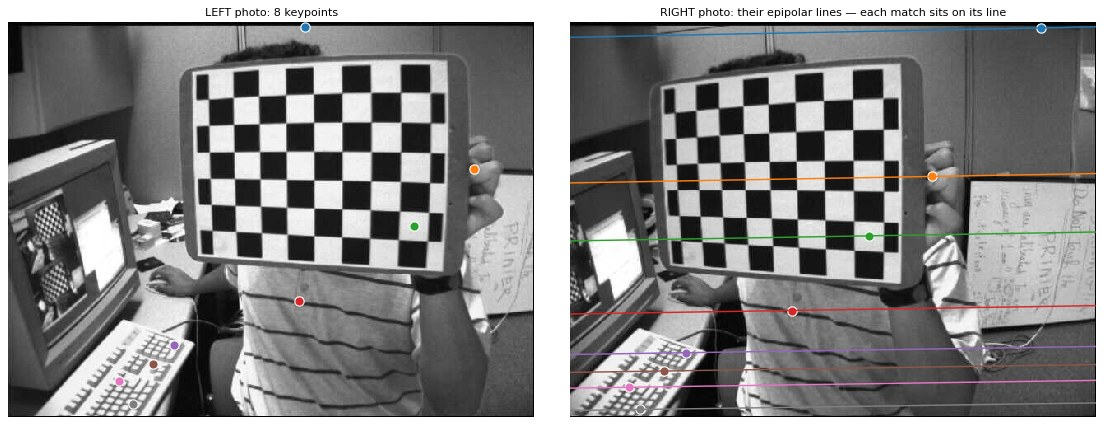

F estimated from                       RANSAC inliers  median epipolar error on 54 held-out corners (px)
-------------------------------------  --------------  -------------------------------------------------
raw pixels (lens distortion still in)  208             0.5114                                           
pixels after undistortion (Part 3)     232             0.3884                                           

The epipolar constraint is a statement about straight light rays. Distortion bends them, so it must be removed first.


In [13]:
# --- 4.2 🔬 See the epipolar constraint, then test it on points it has never seen ------------
def epipolar_distance(F: np.ndarray, a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Distance in pixels between each point and the epipolar line of its partner (average of both directions)."""
    a_h, b_h = np.c_[a, np.ones(len(a))], np.c_[b, np.ones(len(b))]
    line_in_b, line_in_a = a_h @ F.T, b_h @ F  # l' = F x   and   l = F^T x'
    d_b = np.abs(np.sum(line_in_b * b_h, axis=1)) / np.hypot(line_in_b[:, 0], line_in_b[:, 1])
    d_a = np.abs(np.sum(line_in_a * a_h, axis=1)) / np.hypot(line_in_a[:, 0], line_in_a[:, 1])
    return 0.5 * (d_a + d_b)


def undistort_px(points: np.ndarray, K: np.ndarray, dist: np.ndarray) -> np.ndarray:
    """Remove lens distortion from pixel coordinates (result is still in pixels)."""
    return cv2.undistortPoints(np.asarray(points, np.float32).reshape(-1, 1, 2), K, dist, P=K).reshape(-1, 2)


# Draw 8 inlier points (left) and their epipolar lines (right)
order = np.argsort(pts_l[inl][:, 1])
pick = order[np.linspace(0, len(order) - 1, 8).astype(int)]
sel_l, sel_r = pts_l[inl][pick], pts_r[inl][pick]
colours = plt.cm.tab10(np.arange(8))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
axes[0].imshow(GRAY_L[PAIR], cmap="gray")
axes[1].imshow(GRAY_R[PAIR], cmap="gray")
for (xa, ya), (xb, yb), c in zip(sel_l, sel_r, colours):
    a_, b_, c_ = F_raw @ np.array([xa, ya, 1.0])  # line a*x + b*y + c = 0 in the right image
    xs = np.array([0.0, IMG_SIZE[0] - 1])
    axes[0].scatter(xa, ya, s=70, color=c, edgecolor="white")
    axes[1].plot(xs, -(a_ * xs + c_) / b_, color=c, lw=1.3)
    axes[1].scatter(xb, yb, s=70, color=c, edgecolor="white")
axes[0].set_title("LEFT photo: 8 keypoints")
axes[1].set_title("RIGHT photo: their epipolar lines — each match sits on its line")
for ax in axes:
    ax.set_xlim(0, IMG_SIZE[0])
    ax.set_ylim(IMG_SIZE[1], 0)
    ax.axis("off")
plt.show()

# A fair test needs points that were NOT used to fit F: the 54 checkerboard corners of this pair (sub-pixel accurate).
corners_l, corners_r = CORN_L[PAIR].reshape(-1, 2), CORN_R[PAIR].reshape(-1, 2)
und_l, und_r = undistort_px(pts_l, K1, d1), undistort_px(pts_r, K2, d2)
F_und, mask_u = cv2.findFundamentalMat(und_l, und_r, cv2.FM_RANSAC, 1.0, 0.999)
inl_u = mask_u.ravel().astype(bool)
table(
    [
        (
            "raw pixels (lens distortion still in)",
            int(inl.sum()),
            float(np.median(epipolar_distance(F_raw, corners_l, corners_r))),
        ),
        (
            "pixels after undistortion (Part 3)",
            int(inl_u.sum()),
            float(
                np.median(epipolar_distance(F_und, undistort_px(corners_l, K1, d1), undistort_px(corners_r, K2, d2)))
            ),
        ),
    ],
    ["F estimated from", "RANSAC inliers", "median epipolar error on 54 held-out corners (px)"],
)
print(
    "\nThe epipolar constraint is a statement about straight light rays. "
    "Distortion bends them, so it must be removed first."
)

In [14]:
# --- 4.3 🔬 From matches to camera motion: essential matrix → R, t.  Path A vs Path B ----------
# Path A (reference): stereo calibration from the checkerboard corners of all 13 pairs
stereo = cv2.stereoCalibrate(
    [BOARD_PTS] * len(CORN_L), CORN_L, CORN_R, K1, d1, K2, d2, IMG_SIZE, flags=cv2.CALIB_FIX_INTRINSIC
)
rms_stereo, R_A, T_A = float(stereo[0]), stereo[5], stereo[6].ravel()
BASELINE_RIG_M = float(np.linalg.norm(T_A))
print(
    f"Path A  stereoCalibrate: RMS {rms_stereo:.3f} px | baseline {BASELINE_RIG_M * 100:.2f} cm "
    f"| cameras rotated {np.degrees(np.linalg.norm(cv2.Rodrigues(R_A)[0])):.2f} deg relative to each other"
)

E_from_F = K2.T @ F_und @ K1  # E = K'^T F K
sv = np.linalg.svd(E_from_F, compute_uv=False)
print(f"        singular values of K2^T F K1: {sv / sv[0]} → the (s, s, 0) signature of an essential matrix\n")


def relative_pose_from_matches(p_l: np.ndarray, p_r: np.ndarray):
    """Path B: known intrinsics + matched keypoints → essential matrix (RANSAC) → rotation R and unit translation t."""
    n_l = cv2.undistortPoints(p_l.reshape(-1, 1, 2), K1, d1).reshape(
        -1, 2
    )  # normalised coordinates: K and distortion removed
    n_r = cv2.undistortPoints(p_r.reshape(-1, 1, 2), K2, d2).reshape(-1, 2)
    E, mask_e = cv2.findEssentialMat(n_l, n_r, np.eye(3), method=cv2.RANSAC, prob=0.999, threshold=1.0 / K1[0, 0])
    n_good, R, t, _ = cv2.recoverPose(
        E, n_l, n_r, np.eye(3), mask=mask_e.copy()
    )  # picks the 1 of 4 solutions with points in front
    return R, t.ravel(), int(n_good)


def pose_errors(R: np.ndarray, t: np.ndarray):
    """Angles (deg) between an estimated pose and the Path-A reference: (rotation error, translation-direction error)."""
    rot = np.degrees(np.arccos(np.clip((np.trace(R @ R_A.T) - 1) / 2, -1, 1)))
    trans = np.degrees(np.arccos(np.clip(float(t @ T_A) / BASELINE_RIG_M, -1, 1)))
    return float(rot), float(trans)


rows, POSES_B = [], []
for k, (p_l, p_r) in enumerate(MATCHES):
    R_k, t_k, n_good = relative_pose_from_matches(p_l, p_r)
    POSES_B.append((R_k, t_k))
    rows.append(
        (f"pair {PAIR_IDS[k]}" + ("  ← used below" if k == PAIR else ""), len(p_l), n_good, *pose_errors(R_k, t_k))
    )
R_pool, t_pool, n_pool = relative_pose_from_matches(
    np.vstack([m[0] for m in MATCHES]), np.vstack([m[1] for m in MATCHES])
)
rows.append(("all 13 pairs pooled", sum(len(m[0]) for m in MATCHES), n_pool, *pose_errors(R_pool, t_pool)))
print("Path B  pose from SIFT matches, compared with Path A:")
table(rows, ["photo pair", "matches", "inliers", "rotation error (deg)", "translation direction error (deg)"])

R_B, t_B = POSES_B[PAIR]
print(
    f"\nNote: t from an essential matrix always has length 1 (|t_B| = {np.linalg.norm(t_B):.3f}) — "
    f"two photos alone cannot tell an 8 cm baseline from an 8 m one."
)

Path A  stereoCalibrate: RMS 0.448 px | baseline 8.36 cm | cameras rotated 0.31 deg relative to each other
        singular values of K2^T F K1: [1.     0.9824 0.    ] → the (s, s, 0) signature of an essential matrix

Path B  pose from SIFT matches, compared with Path A:
photo pair             matches  inliers  rotation error (deg)  translation direction error (deg)
---------------------  -------  -------  --------------------  ---------------------------------
pair 01  ← used below  385      246      0.6725                1.637                            
pair 02                217      118      3.763                 36.52                            
pair 03                254      132      0.4011                0.8628                           
pair 04                268      122      10.36                 97.7                             
pair 05                150      50       0.3208                0.7382                           
pair 06                402      266      1.336   

rectification                                    mean row error (px)  95th percentile (px)
-----------------------------------------------  -------------------  --------------------
no rectification (raw photos)                    12.83                17.26               
Path A   checkerboard stereo calibration         0.1406               0.3533              
Path B   K + essential matrix from SIFT matches  0.7582               2.065               
Path B'  F only, stereoRectifyUncalibrated       1.142                3.097               

Rectified camera (Path A): f = 520.8 px, baseline = 8.36 cm


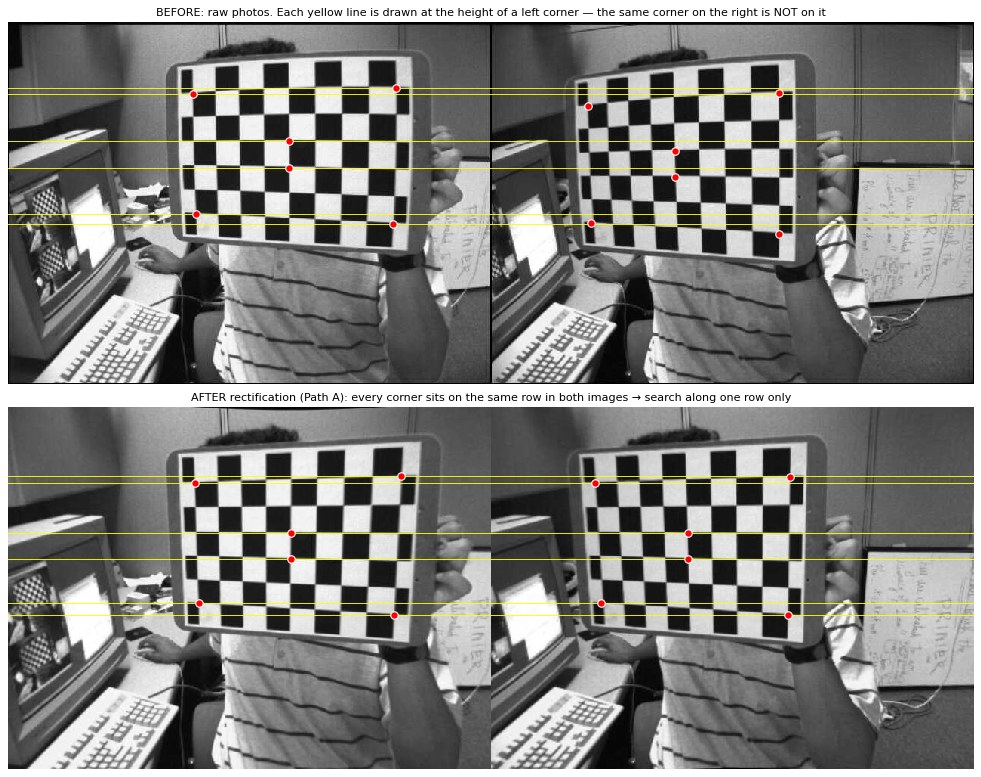

In [15]:
# --- 4.4 🔬 Rectify, then CHECK the rectification (do not assume it worked)  [measured] --------
def build_rectification(R_rel: np.ndarray, T_rel: np.ndarray) -> dict:
    """Rotate both virtual cameras until their image rows coincide. Returns warping maps + the rectified camera model."""
    T_col = np.asarray(T_rel, dtype=np.float64).reshape(3, 1)  # OpenCV 5 is strict: a translation must be a 3x1 column
    R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
        K1, d1, K2, d2, IMG_SIZE, R_rel, T_col, flags=cv2.CALIB_ZERO_DISPARITY, alpha=0
    )
    return {
        "R1": R1,
        "R2": R2,
        "P1": P1,
        "P2": P2,
        "Q": Q,
        "map_l": cv2.initUndistortRectifyMap(K1, d1, R1, P1, IMG_SIZE, cv2.CV_32FC1),
        "map_r": cv2.initUndistortRectifyMap(K2, d2, R2, P2, IMG_SIZE, cv2.CV_32FC1),
        "f": float(P1[0, 0]),
        "baseline": float(-P2[0, 3] / P2[0, 0]),
    }


def rectify_images(rect: dict, gray_l: np.ndarray, gray_r: np.ndarray):
    return (
        cv2.remap(gray_l, rect["map_l"][0], rect["map_l"][1], cv2.INTER_LINEAR),
        cv2.remap(gray_r, rect["map_r"][0], rect["map_r"][1], cv2.INTER_LINEAR),
    )


def rectified_corners(rect: dict, k: int):
    """Where the checkerboard corners of pair k land in the rectified left / right images."""
    c_l = cv2.undistortPoints(CORN_L[k], K1, d1, R=rect["R1"], P=rect["P1"]).reshape(-1, 2)
    c_r = cv2.undistortPoints(CORN_R[k], K2, d2, R=rect["R2"], P=rect["P2"]).reshape(-1, 2)
    return c_l, c_r


def row_misalignment(points_fn) -> np.ndarray:
    """|y_left - y_right| for all 13 x 54 corner pairs. After perfect rectification this is 0."""
    return np.concatenate([np.abs(np.subtract(*points_fn(k))[:, 1]) for k in range(len(CORN_L))])


RECT_A = build_rectification(R_A, T_A)  # Path A: pose from calibration
RECT_B = build_rectification(R_B, t_B * BASELINE_RIG_M)  # Path B: pose from features; baseline LENGTH supplied by us

# Path B': no calibrated pose at all — two homographies computed straight from F
_, H1, H2 = cv2.stereoRectifyUncalibrated(und_l[inl_u], und_r[inl_u], F_und, IMG_SIZE)


def homography_corners(k: int):
    c_l = cv2.perspectiveTransform(undistort_px(CORN_L[k], K1, d1).reshape(-1, 1, 2), H1).reshape(-1, 2)
    c_r = cv2.perspectiveTransform(undistort_px(CORN_R[k], K2, d2).reshape(-1, 1, 2), H2).reshape(-1, 2)
    return c_l, c_r


err_raw = row_misalignment(lambda k: (CORN_L[k].reshape(-1, 2), CORN_R[k].reshape(-1, 2)))
err_A = row_misalignment(lambda k: rectified_corners(RECT_A, k))
err_B = row_misalignment(lambda k: rectified_corners(RECT_B, k))
err_H = row_misalignment(homography_corners)
table(
    [
        ("no rectification (raw photos)", float(err_raw.mean()), float(np.percentile(err_raw, 95))),
        ("Path A   checkerboard stereo calibration", float(err_A.mean()), float(np.percentile(err_A, 95))),
        ("Path B   K + essential matrix from SIFT matches", float(err_B.mean()), float(np.percentile(err_B, 95))),
        ("Path B'  F only, stereoRectifyUncalibrated", float(err_H.mean()), float(np.percentile(err_H, 95))),
    ],
    ["rectification", "mean row error (px)", "95th percentile (px)"],
)
print(f"\nRectified camera (Path A): f = {RECT_A['f']:.1f} px, baseline = {RECT_A['baseline'] * 100:.2f} cm")

RECT_L, RECT_R = rectify_images(RECT_A, GRAY_L[PAIR], GRAY_R[PAIR])
show_k = [0, 8, 22, 31, 45, 53]  # six checkerboard corners to follow by eye
fig, axes = plt.subplots(2, 1, figsize=(13, 9.6), constrained_layout=True)
for ax, pair, (c_l, c_r), title in (
    (
        axes[0],
        np.hstack([GRAY_L[PAIR], GRAY_R[PAIR]]),
        (CORN_L[PAIR].reshape(-1, 2), CORN_R[PAIR].reshape(-1, 2)),
        "BEFORE: raw photos. Each yellow line is drawn at the height of a left corner — "
        "the same corner on the right is NOT on it",
    ),
    (
        axes[1],
        np.hstack([RECT_L, RECT_R]),
        rectified_corners(RECT_A, PAIR),
        "AFTER rectification (Path A): every corner sits on the same row in both images → search along one row only",
    ),
):
    ax.imshow(pair, cmap="gray")
    for i in show_k:
        ax.axhline(c_l[i, 1], color="yellow", lw=0.8)
        ax.scatter(
            [c_l[i, 0], c_r[i, 0] + IMG_SIZE[0]], [c_l[i, 1], c_r[i, 1]], s=45, color="red", edgecolor="white", zorder=3
        )
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Read the result.**
- The epipolar error on held-out corners drops once lens distortion is removed — calibration (Part 3) is a prerequisite, not an extra.
- **Path B works on most pairs and fails completely on a few.** Look at the failing photos: the board covers most of the image.
  *Likely explanation (a hypothesis — Exercise 4 lets you probe it):* points on a single plane do not pin down $E$
  (a plane is fully described by a homography — the forward reference in Day 28 §6.5), and the checkerboard's repeating pattern
  produces confident *wrong* matches.
- Path A's rows line up several times better than Path B's. Same cameras, same photos — the only difference is
  **where the relative pose came from**. Keep this in mind for Part 5: a small pose error will become a depth error.
- An essential matrix gives the translation **direction** only. Metric scale needs one outside measurement
  (here: the baseline length; in practice a ruler, a known object, or GPS/IMU).

⚠️ **Pitfall (§11).** *Confirm rectification quality directly, by inspection, before trusting disparity.*
The table above is that inspection in numbers; the yellow lines are the same check by eye.

✍️ **Exercise 4 (2 min).**
1. Show two of the failing pairs from the table, e.g. `show([GRAY_L[1], GRAY_L[3]])`. What do they have in common?
2. Path A used 13 × 54 = 702 corner pairs, Path B about 250 SIFT inliers from one photo. Give two reasons why Path A is more accurate.
3. In cell 4.1 change the RANSAC threshold from `1.0` to `0.2` and to `5.0` pixels. What happens to the inlier count, and which is riskier?

<details><summary>Show answer</summary>

1. The checkerboard covers almost the whole image, so most keypoints lie on **one plane** and many look alike.
   A planar scene is a *degenerate* configuration for $F$/$E$ estimation. To test this explanation, count for each pair how many
   inlier matches fall inside the board (use the corner hull as in cell 6.1) and compare with the pose error.
2. (i) Corner positions are known to ~0.1 px and their true 3D layout is known; SIFT matches are noisier and some are wrong.
   (ii) Path A combines 13 different board poses spread through the volume; Path B sees one scene once.
3. A tight threshold keeps few, very clean matches (risk: too few points, unstable fit). A loose threshold lets wrong
   matches in (risk: a biased $F$ that still reports many "inliers"). An inlier count is not a quality guarantee —
   always validate on independent points, as we did with the checkerboard corners.

</details>

---
# Part 5 — Stereo matching: disparity → depth → honest evaluation  *(14 min · §4)*

🧠 **Concept.** After rectification a 3D point appears on the **same row** in both images, shifted horizontally.
That shift is the **disparity** $d = u_{\text{left}} - u_{\text{right}}$ (pixels). Similar triangles give

$$ Z = \frac{f \cdot B}{d} \qquad\text{depth (m)} = \frac{\text{focal length (px)} \times \text{baseline (m)}}{\text{disparity (px)}} $$

**Block matching** finds $d$ for every pixel: take a small window around the pixel in the left image, slide it along
the same row of the right image, and keep the shift where the windows look most alike. Storing the similarity score
for *every pixel and every candidate shift* gives the **cost volume** (height × width × disparities).
**Semi-Global Matching (SGM)** adds a smoothness rule: neighbouring pixels should have similar disparity unless the image says otherwise.

**Real data.** Middlebury *Cones* (2003): a rectified pair with ground-truth disparity measured by structured light,
accurate to ¼ pixel. Ground truth is stored ×4; value 0 means *unknown*.

*Needs:* Parts 0, 3 and 4.

Worked example: B = 0.12 m, f = 700 px, d = 28 px  →  Z = 3.00 m
Double the baseline, same disparity:               →  Z = 6.00 m

Depth error caused by a 0.25 px matching mistake:
rig                                                 at 0.5 m  at 2 m  at 10 m  at 30 m
--------------------------------------------------  --------  ------  -------  -------
lecture rig    f=700 px, B=12 cm                    0.7 mm    1.2 cm  29.8 cm  2.68 m 
our desk rig   f=521 px, B=8.4 cm  [measured]       1.4 mm    2.3 cm  57.4 cm  5.17 m 
car-style rig  f=700 px, B=54 cm  [KITTI baseline]  0.2 mm    2.6 mm  6.6 cm   59.5 cm


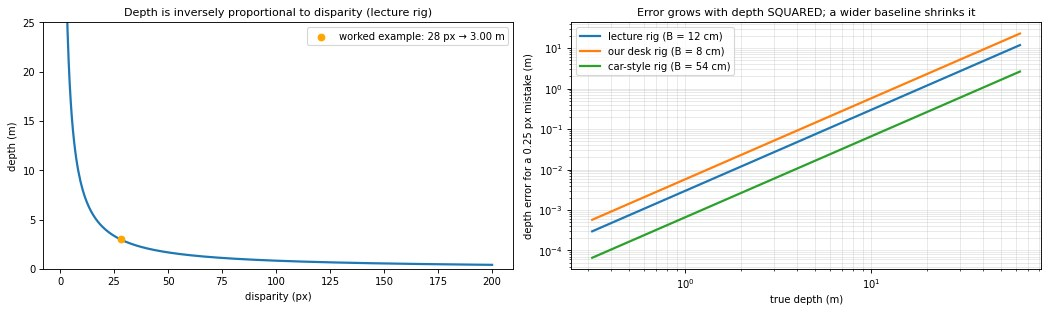

In [16]:
# --- 5.1 The disparity ↔ depth relation, and why far objects are hard  [worked example §4.1] ---
def depth_from_disparity(disparity_px, focal_px: float, baseline_m: float):
    """Z = f * B / d.  Units: pixels * metres / pixels = metres."""
    return focal_px * baseline_m / disparity_px


print(f"Worked example: B = 0.12 m, f = 700 px, d = 28 px  →  Z = {depth_from_disparity(28, 700, 0.12):.2f} m")
print(f"Double the baseline, same disparity:               →  Z = {depth_from_disparity(28, 700, 0.24):.2f} m\n")

# How much does depth change if the measured disparity is off by a quarter pixel?  dZ ≈ Z² / (f·B) · Δd
MATCH_ERROR_PX = 0.25  # [assumed] a typical sub-pixel matching error
rigs = [
    ("lecture rig    f=700 px, B=12 cm", 700.0, 0.12),
    (
        "our desk rig   f=%.0f px, B=%.1f cm  [measured]" % (RECT_A["f"], RECT_A["baseline"] * 100),
        RECT_A["f"],
        RECT_A["baseline"],
    ),
    ("car-style rig  f=700 px, B=54 cm  [KITTI baseline]", 700.0, 0.54),
]
distances = np.array([0.5, 2.0, 10.0, 30.0])


def fmt_len(metres: float) -> str:
    """Human-readable length: mm, cm or m."""
    return (
        f"{metres * 1000:.1f} mm" if metres < 0.01 else (f"{metres * 100:.1f} cm" if metres < 1 else f"{metres:.2f} m")
    )


print(f"Depth error caused by a {MATCH_ERROR_PX} px matching mistake:")
table(
    [(name, *[fmt_len(z * z / (f_px * base) * MATCH_ERROR_PX) for z in distances]) for name, f_px, base in rigs],
    ["rig", *[f"at {z:g} m" for z in distances]],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
d_axis = np.linspace(2, 200, 400)
axes[0].plot(d_axis, depth_from_disparity(d_axis, 700, 0.12), lw=2)
axes[0].scatter([28], [3.0], color="orange", zorder=3, label="worked example: 28 px → 3.00 m")
axes[0].set_xlabel("disparity (px)")
axes[0].set_ylabel("depth (m)")
axes[0].set_ylim(0, 25)
axes[0].set_title("Depth is inversely proportional to disparity (lecture rig)")
axes[0].legend()
z_axis = np.logspace(-0.5, 1.8, 100)
for name, f_px, base in rigs:
    axes[1].loglog(
        z_axis,
        z_axis**2 / (f_px * base) * MATCH_ERROR_PX,
        lw=2,
        label=name.split("  ")[0] + f" (B = {base * 100:.0f} cm)",
    )
axes[1].set_xlabel("true depth (m)")
axes[1].set_ylabel("depth error for a 0.25 px mistake (m)")
axes[1].set_title("Error grows with depth SQUARED; a wider baseline shrinks it")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")
plt.show()

Cones: 450x375 px, true disparities 5.5–55.0 px, 96.8% of pixels have ground truth
3 cost volumes of shape (375, 450, 64) + winner-takes-all: 0.71 s


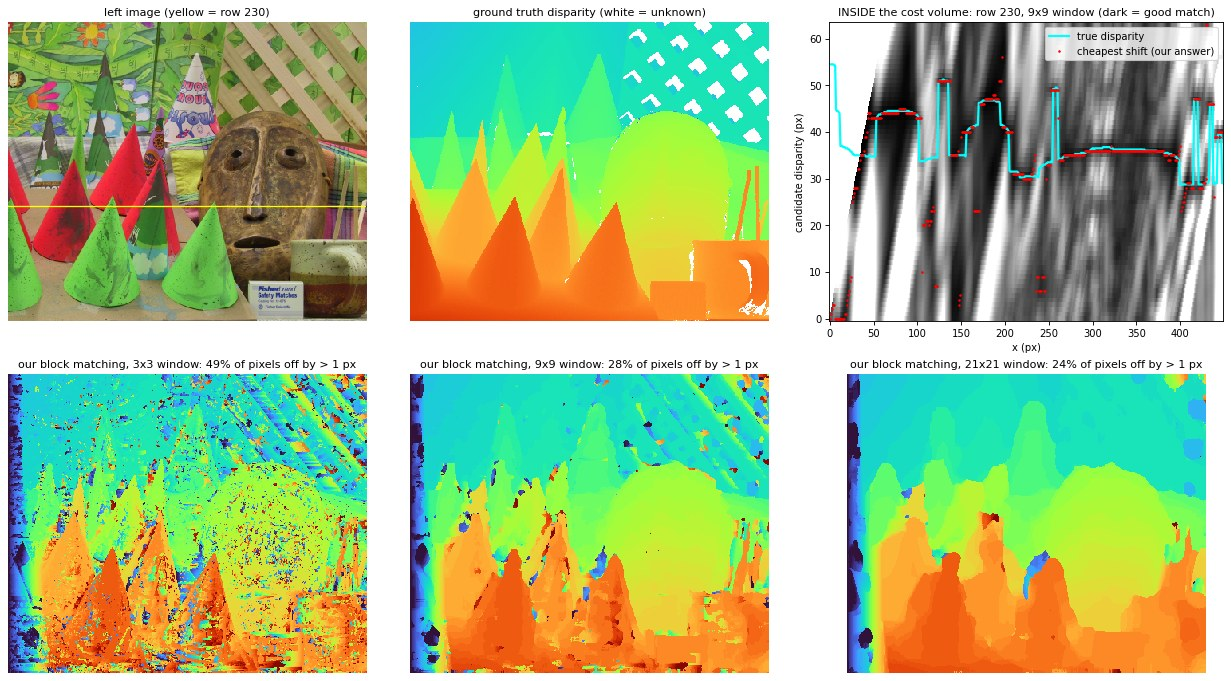

In [17]:
# --- 5.2 🔬 Block matching from scratch: build a cost volume in 10 lines  [measured] ------------
def load_middlebury(scene: str):
    """Returns (left RGB, right RGB, left ground-truth disparity in px, right ground truth). 0 = unknown."""
    folder = DATA / "middlebury" / scene
    gt_l = imread_gray(folder / "disp2.png").astype(np.float32) / 4.0  # stored x4 (quarter-pixel accuracy)
    gt_r = imread_gray(folder / "disp6.png").astype(np.float32) / 4.0
    return imread_rgb(folder / "im2.png"), imread_rgb(folder / "im6.png"), gt_l, gt_r


def sad_cost_volume(left: np.ndarray, right: np.ndarray, max_disp: int, block: int) -> np.ndarray:
    """cost[y, x, d] = mean |left window at (y, x)  -  right window at (y, x - d)|.  Lower = more similar."""
    h, w = left.shape
    L, R = left.astype(np.float32), right.astype(np.float32)
    cost = np.full((h, w, max_disp), np.inf, np.float32)
    for d in range(max_disp):
        diff = np.abs(L[:, d:] - R[:, : w - d])  # compare every pixel with the one d to its left
        cost[:, d:, d] = cv2.blur(diff, (block, block))  # averaging over the window = block matching
    return cost


cones_l, cones_r, cones_gt, cones_gt_r = load_middlebury("cones")
cones_gl, cones_gr = cv2.cvtColor(cones_l, cv2.COLOR_RGB2GRAY), cv2.cvtColor(cones_r, cv2.COLOR_RGB2GRAY)
MAX_DISP = 64  # ground truth goes up to 55 px
gt_known = cones_gt > 0
print(
    f"Cones: {cones_l.shape[1]}x{cones_l.shape[0]} px, "
    f"true disparities {cones_gt[gt_known].min():.1f}–{cones_gt[gt_known].max():.1f} px, "
    f"{gt_known.mean():.1%} of pixels have ground truth"
)

t0 = time.time()
scratch = {}
for block in (3, 9, 21):
    cost = sad_cost_volume(cones_gl, cones_gr, MAX_DISP, block)
    scratch[block] = cost.argmin(axis=2).astype(np.float32)  # winner takes all: the cheapest shift per pixel
    if block == 9:
        cost_9 = cost  # keep one volume to look inside
print(f"3 cost volumes of shape {cones_gl.shape + (MAX_DISP,)} + winner-takes-all: {time.time() - t0:.2f} s")

ROW_Y = 230  # the image row whose cost slice we display
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.4), constrained_layout=True)
axes[0, 0].imshow(cones_l)
axes[0, 0].axhline(ROW_Y, color="yellow", lw=1.2)
axes[0, 0].set_title(f"left image (yellow = row {ROW_Y})")
axes[0, 0].axis("off")
axes[0, 1].imshow(np.where(gt_known, cones_gt, np.nan), cmap="turbo", vmin=0, vmax=MAX_DISP)
axes[0, 1].set_title("ground truth disparity (white = unknown)")
axes[0, 1].axis("off")
slice_9 = cost_9[ROW_Y].T  # (disparity, x)
axes[0, 2].imshow(
    slice_9, aspect="auto", origin="lower", cmap="gray", vmax=np.percentile(slice_9[np.isfinite(slice_9)], 90)
)
axes[0, 2].plot(np.where(gt_known[ROW_Y], cones_gt[ROW_Y], np.nan), color="cyan", lw=2, label="true disparity")
axes[0, 2].plot(scratch[9][ROW_Y], ".", color="red", ms=2.5, label="cheapest shift (our answer)")
axes[0, 2].set_xlabel("x (px)")
axes[0, 2].set_ylabel("candidate disparity (px)")
axes[0, 2].legend(loc="upper right")
axes[0, 2].set_title(f"INSIDE the cost volume: row {ROW_Y}, 9x9 window (dark = good match)")
for ax, (block, disp) in zip(axes[1], scratch.items()):
    bad = np.mean(np.abs(disp - cones_gt)[gt_known] > 1.0)
    ax.imshow(disp, cmap="turbo", vmin=0, vmax=MAX_DISP)
    ax.set_title(f"our block matching, {block}x{block} window: {bad:.0%} of pixels off by > 1 px")
    ax.axis("off")
plt.show()

method                    density  mean err px  median px  bad > 1 px  bad (visible)  bad (occluded)
------------------------  -------  -----------  ---------  ----------  -------------  --------------
ours: block matching 9x9  100 %    3.655        0.5        27.9 %      18.8 %         93.7 %        
OpenCV StereoBM 15x15     73 %     0.6192       0.125      6.0 %       3.9 %          74.3 %        
OpenCV StereoSGBM 5x5     83 %     0.6453       0.1875     6.6 %       3.8 %          78.6 %        

runtime: StereoBM 22 ms, StereoSGBM 127 ms   |   12.1% of the pixels are seen by the left camera only ('occluded')
SGBM mean error if unmatched pixels are (wrongly) scored as disparity 0: 6.15 px   vs. 0.65 px on the pixels it actually answered


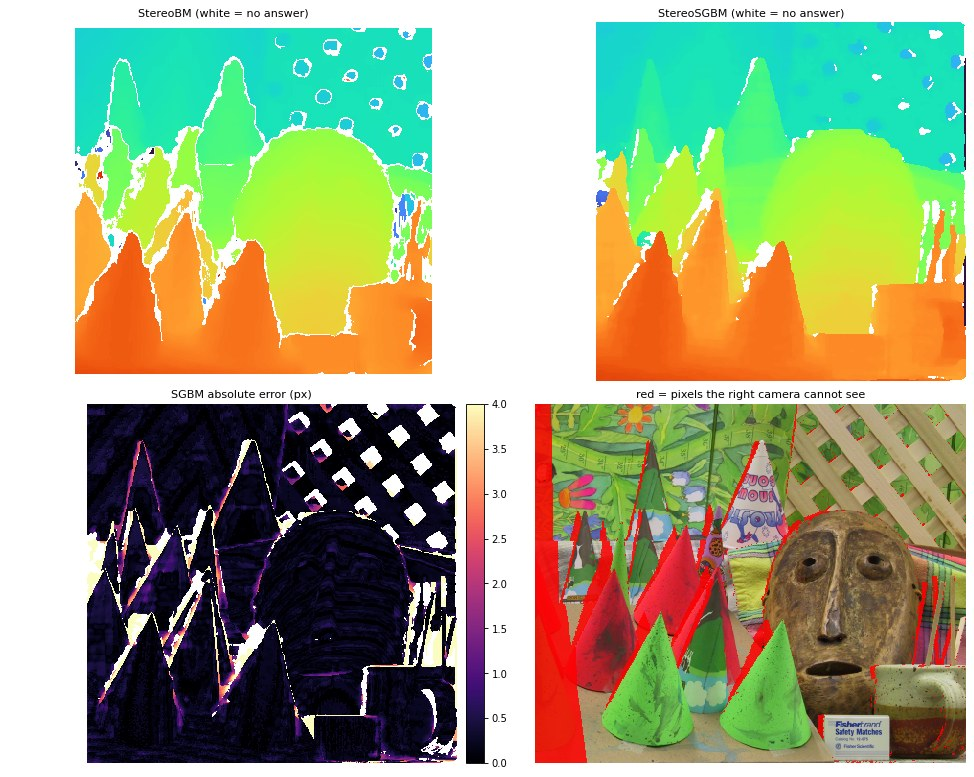

In [18]:
# --- 5.3 🔬 OpenCV's StereoBM and SGBM, and how to score them fairly  [measured] ----------------
def run_sgbm(left: np.ndarray, right: np.ndarray, num_disp: int, block: int = 5) -> np.ndarray:
    """Semi-Global Block Matching. Returns disparity in pixels (float32); negative = 'no confident match'."""
    channels = 1 if left.ndim == 2 else 3
    matcher = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=num_disp,
        blockSize=block,
        P1=8 * channels * block**2,
        P2=32 * channels * block**2,  # smoothness penalties
        disp12MaxDiff=1,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    return matcher.compute(left, right).astype(np.float32) / 16.0  # OpenCV returns fixed-point values x16


def occlusion_mask(gt_left: np.ndarray, gt_right: np.ndarray, tol: float = 1.0) -> np.ndarray:
    """True where a left pixel is NOT visible in the right image, found by cross-checking the two ground-truth maps."""
    h, w = gt_left.shape
    ys, xs = np.mgrid[0:h, 0:w]
    x_right = np.round(xs - gt_left).astype(int)
    inside = (x_right >= 0) & (gt_left > 0)
    back = np.zeros_like(gt_left)
    back[inside] = gt_right[ys[inside], x_right[inside]]
    return (gt_left > 0) & (~inside | (np.abs(back - gt_left) > tol))


def score(disp: np.ndarray, pred_valid: np.ndarray, gt: np.ndarray, region: np.ndarray) -> dict:
    """Compare a disparity map with ground truth inside `region`, ONLY where the method gave an answer (§4.3)."""
    use = region & pred_valid
    err = np.abs(disp[use] - gt[use])
    return {
        "density": 100 * use.sum() / region.sum(),
        "mae": float(err.mean()),
        "median": float(np.median(err)),
        "bad1": 100 * float(np.mean(err > 1.0)),
    }


cones_occ = occlusion_mask(cones_gt, cones_gt_r)
cones_vis = gt_known & ~cones_occ

t0 = time.time()
bm_raw = (
    cv2.StereoBM_create(numDisparities=MAX_DISP, blockSize=15).compute(cones_gl, cones_gr).astype(np.float32) / 16.0
)
t_bm = time.time() - t0
t0 = time.time()
cones_sgbm = run_sgbm(cones_l, cones_r, MAX_DISP)
t_sgbm = time.time() - t0

methods = {
    "ours: block matching 9x9": (scratch[9], np.ones_like(gt_known)),
    "OpenCV StereoBM 15x15": (bm_raw, bm_raw >= 0),
    "OpenCV StereoSGBM 5x5": (cones_sgbm, cones_sgbm >= 0),
}
rows = []
for name, (disp, valid) in methods.items():
    s_all, s_vis, s_occ = (score(disp, valid, cones_gt, r) for r in (gt_known, cones_vis, cones_occ))
    rows.append(
        (
            name,
            f"{s_all['density']:.0f} %",
            s_all["mae"],
            s_all["median"],
            f"{s_all['bad1']:.1f} %",
            f"{s_vis['bad1']:.1f} %",
            f"{s_occ['bad1']:.1f} %",
        )
    )
table(rows, ["method", "density", "mean err px", "median px", "bad > 1 px", "bad (visible)", "bad (occluded)"])
print(
    f"\nruntime: StereoBM {t_bm * 1000:.0f} ms, StereoSGBM {t_sgbm * 1000:.0f} ms   |   "
    f"{cones_occ.sum() / gt_known.sum():.1%} of the pixels are seen by the left camera only ('occluded')"
)

# ⚠️ The unfair way to score: treat "no answer" as the answer 0 and count it as an error
naive = np.abs(np.where(cones_sgbm >= 0, cones_sgbm, 0)[gt_known] - cones_gt[gt_known]).mean()
print(
    f"SGBM mean error if unmatched pixels are (wrongly) scored as disparity 0: {naive:.2f} px   "
    f"vs. {rows[2][2]:.2f} px on the pixels it actually answered"
)

err_map = np.where((cones_sgbm >= 0) & gt_known, np.abs(cones_sgbm - cones_gt), np.nan)
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.6), constrained_layout=True)
axes = axes.ravel()
axes[0].imshow(np.where(bm_raw >= 0, bm_raw, np.nan), cmap="turbo", vmin=0, vmax=MAX_DISP)
axes[0].set_title("StereoBM (white = no answer)")
axes[1].imshow(np.where(cones_sgbm >= 0, cones_sgbm, np.nan), cmap="turbo", vmin=0, vmax=MAX_DISP)
axes[1].set_title("StereoSGBM (white = no answer)")
handle = axes[2].imshow(err_map, cmap="magma", vmin=0, vmax=4)
axes[2].set_title("SGBM absolute error (px)")
fig.colorbar(handle, ax=axes[2], fraction=0.046, pad=0.02)
overlay = np.zeros(cones_occ.shape + (4,))
overlay[cones_occ] = (1.0, 0.0, 0.0, 0.85)
axes[3].imshow(cones_l)
axes[3].imshow(overlay)
axes[3].set_title("red = pixels the right camera cannot see")
for ax in axes:
    ax.axis("off")
plt.show()

Board corners of pair 01: depth from our disparity map vs. the board position from PnP (same SGBM settings in every row)
rectification used                          corners matched  true board depth  median depth error  relative
------------------------------------------  ---------------  ----------------  ------------------  --------
Path A  pose from checkerboard calibration  51/54            0.384 m           0.6 mm              0.16 %  
Path A  same, calibrated WITHOUT this pair  52/54            0.384 m           0.6 mm              0.17 %  
Path B  pose from SIFT matches              46/54            0.383 m           21.6 mm             5.49 %  

Path B's disparities at the corners differ from Path A's by a nearly constant -5.9 px. The same -5.9 px at other distances would give:
true depth  true disparity  depth Path B would report
----------  --------------  -------------------------
0.4 m       108.9 px        0.42 m                   
1 m         43.6 px         1.16 m       

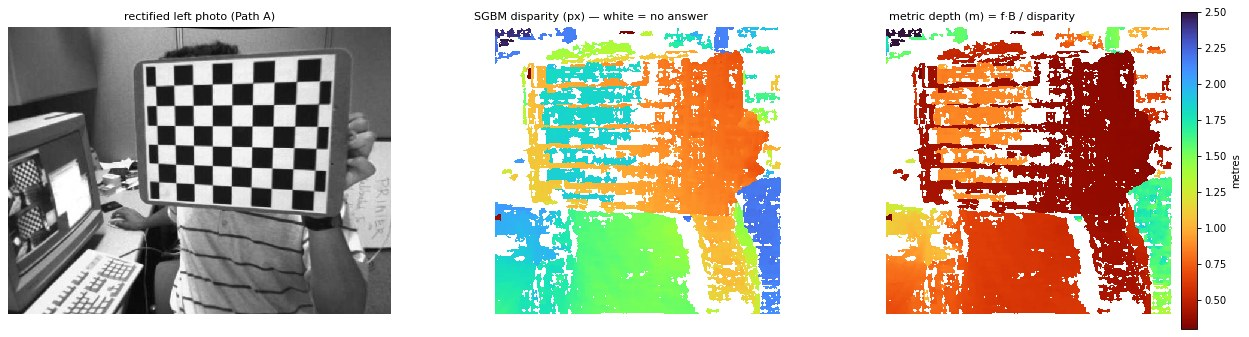

In [19]:
# --- 5.4 🔬🌍 Disparity → METRIC depth on our own rig, checked against a known distance ---------
NUM_DISP_RIG = 160  # the board is ~0.4 m away → disparities above 100 px, so the search range must be large


def board_depth_check(rect: dict, k: int, disp: np.ndarray):
    """Depth of the 54 board corners: reference (board pose from PnP, independent of stereo) vs. our disparity map."""
    _, rvec, tvec = cv2.solvePnP(BOARD_PTS, CORN_L[k], K1, d1)
    corners_cam = cv2.Rodrigues(rvec)[0] @ BOARD_PTS.T + tvec.reshape(3, 1)  # corners in the left camera frame (m)
    z_ref = (rect["R1"] @ corners_cam)[2]  # depth along the RECTIFIED camera axis
    c_l, c_r = rectified_corners(rect, k)
    u, v = np.round(c_l).astype(int).T
    inside = (u >= 0) & (u < disp.shape[1]) & (v >= 0) & (v < disp.shape[0])
    d = np.full(len(u), np.nan)
    d[inside] = disp[v[inside], u[inside]]
    d[d <= 0] = np.nan  # unmatched → no depth, not "depth 0"
    return z_ref, depth_from_disparity(d, rect["f"], rect["baseline"]), c_l[:, 0] - c_r[:, 0]


# Fair test for Path A: calibrate the stereo pose again WITHOUT this pair, then test on it (held-out validation)
others = [k for k in range(len(CORN_L)) if k != PAIR]
held = cv2.stereoCalibrate(
    [BOARD_PTS] * len(others),
    [CORN_L[k] for k in others],
    [CORN_R[k] for k in others],
    K1,
    d1,
    K2,
    d2,
    IMG_SIZE,
    flags=cv2.CALIB_FIX_INTRINSIC,
)
RECT_HELD = build_rectification(held[5], held[6])

results = {}
for label, rect in (("A", RECT_A), ("A-held", RECT_HELD), ("B", RECT_B)):
    rl, rr = rectify_images(rect, GRAY_L[PAIR], GRAY_R[PAIR])
    disp = run_sgbm(rl, rr, NUM_DISP_RIG)
    z_ref, z_est, d_geo = board_depth_check(rect, PAIR, disp)
    results[label] = {
        "left": rl,
        "disp": disp,
        "z_ref": z_ref,
        "z_est": z_est,
        "d_geo": d_geo,
        "depth": np.where(disp > 0, depth_from_disparity(np.maximum(disp, 1e-6), rect["f"], rect["baseline"]), np.nan),
    }

rows = []
for label, name in (
    ("A", "Path A  pose from checkerboard calibration"),
    ("A-held", "Path A  same, calibrated WITHOUT this pair"),
    ("B", "Path B  pose from SIFT matches"),
):
    r = results[label]
    err_mm = 1000 * np.abs(r["z_est"] - r["z_ref"])
    rows.append(
        (
            name,
            f"{np.sum(~np.isnan(err_mm))}/54",
            f"{np.nanmean(r['z_ref']):.3f} m",
            f"{np.nanmedian(err_mm):.1f} mm",
            f"{100 * np.nanmedian(err_mm / (1000 * r['z_ref'])):.2f} %",
        )
    )
print(
    f"Board corners of pair {PAIR_IDS[PAIR]}: depth from our disparity map vs. the board position from PnP "
    "(same SGBM settings in every row)"
)
table(rows, ["rectification used", "corners matched", "true board depth", "median depth error", "relative"])

# Where does Path B's extra error come from? Its slightly wrong rotation shifts every disparity by a constant.
offset_px = float(np.median(results["B"]["d_geo"] - results["A"]["d_geo"]))
fB = RECT_A["f"] * RECT_A["baseline"]
print(
    f"\nPath B's disparities at the corners differ from Path A's by a nearly constant {offset_px:+.1f} px. "
    f"The same {offset_px:+.1f} px at other distances would give:"
)
table(
    [
        (
            f"{z:g} m",
            f"{fB / z:.1f} px",
            f"{fB / (fB / z + offset_px):.2f} m" if fB / z + offset_px > 0 else "behind infinity (invalid)",
        )
        for z in (0.4, 1.0, 2.0, 4.0)
    ],
    ["true depth", "true disparity", "depth Path B would report"],
)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.1), constrained_layout=True)
axes[0].imshow(results["A"]["left"], cmap="gray")
axes[0].set_title("rectified left photo (Path A)")
axes[1].imshow(np.where(results["A"]["disp"] > 0, results["A"]["disp"], np.nan), cmap="turbo")
axes[1].set_title("SGBM disparity (px) — white = no answer")
handle = axes[2].imshow(results["A"]["depth"], cmap="turbo_r", vmin=0.3, vmax=2.5)
axes[2].set_title("metric depth (m) = f·B / disparity")
fig.colorbar(handle, ax=axes[2], fraction=0.046, pad=0.02, label="metres")
for ax in axes:
    ax.axis("off")
plt.show()

**Read the result.**
- **Window size is a trade-off:** 3×3 is noisy, 21×21 is smooth but fattens edges. No single window is right everywhere.
- **Our 10-line matcher answers every pixel and is often wrong; StereoBM / SGBM refuse to answer where they are unsure**
  and are far more accurate on what they keep. *Density and accuracy must always be reported together.*
- **Occlusion is a property of the scene:** on pixels only the left camera can see, every method is wrong most of the time —
  there is simply nothing to match (§5.1).
- **Scoring unmatched pixels as "disparity 0" inflates the error roughly tenfold** and punishes a method for honestly saying "I don't know" (§4.3, §11).
- **Metric check on a real rig:** with Path A the stereo depth of the board agrees with the board position from PnP to about a millimetre —
  and it still does when this pair is left out of the stereo calibration (the held-out row; without it the agreement could be self-fulfilling).
  Path B — same images, same matcher — is off by centimetres, and the range table shows the same pixel offset becoming *metres* further away.
  **Calibration and rectification error is not disparity-estimation error.** PP17 asks you to separate exactly these.
  *Limit of this check:* the PnP reference uses the same intrinsics $K$, so it tests pose, rectification and matching — not $K$ itself.
- Look at the checkerboard in the disparity map: stripes of wrong values. A repeating pattern is the best calibration target and the worst stereo texture (next part).

🌍 **Real world.** A desk rig with an 8 cm baseline is useless at 30 m; a car needs half a metre between its cameras (KITTI: ≈ 54 cm).
The baseline is a design decision that follows from the working distance — use the error formula above to choose it.

⚠️ **Pitfalls (§11).** Units: baseline in **metres**, focal length and disparity in **pixels**. Published benchmark numbers come from
tuned or learned methods; expect yours to be worse — compare your own methods with each other under identical conditions.

teddy, block 5, 64 disparities → density 81 %, mean error 0.78 px, bad > 1 px: 9.9 %  (true max disparity: 52.8 px)


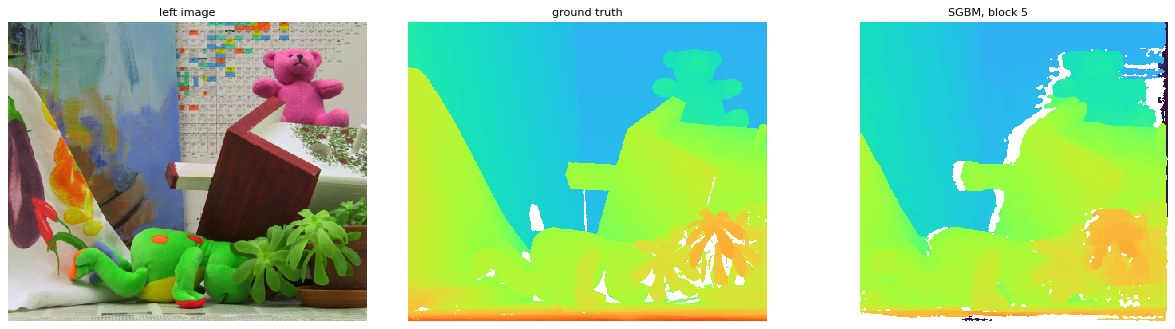

In [20]:
# --- ✍️ Exercise 5 playground: change the three values, re-run, watch density and error --------
SCENE, BLOCK, NUM_DISP = "teddy", 5, 64  # try: BLOCK = 3, 11, 21   |   NUM_DISP = 32 (too small!)   |   SCENE = "cones"

ex_l, ex_r, ex_gt, ex_gt_r = load_middlebury(SCENE)
ex_disp = run_sgbm(ex_l, ex_r, NUM_DISP, BLOCK)
ex_known = ex_gt > 0
ex_score = score(ex_disp, ex_disp >= 0, ex_gt, ex_known)
print(
    f"{SCENE}, block {BLOCK}, {NUM_DISP} disparities → density {ex_score['density']:.0f} %, "
    f"mean error {ex_score['mae']:.2f} px, bad > 1 px: {ex_score['bad1']:.1f} %  (true max disparity: {ex_gt.max():.1f} px)"
)
show(
    [ex_l, np.where(ex_known, ex_gt, np.nan), np.where(ex_disp >= 0, ex_disp, np.nan)],
    ["left image", "ground truth", f"SGBM, block {BLOCK}"],
    cmap=[None, "turbo", "turbo"],
    vmin=0,
    vmax=64,
    figsize=(15, 4),
)

✍️ **Exercise 5 (3 min).** Use the playground cell above.
1. Set `NUM_DISP = 32`. The density stays reasonable but the error explodes. Why? (Compare with the true maximum disparity.)
2. Try `BLOCK = 3` and `BLOCK = 21`. Which gives higher density? Which gives sharper object edges?
3. Our desk rig needed `NUM_DISP_RIG = 160` although its images are only 640 px wide. Explain with $d = fB/Z$,
   and name the price we pay for such a large search range.

<details><summary>Show answer</summary>

1. Objects closer than the range allows have true disparities above 32 px. The matcher cannot output the right answer,
   so it returns the best *wrong* one inside the range. Always set the range from the nearest object you expect: $d_{max} = fB/Z_{min}$.
2. Large blocks give smoother, denser maps but blur depth edges ("foreground fattening"); small blocks keep edges and leave more holes and noise.
3. The board is only ≈ 0.4 m away: $d = 521 \times 0.084 / 0.4 \approx 110$ px. Price: a strip as wide as the search range on the
   left of the image can never be matched, and run time and the risk of false matches grow with the range.

</details>

---
# Part 6 — From classical to learned depth: failure modes and monocular depth  *(7 min · §5)*

🧠 **Concept.** Block matching assumes that a window is *recognisable*: it looks like its true partner and unlike
everything else on the row. Three situations break that assumption (§5.1):

| Failure mode | Why matching fails | Real-world example |
|---|---|---|
| **Textureless** region | every shift looks the same → no minimum | white wall, clear sky, road surface |
| **Repetitive** pattern | several shifts look equally right → wrong minimum | fence, brick wall, windows of a facade |
| **Occlusion** | the true partner is hidden in the other view → no correct answer exists | anything behind an object's edge |

Learned stereo networks soften the first two with context. **Monocular** networks go further and predict depth from
**one** image — which geometry says is impossible (Part 1). They can only do it by *recalling what scenes usually look like*.

*Needs:* Parts 0, 3, 4 and 5.

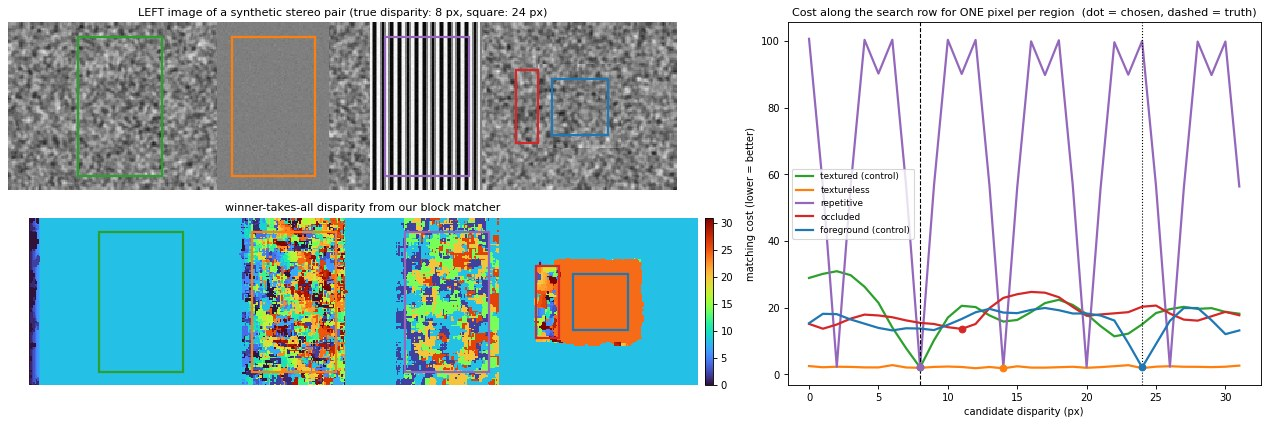

region                true disparity  pixels wrong by > 1 px
--------------------  --------------  ----------------------
textured (control)    8 px            0 %                   
textureless           8 px            90 %                  
repetitive            8 px            74 %                  
occluded              8 px            92 %                  
foreground (control)  24 px           0 %                   

Real checkerboard (pair 01, 46268 pixels): SGBM gave no answer for 27 % of the board, and 43 % of its answers are wrong by more than 2 px.


In [21]:
# --- 6.1 🔬 The three failure modes under controlled conditions  [simulated], then in the wild [measured] ---
rng_fm = np.random.default_rng(SEED)
FH, FW, D_BG, D_FG, BLOCK_FM = 120, 480, 8, 24, 7
STRIPE_PERIOD = 6  # px — ✍️ Exercise 6 asks you to change this

# One flat background surface (disparity 8) carrying three kinds of texture, plus a square floating in front (disparity 24)
surface = cv2.GaussianBlur(rng_fm.normal(128, 60, (FH, FW)).astype(np.float32), (0, 0), 1.0)
surface[:, 150:230] = 128.0  # textureless patch
surface[:, 260:340] = 128.0 + 90.0 * np.sin(2 * np.pi * np.arange(260, 340) / STRIPE_PERIOD)  # stripes that repeat
square = cv2.GaussianBlur(rng_fm.normal(128, 60, (60, 60)).astype(np.float32), (0, 0), 1.0)

fm_left, fm_right = surface.copy(), np.roll(surface, -D_BG, axis=1)  # right(x) = left(x + d)
fm_left[30:90, 380:440] = square
fm_right[30:90, 380 - D_FG : 440 - D_FG] = square
fm_left += rng_fm.normal(0, 2, fm_left.shape)  # a little independent sensor noise in each camera
fm_right += rng_fm.normal(0, 2, fm_right.shape)
fm_gt = np.full((FH, FW), float(D_BG))
fm_gt[30:90, 380:440] = D_FG

# name: (x0, x1, y0, y1, colour).  The occluded strip is background that the square hides from the RIGHT camera.
REGIONS = {
    "textured (control)": (50, 110, 10, 110, "tab:green"),
    "textureless": (160, 220, 10, 110, "tab:orange"),
    "repetitive": (270, 330, 10, 110, "tab:purple"),
    "occluded": (380 - (D_FG - D_BG), 380, 34, 86, "tab:red"),
    "foreground (control)": (390, 430, 40, 80, "tab:blue"),
}

fm_cost = sad_cost_volume(fm_left, fm_right, 32, BLOCK_FM)  # the same function you wrote in Part 5
fm_disp = fm_cost.argmin(axis=2).astype(np.float32)

fig, axd = plt.subplot_mosaic(
    [["img", "curves"], ["disp", "curves"]],
    figsize=(16, 5.2),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1.5, 1]},
)
axd["img"].imshow(fm_left, cmap="gray")
axd["img"].set_title("LEFT image of a synthetic stereo pair (true disparity: 8 px, square: 24 px)")
handle = axd["disp"].imshow(fm_disp, cmap="turbo", vmin=0, vmax=31)
axd["disp"].set_title("winner-takes-all disparity from our block matcher")
fig.colorbar(handle, ax=axd["disp"], fraction=0.02, pad=0.01)
rows = []
for name, (x0, x1, y0, y1, colour) in REGIONS.items():
    for key in ("img", "disp"):
        axd[key].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=colour, lw=2))
    wrong = np.abs(fm_disp[y0:y1, x0:x1] - fm_gt[y0:y1, x0:x1]) > 1
    rows.append((name, f"{fm_gt[(y0 + y1) // 2, (x0 + x1) // 2]:.0f} px", f"{100 * wrong.mean():.0f} %"))
    curve = fm_cost[(y0 + y1) // 2, (x0 + x1) // 2]
    axd["curves"].plot(curve, color=colour, lw=2, label=name)
    axd["curves"].scatter([int(curve.argmin())], [curve.min()], color=colour, zorder=3)
axd["curves"].axvline(D_BG, color="k", ls="--", lw=1)
axd["curves"].axvline(D_FG, color="k", ls=":", lw=1)
axd["curves"].set_xlabel("candidate disparity (px)")
axd["curves"].set_ylabel("matching cost (lower = better)")
axd["curves"].set_title("Cost along the search row for ONE pixel per region  (dot = chosen, dashed = truth)")
axd["curves"].legend(fontsize=8)
for key in ("img", "disp"):
    axd[key].axis("off")
plt.show()
table(rows, ["region", "true disparity", "pixels wrong by > 1 px"])

# The same failure in the wild: the checkerboard in our real disparity map (Part 5.4) is a repetitive pattern.
# A flat board has a disparity that is an exact linear function of (u, v), so 54 corners give ground truth for every board pixel.
c_l, c_r = rectified_corners(RECT_A, PAIR)
plane, *_ = np.linalg.lstsq(np.c_[c_l, np.ones(len(c_l))], c_l[:, 0] - c_r[:, 0], rcond=None)
board_mask = np.zeros(RECT_L.shape, np.uint8)
cv2.fillConvexPoly(board_mask, cv2.convexHull(np.round(c_l).astype(np.int32).reshape(-1, 1, 2)), 1)
vv, uu = np.nonzero(board_mask)
d_board, d_true = results["A"]["disp"][vv, uu], plane[0] * uu + plane[1] * vv + plane[2]
answered = d_board > 0
print(
    f"\nReal checkerboard (pair {PAIR_IDS[PAIR]}, {len(uu)} pixels): "
    f"SGBM gave no answer for {100 * (~answered).mean():.0f} % of the board, "
    f"and {100 * np.mean(np.abs(d_board - d_true)[answered] > 2):.0f} % of its answers are wrong by more than 2 px."
)

MiDaS raw output range: 132 … 920 (no unit — not pixels, not metres), 376 ms on CPU

method on Cones                           density  mean err px  bad > 1 px  help it received                        
----------------------------------------  -------  -----------  ----------  ----------------------------------------
stereo  SGBM (two images, geometry)       83 %     0.6453       7 %         none                                    
mono    MiDaS-small (one image, learned)  100 %    5.364        90 %        scale + shift fitted to the ground truth
correlation between MiDaS output and true disparity: 0.79


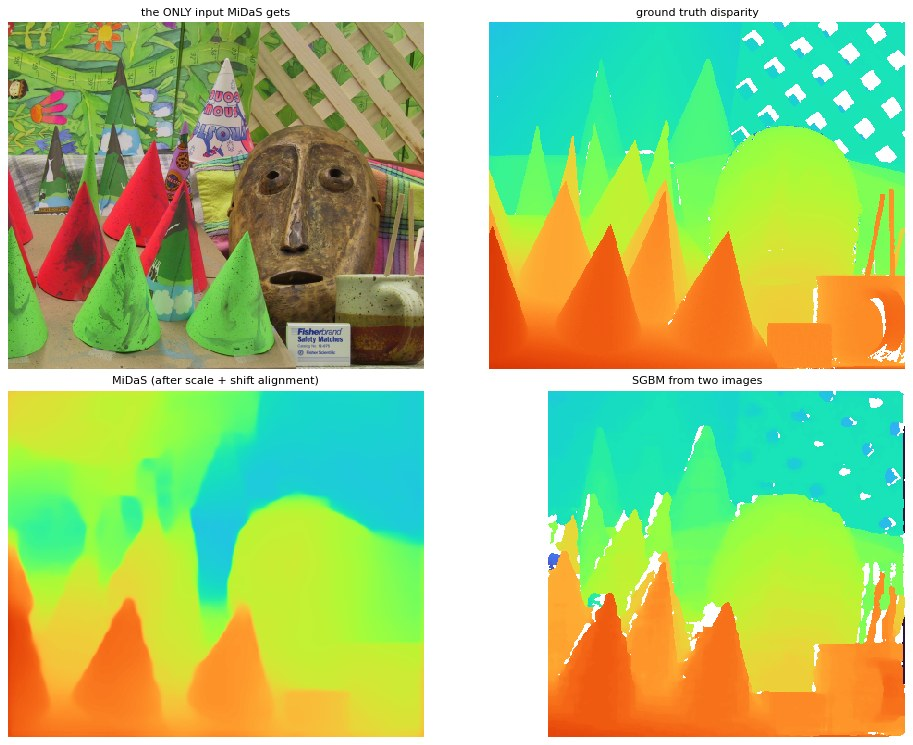

In [22]:
# --- 6.2 🔬 Monocular depth with a real pretrained network (MiDaS v2.1-small, 67 MB, MIT licence) ---
MIDAS_URL = "https://github.com/isl-org/MiDaS/releases/download/v2_1/model-small.onnx"
HAVE_MIDAS = fetch("models/midas_v21_small.onnx", MIDAS_URL)
if HAVE_MIDAS:
    try:
        MIDAS_NET = cv2.dnn.readNet(
            str(DATA / "models/midas_v21_small.onnx")
        )  # runs on CPU through OpenCV, no PyTorch needed
    except cv2.error as exc:
        HAVE_MIDAS = False
        print("Could not load the model with this OpenCV build:", str(exc).splitlines()[0])
if not HAVE_MIDAS:
    print("MiDaS is not available → cells 6.2 and 6.3 will be skipped. The rest of the notebook does not depend on it.")

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def midas_inverse_depth(rgb: np.ndarray) -> np.ndarray:
    """ONE RGB image in → relative INVERSE depth out (larger = closer). Scale and offset are arbitrary."""
    x = cv2.resize(rgb.astype(np.float32) / 255.0, (256, 256), interpolation=cv2.INTER_CUBIC)
    x = ((x - IMAGENET_MEAN) / IMAGENET_STD).transpose(2, 0, 1)[None]
    MIDAS_NET.setInput(np.ascontiguousarray(x, dtype=np.float32))
    out = np.squeeze(MIDAS_NET.forward())
    return cv2.resize(out, (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_CUBIC)


def align_to(pred: np.ndarray, target: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Best scale and shift (least squares) that map `pred` onto `target`. NOTE: this step needs the ground truth!"""
    (scale, shift), *_ = np.linalg.lstsq(np.c_[pred[mask], np.ones(mask.sum())], target[mask], rcond=None)
    return scale * pred + shift


if HAVE_MIDAS:
    t0 = time.time()
    mono_raw = midas_inverse_depth(cones_l)  # only the LEFT image is used
    t_mono = time.time() - t0
    mono = align_to(mono_raw, cones_gt, gt_known)
    s_mono = score(mono, np.ones_like(gt_known), cones_gt, gt_known)
    s_sgbm = score(cones_sgbm, cones_sgbm >= 0, cones_gt, gt_known)
    print(
        f"MiDaS raw output range: {mono_raw.min():.0f} … {mono_raw.max():.0f} (no unit — not pixels, not metres), "
        f"{t_mono * 1000:.0f} ms on CPU\n"
    )
    table(
        [
            (
                "stereo  SGBM (two images, geometry)",
                f"{s_sgbm['density']:.0f} %",
                s_sgbm["mae"],
                f"{s_sgbm['bad1']:.0f} %",
                "none",
            ),
            (
                "mono    MiDaS-small (one image, learned)",
                f"{s_mono['density']:.0f} %",
                s_mono["mae"],
                f"{s_mono['bad1']:.0f} %",
                "scale + shift fitted to the ground truth",
            ),
        ],
        ["method on Cones", "density", "mean err px", "bad > 1 px", "help it received"],
    )
    print(
        "correlation between MiDaS output and true disparity: "
        f"{np.corrcoef(mono_raw[gt_known], cones_gt[gt_known])[0, 1]:.2f}"
    )
    show(
        [cones_l, np.where(gt_known, cones_gt, np.nan), mono, np.where(cones_sgbm >= 0, cones_sgbm, np.nan)],
        [
            "the ONLY input MiDaS gets",
            "ground truth disparity",
            "MiDaS (after scale + shift alignment)",
            "SGBM from two images",
        ],
        cmap=[None, "turbo", "turbo", "turbo"],
        vmin=0,
        vmax=MAX_DISP,
        cols=2,
        figsize=(12, 9.2),
    )

                                                      upright  upside-down  mirrored (control)
----------------------------------------------------  -------  -----------  ------------------
MiDaS on cones: correlation with truth                0.7941   0.5311       0.7045            
MiDaS on teddy: correlation with truth                0.8956   0.68         0.9141            
block matching on cones: pixels with the SAME answer  1        1            —                 

Poster test — stereo: disparity 20.0 px everywhere (std 0.02 px) → 'this is flat'.
              mono:   predicts 17–55 px of depth relief, exactly as for the real scene — it never saw the second image.


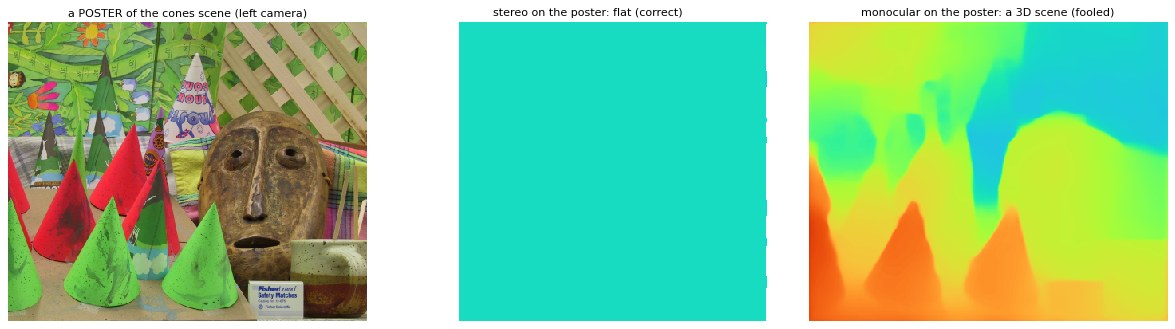

In [23]:
# --- 6.3 🔬 Is it geometry or memory? Two experiments on the monocular model  [measured] --------
if HAVE_MIDAS:
    # Experiment 1 — turn the photo upside-down. The 3D scene is unchanged, so a geometric method must not care.
    rows = []
    for scene in ("cones", "teddy"):
        img, _, gt, _ = load_middlebury(scene)
        known = gt > 0
        variants = {
            "upright": midas_inverse_depth(img),
            "upside-down": cv2.flip(midas_inverse_depth(cv2.flip(img, 0)), 0),  # flip in, flip the answer back
            "mirrored": cv2.flip(midas_inverse_depth(cv2.flip(img, 1)), 1),
        }
        rows.append(
            (
                f"MiDaS on {scene}: correlation with truth",
                *[float(np.corrcoef(v[known], gt[known])[0, 1]) for v in variants.values()],
            )
        )
    flipped = cv2.flip(
        sad_cost_volume(cv2.flip(cones_gl, 0), cv2.flip(cones_gr, 0), MAX_DISP, 9).argmin(axis=2).astype(np.float32), 0
    )
    rows.append(
        ("block matching on cones: pixels with the SAME answer", 1.0, float(np.mean(flipped == scratch[9])), "—")
    )
    table(rows, ["", "upright", "upside-down", "mirrored (control)"])

    # Experiment 2 — a flat poster of the scene. Right image = left image shifted by 20 px: geometrically a flat sheet.
    poster_right = np.roll(cones_l, -20, axis=1)
    poster_disp = run_sgbm(cones_l, poster_right, MAX_DISP)
    ok = poster_disp >= 0
    print(
        f"\nPoster test — stereo: disparity {np.median(poster_disp[ok]):.1f} px everywhere "
        f"(std {poster_disp[ok].std():.2f} px) → 'this is flat'."
    )
    print(
        f"              mono:   predicts {mono[gt_known].min():.0f}–{mono[gt_known].max():.0f} px of depth relief, "
        "exactly as for the real scene "
        f"— it never saw the second image."
    )
    show(
        [cones_l, np.where(ok, poster_disp, np.nan), mono],
        [
            "a POSTER of the cones scene (left camera)",
            "stereo on the poster: flat (correct)",
            "monocular on the poster: a 3D scene (fooled)",
        ],
        cmap=[None, "turbo", "turbo"],
        vmin=0,
        vmax=MAX_DISP,
        figsize=(15, 4),
    )

**Read the result.**
- **Cost curves explain everything:** one sharp minimum (textured) → correct; a flat curve (textureless) → noise decides;
  equally deep minima every 6 px (repetitive) → the wrong one wins; no low minimum at all (occluded) → there is no right answer.
  The controls (textured background, textured square) are essentially error-free, so the failures come from the *texture*, not from the code.
- **The real checkerboard behaves the same way** — a large share of the board is rejected or wrong, in the middle of an otherwise good depth map.
- **Monocular depth looks plausible and is far less precise.** Even after being given the best possible scale and shift
  (using the ground truth!) its error is several times that of SGBM. Its raw output has no units at all.
- **It is memory, not geometry.** Turning the photo upside-down changes nothing about the scene, yet the prediction gets clearly worse,
  while block matching returns the same answer. A left–right mirror — which keeps "ground below, far things above" intact — costs less
  (nothing on Teddy, a little on Cones). And a flat poster fools the network completely.
  *(Two scenes are an illustration, not a study — try your own photos before you generalise.)*

| Method (§5.4) | Input | Strength | Limitation | What we measured here |
|---|---|---|---|---|
| Classical stereo (BM / SGM) | calibrated pair | fast, interpretable, metric | textureless, repetitive, occluded | sub-pixel error where it answers; holes elsewhere |
| Learned stereo | calibrated pair | handles hard regions better | needs training data, more compute | *(not run — a good PP17 extension)* |
| Monocular | **one** image | works where no second view exists | relative only; relies on priors; fails out of domain | plausible ordering, several px error, fooled by a poster |

🌍 **Real world.** A single dashcam, a phone photo, old film footage: monocular depth is the only option.
A robot that must not hit things, a measurement in millimetres: use geometry (stereo, LiDAR) — or at least check the learned model against it.

✍️ **Exercise 6 (2 min).**
1. In cell 6.1 set `STRIPE_PERIOD = 40` and re-run. What happens to the error in the "repetitive" region, and why?
2. The occluded strip is exactly `D_FG - D_BG = 16` px wide. Explain where that number comes from.
3. Name one property a photo must have for a monocular network to do well on it.

<details><summary>Show answer</summary>

1. The error disappears. Repetition only hurts when the pattern repeats **inside the search range** (32 px here):
   with a 40 px period there is only one match per search, so the pattern behaves like ordinary texture.
2. The square is shifted 24 px between the views, the background behind it only 8 px. The right camera therefore sees the square
   16 px further left *relative to the background*, hiding a 16 px strip of background that the left camera can still see.
3. It must resemble the training data: similar kinds of scenes, upright camera, ordinary viewpoint and lighting.
   That is the domain-generalisation limit in §5.3 — and the reason to validate on *your* data, not on a benchmark.

</details>

---
# Part 7 — 3D representations and PointNet  *(8 min · §6)*

🧠 **Concept.** A depth map is still an image. Lifting every pixel into space gives a **point cloud** — and that is only
one of four common ways to store 3D shape (§6.1):

| Representation | What is stored | Good at | Weak at |
|---|---|---|---|
| **Point cloud** | unordered list of (x, y, z) | cheap, exactly what LiDAR / stereo deliver | no surface, no order → ordinary CNNs do not apply |
| **Voxel grid** | occupancy on a regular 3D grid | 3D convolutions work directly | memory grows with resolution **cubed** |
| **Mesh** | vertices + triangles | compact surfaces, rendering, 3D printing | irregular structure, hard for standard networks |
| **Implicit / neural** | a *function* f(x, y, z) → inside/outside (or colour + density) | any resolution, compact | slow to query, hard to edit |

To go from pixel $(u, v)$ with depth $Z$ back to 3D, invert the projection of Part 2:
$X = (u - c_x)\,Z / f,\quad Y = (v - c_y)\,Z / f$.

*Needs:* Parts 0, 2, 3, 4 and 5.

our back-projection vs cv2.reprojectImageTo3D: max difference 0.001 mm
cones: 139,529 points (2.1 MB as float32 xyz + uint8 rgb) → day36_outputs/cones_cloud.ply
rig:   153,765 points → day36_outputs/rig_cloud.ply   (download and open in MeshLab / CloudCompare)


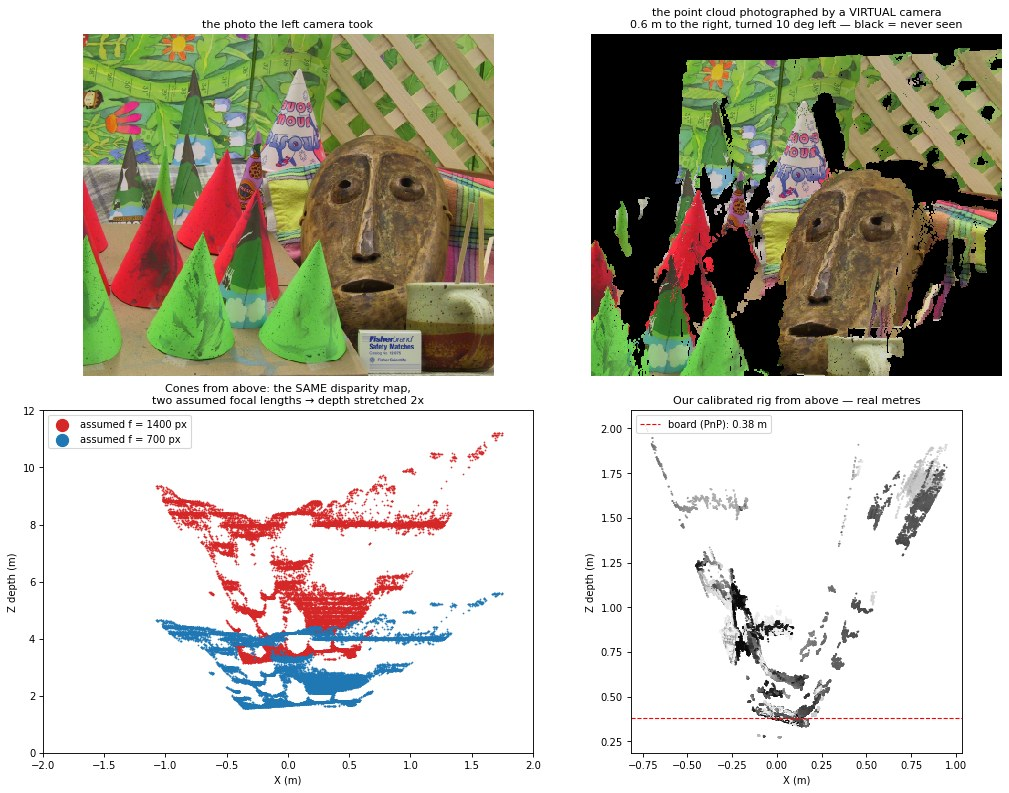

In [24]:
# --- 7.1 🔬 Depth map → coloured point cloud (and what a wrong focal length does to it) ---------
def backproject(disp: np.ndarray, colours: np.ndarray, f: float, cx: float, cy: float, baseline: float):
    """Lift every pixel with a valid disparity into 3D. Returns (N x 3 points in metres, N x 3 colours)."""
    v, u = np.nonzero(disp > 0)
    Z = f * baseline / disp[v, u]
    return np.column_stack([(u - cx) * Z / f, (v - cy) * Z / f, Z]), colours[v, u]


def render_cloud(xyz: np.ndarray, rgb: np.ndarray, K: np.ndarray, yaw_deg: float, centre, size) -> np.ndarray:
    """Photograph a coloured point cloud with a virtual pinhole camera (Part 2). Far points are painted first."""
    uv, z = project(projection_matrix(K, yaw_deg, centre), xyz)
    u, v = np.round(uv).astype(int).T
    ok = (z > 0.1) & (u >= 0) & (u < size[0] - 1) & (v >= 0) & (v < size[1] - 1)
    order = np.argsort(-z[ok])  # painter's algorithm: near points overwrite far ones
    u, v, colour = u[ok][order], v[ok][order], rgb[ok][order]
    image = np.zeros((size[1], size[0], 3), np.uint8)
    for du, dv in ((0, 0), (1, 0), (0, 1), (1, 1)):  # each point covers 2x2 pixels to close pinholes
        image[v + dv, u + du] = colour
    return image


def save_ply(path, xyz: np.ndarray, rgb: np.ndarray) -> None:
    """Write an ASCII .ply file — opens in MeshLab, CloudCompare, Blender."""
    header = (
        "ply\nformat ascii 1.0\n"
        f"element vertex {len(xyz)}\n"
        "property float x\nproperty float y\nproperty float z\n"
        "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n"
    )
    with open(path, "w") as fh:
        fh.write(header)
        np.savetxt(fh, np.hstack([xyz, rgb]), fmt="%.4f %.4f %.4f %d %d %d")


# (a) Middlebury Cones. Its true f and B are NOT published → we must ASSUME a camera; we take the lecture rig. [assumed]
h_c, w_c = cones_sgbm.shape
cloud_cones, col_cones = backproject(cones_sgbm, cones_l, f=700.0, cx=w_c / 2, cy=h_c / 2, baseline=0.12)
cloud_2f, _ = backproject(
    cones_sgbm, cones_l, f=1400.0, cx=w_c / 2, cy=h_c / 2, baseline=0.12
)  # same pixels, f doubled

# (b) Our own rig: every number is calibrated → the cloud is in real metres. [measured]
P1 = RECT_A["P1"]
rig_rgb = np.dstack([results["A"]["left"]] * 3)
cloud_rig, col_rig = backproject(
    results["A"]["disp"], rig_rgb, f=RECT_A["f"], cx=P1[0, 2], cy=P1[1, 2], baseline=RECT_A["baseline"]
)
xyz_cv = cv2.reprojectImageTo3D(results["A"]["disp"], RECT_A["Q"])[
    results["A"]["disp"] > 0
]  # OpenCV's version of the same
print(f"our back-projection vs cv2.reprojectImageTo3D: max difference {np.abs(cloud_rig - xyz_cv).max() * 1000:.3f} mm")

save_ply(OUT / "cones_cloud.ply", cloud_cones, col_cones)
save_ply(OUT / "rig_cloud.ply", cloud_rig, col_rig)
print(
    f"cones: {len(cloud_cones):,} points ({len(cloud_cones) * 15 / 1e6:.1f} MB as float32 xyz + uint8 rgb) "
    f"→ {OUT / 'cones_cloud.ply'}"
)
print(f"rig:   {len(cloud_rig):,} points → {OUT / 'rig_cloud.ply'}   (download and open in MeshLab / CloudCompare)")

K_assumed = make_K(700.0, w_c / 2, h_c / 2)
novel = render_cloud(cloud_cones, col_cones, K_assumed, yaw_deg=-10, centre=(0.6, -0.15, 0.0), size=(w_c, h_c))

fig, axes = plt.subplots(2, 2, figsize=(13, 9.8), constrained_layout=True)
axes = axes.ravel()
axes[0].imshow(cones_l)
axes[0].set_title("the photo the left camera took")
axes[0].axis("off")
axes[1].imshow(novel)
axes[1].axis("off")
axes[1].set_title(
    "the point cloud photographed by a VIRTUAL camera\n0.6 m to the right, turned 10 deg left — black = never seen"
)
keep = rng.choice(len(cloud_cones), 30000, replace=False)
axes[2].scatter(cloud_2f[keep, 0], cloud_2f[keep, 2], s=0.3, color="tab:red", label="assumed f = 1400 px")
axes[2].scatter(cloud_cones[keep, 0], cloud_cones[keep, 2], s=0.3, color="tab:blue", label="assumed f = 700 px")
axes[2].set_xlim(-2, 2)
axes[2].set_ylim(0, 12)
axes[2].set_xlabel("X (m)")
axes[2].set_ylabel("Z depth (m)")
axes[2].legend(markerscale=20, loc="upper left")
axes[2].set_title("Cones from above: the SAME disparity map,\ntwo assumed focal lengths → depth stretched 2x")
near = cloud_rig[:, 2] < 2.2
axes[3].scatter(cloud_rig[near, 0], cloud_rig[near, 2], s=0.3, c=col_rig[near] / 255.0)
axes[3].axhline(
    float(np.mean(results["A"]["z_ref"])),
    color="red",
    ls="--",
    lw=1,
    label=f"board (PnP): {np.mean(results['A']['z_ref']):.2f} m",
)
axes[3].set_xlabel("X (m)")
axes[3].set_ylabel("Z depth (m)")
axes[3].set_aspect("equal")
axes[3].legend(loc="upper left")
axes[3].set_title("Our calibrated rig from above — real metres")
plt.show()

neural implicit: 8,641 parameters trained in 7.3 s; mean |f| on the true surface = 0.0035 (0 would be perfect; the tube radius is 0.25)


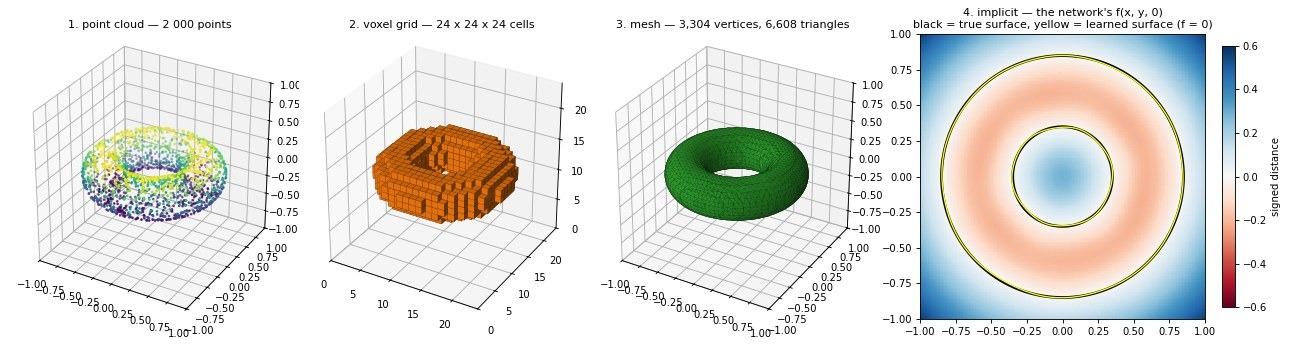

representation   what is stored                    memory  note                                      
---------------  --------------------------------  ------  ------------------------------------------
point cloud      2 000 points x 3 float32          23 KB   fixed sample; no surface between points   
voxel grid       24^3 cells x 1 byte               14 KB   blocky; resolution fixed by the grid      
mesh             3,304 vertices + 6,608 triangles  116 KB  a real surface, made of flat triangles    
neural implicit  8,641 weights x float32           34 KB   any resolution; one network call per query

Voxel memory versus resolution (1 byte per cell):  32^3 = 32 KB   128^3 = 2 MB   512^3 = 128 MB   1024^3 = 1 GB   2048^3 = 8 GB


In [25]:
# --- 7.2 🔬 One shape, four representations — and what each costs  [simulated shape] ------------
def sdf_torus(p: np.ndarray, ring: float = 0.6, tube: float = 0.25) -> np.ndarray:
    """Signed distance to a torus: negative inside, 0 on the surface, positive outside. THIS FUNCTION *IS* THE SHAPE."""
    q = np.hypot(p[..., 0], p[..., 1]) - ring
    return np.hypot(q, p[..., 2]) - tube


def grid_points(n: int) -> np.ndarray:
    axis = np.linspace(-1, 1, n)
    return np.stack(np.meshgrid(axis, axis, axis, indexing="ij"), axis=-1)  # (n, n, n, 3)


# 1) point cloud: 2 000 samples on the surface
a, b = rng.uniform(0, 2 * np.pi, (2, 2000))
torus_pts = np.column_stack(
    [(0.6 + 0.25 * np.cos(b)) * np.cos(a), (0.6 + 0.25 * np.cos(b)) * np.sin(a), 0.25 * np.sin(b)]
)
# 2) voxel grid: is each cell centre inside?
voxels = sdf_torus(grid_points(24)) < 0
# 3) mesh: triangles extracted from the function with marching cubes
try:
    from skimage import measure

    verts, faces, _, _ = measure.marching_cubes(sdf_torus(grid_points(40)), level=0.0, spacing=(2 / 39,) * 3)
    verts -= 1.0
except ImportError:
    verts = faces = None
    print("scikit-image not installed → mesh panel skipped (pip install scikit-image)")
# 4) neural implicit: a small network LEARNS the function f(x, y, z) → signed distance
try:
    import torch
    from torch import nn

    torch.manual_seed(SEED)
    sdf_net = nn.Sequential(
        nn.Linear(3, 64),
        nn.Softplus(beta=20),
        nn.Linear(64, 64),
        nn.Softplus(beta=20),
        nn.Linear(64, 64),
        nn.Softplus(beta=20),
        nn.Linear(64, 1),
    )
    optimiser = torch.optim.Adam(sdf_net.parameters(), lr=3e-3)
    t0 = time.time()
    for step in range(1500):
        xyz = torch.rand(2048, 3) * 2 - 1  # random points in the cube [-1, 1]^3
        target = torch.from_numpy(sdf_torus(xyz.numpy())).float().unsqueeze(1)  # supervision = the true distance
        loss = (sdf_net(xyz) - target).abs().mean()
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    n_params = sum(p.numel() for p in sdf_net.parameters())
    with torch.no_grad():
        surf_err = sdf_net(torch.from_numpy(torus_pts).float()).abs().mean().item()
    print(
        f"neural implicit: {n_params:,} parameters trained in {time.time() - t0:.1f} s; "
        f"mean |f| on the true surface = {surf_err:.4f} (0 would be perfect; the tube radius is 0.25)"
    )
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
    print("PyTorch not installed → neural-implicit panel shows the analytic function instead; cell 7.3 is skipped")

fig = plt.figure(figsize=(16, 4.0), constrained_layout=True)
ax = fig.add_subplot(1, 4, 1, projection="3d")
ax.scatter(*torus_pts.T, s=2, c=torus_pts[:, 2], cmap="viridis")
ax.set_title("1. point cloud — 2 000 points")
ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))
ax.set_box_aspect((1, 1, 1))
ax = fig.add_subplot(1, 4, 2, projection="3d")
ax.voxels(voxels, facecolors="tab:orange", edgecolor="k", linewidth=0.1)
ax.set_title("2. voxel grid — 24 x 24 x 24 cells")
ax.set(xlim=(0, 24), ylim=(0, 24), zlim=(0, 24))
ax.set_box_aspect((1, 1, 1))
ax = fig.add_subplot(1, 4, 3, projection="3d")
if verts is not None:
    ax.plot_trisurf(verts[:, 0], verts[:, 1], faces, verts[:, 2], color="tab:green", edgecolor="k", linewidth=0.05)
    ax.set_title(f"3. mesh — {len(verts):,} vertices, {len(faces):,} triangles")
ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))
ax.set_box_aspect((1, 1, 1))
ax = fig.add_subplot(1, 4, 4)
axis = np.linspace(-1, 1, 200)
gx, gy = np.meshgrid(axis, axis, indexing="ij")
slice_pts = np.stack([gx, gy, np.zeros_like(gx)], axis=-1)  # sample the plane z = 0
if HAVE_TORCH:
    with torch.no_grad():
        learned = sdf_net(torch.from_numpy(slice_pts.reshape(-1, 3)).float()).numpy().reshape(200, 200)
else:
    learned = sdf_torus(slice_pts)
handle = ax.imshow(learned.T, extent=(-1, 1, -1, 1), origin="lower", cmap="RdBu", vmin=-0.6, vmax=0.6)
ax.contour(axis, axis, sdf_torus(slice_pts).T, levels=[0], colors="k", linewidths=2.5)
ax.contour(axis, axis, learned.T, levels=[0], colors="yellow", linewidths=1.2)
ax.set_title("4. implicit — the network's f(x, y, 0)\nblack = true surface, yellow = learned surface (f = 0)")
fig.colorbar(handle, ax=ax, fraction=0.046, pad=0.02, label="signed distance")
plt.show()


def fmt_bytes(n: float) -> str:
    for unit in ("B", "KB", "MB", "GB", "TB"):
        if n < 1024:
            return f"{n:.0f} {unit}"
        n /= 1024
    return f"{n:.0f} PB"


rows = [
    ("point cloud", "2 000 points x 3 float32", fmt_bytes(2000 * 12), "fixed sample; no surface between points"),
    ("voxel grid", "24^3 cells x 1 byte", fmt_bytes(24**3), "blocky; resolution fixed by the grid"),
]
if verts is not None:
    rows.append(
        (
            "mesh",
            f"{len(verts):,} vertices + {len(faces):,} triangles",
            fmt_bytes(len(verts) * 12 + len(faces) * 12),
            "a real surface, made of flat triangles",
        )
    )
if HAVE_TORCH:
    rows.append(
        (
            "neural implicit",
            f"{n_params:,} weights x float32",
            fmt_bytes(n_params * 4),
            "any resolution; one network call per query",
        )
    )
table(rows, ["representation", "what is stored", "memory", "note"])
print(
    "\nVoxel memory versus resolution (1 byte per cell):  "
    + "   ".join(f"{n}^3 = {fmt_bytes(n**3)}" for n in (32, 128, 512, 1024, 2048))
)

model                                  parameters  accuracy, scan order  accuracy, shuffled  max output change  train time
-------------------------------------  ----------  --------------------  ------------------  -----------------  ----------
PointNet-mini (shared MLP + max pool)  75,012      100.0%                100.0%              0.00e+00           13 s      
flat MLP (control)                     131,972     76.5%                 26.2%               1.85e+01           2 s       


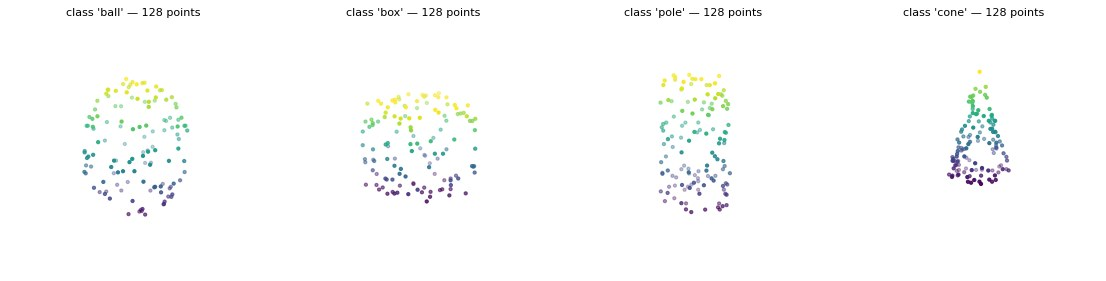

In [26]:
# --- 7.3 🔬 Mini PointNet: why "shared MLP + max pooling" is the right idea for point sets  [simulated data] ---
N_POINTS, CLASSES = 128, ["ball", "box", "pole", "cone"]


def sample_shape(kind: str, n: int, gen: np.random.Generator) -> np.ndarray:
    """n points on the surface of a shape that stands on the ground (z is up), as a LiDAR might see an object."""
    if kind == "ball":
        p = gen.normal(size=(n, 3))
        p /= np.linalg.norm(p, axis=1, keepdims=True)
    elif kind == "box":
        p = gen.uniform(-1, 1, (n, 3))
        face = gen.integers(0, 3, n)
        p[np.arange(n), face] = gen.choice([-1.0, 1.0], n)  # push every point onto one of the 6 faces
    else:
        ang, t = gen.uniform(0, 2 * np.pi, n), gen.uniform(0, 1, n)
        on_cap = gen.uniform(0, 1, n) < 0.2
        if kind == "pole":  # cylinder: constant radius
            radius = np.where(on_cap, 0.5 * np.sqrt(t), 0.5)
            z = np.where(on_cap, gen.choice([-1.0, 1.0], n), 2 * t - 1)
        else:  # cone: radius shrinks to a tip
            radius = 0.7 * np.sqrt(t)  # sqrt → uniform density on the surface
            z = np.where(on_cap, -1.0, 1 - 2 * np.sqrt(t))  # base disc at z = -1, tip at z = +1
        p = np.column_stack([radius * np.cos(ang), radius * np.sin(ang), z])
    yaw = gen.uniform(0, 2 * np.pi)  # random heading, size and sensor noise
    rot = np.array([[np.cos(yaw), -np.sin(yaw), 0], [np.sin(yaw), np.cos(yaw), 0], [0, 0, 1]])
    p = (p * gen.uniform(0.8, 1.2, 3)) @ rot.T + gen.normal(0, 0.02, (n, 3))
    p -= p.mean(axis=0)
    p /= np.linalg.norm(p, axis=1).max()
    return p[np.argsort(p[:, 2])].astype(np.float32)  # stored in "scan order": bottom to top


def make_set(per_class: int, gen: np.random.Generator):
    x = np.stack([sample_shape(kind, N_POINTS, gen) for kind in CLASSES for _ in range(per_class)])
    y = np.repeat(np.arange(len(CLASSES)), per_class).astype(np.int64)  # int64 = PyTorch 'long' on every platform
    return x, y


if HAVE_TORCH:
    gen_pn = np.random.default_rng(SEED)
    x_train, y_train = make_set(200, gen_pn)
    x_test, y_test = make_set(100, gen_pn)

    class PointNetMini(nn.Module):
        """PointNet in 3 lines: the SAME small network for every point, then a max over all points."""

        def __init__(self, n_classes: int):
            super().__init__()
            self.per_point = nn.Sequential(
                nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU()
            )
            self.head = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, n_classes))

        def forward(self, pts):  # pts: (batch, N, 3)
            features = self.per_point(pts)  # (batch, N, 256) — identical weights for every point
            global_feature = features.max(dim=1).values  # (batch, 256)    — max is symmetric: order cannot matter
            return self.head(global_feature)

    class FlatMLP(nn.Module):
        """Control: treat the cloud as one long vector of 3N numbers (as you would treat a tiny image)."""

        def __init__(self, n_classes: int):
            super().__init__()
            self.net = nn.Sequential(
                nn.Flatten(),
                nn.Linear(3 * N_POINTS, 256),
                nn.ReLU(),
                nn.Linear(256, 128),
                nn.ReLU(),
                nn.Linear(128, n_classes),
            )

        def forward(self, pts):
            return self.net(pts)

    def train(model: nn.Module, epochs: int = 30) -> float:
        torch.manual_seed(SEED)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        xs, ys = torch.from_numpy(x_train), torch.from_numpy(y_train)
        t_start = time.time()
        for _ in range(epochs):
            for idx in torch.randperm(len(xs)).split(32):
                loss = nn.functional.cross_entropy(model(xs[idx]), ys[idx])
                opt.zero_grad()
                loss.backward()
                opt.step()
        return time.time() - t_start

    def accuracy(model: nn.Module, x: np.ndarray) -> float:
        with torch.no_grad():
            return float((model(torch.from_numpy(x)).argmax(dim=1).numpy() == y_test).mean())

    x_shuffled = np.stack([cloud[gen_pn.permutation(N_POINTS)] for cloud in x_test])  # same points, different order
    rows = []
    for name, model in (
        ("PointNet-mini (shared MLP + max pool)", PointNetMini(len(CLASSES))),
        ("flat MLP (control)", FlatMLP(len(CLASSES))),
    ):
        seconds = train(model)
        with torch.no_grad():
            change = (model(torch.from_numpy(x_test)) - model(torch.from_numpy(x_shuffled))).abs().max().item()
        rows.append(
            (
                name,
                f"{sum(p.numel() for p in model.parameters()):,}",
                f"{accuracy(model, x_test):.1%}",
                f"{accuracy(model, x_shuffled):.1%}",
                f"{change:.2e}",
                f"{seconds:.0f} s",
            )
        )
    table(
        rows, ["model", "parameters", "accuracy, scan order", "accuracy, shuffled", "max output change", "train time"]
    )

    fig = plt.figure(figsize=(14, 3.4), constrained_layout=True)
    for k, name in enumerate(CLASSES):
        ax = fig.add_subplot(1, 4, k + 1, projection="3d")
        cloud = x_test[k * 100]
        ax.scatter(*cloud.T, s=8, c=cloud[:, 2], cmap="viridis")
        ax.set_title(f"class '{name}' — {N_POINTS} points")
        ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=14, azim=-60)
        ax.set_axis_off()
    plt.show()

**Read the result.**
- **A point cloud from one stereo pair is "2.5D":** photographed from a new viewpoint it has black holes behind every object.
  Filling them needs more views (Part 8). Note that the virtual photo was made with *your* `project()` function from Part 2.
- **Wrong focal length = stretched world.** With an assumed $f$ the shape is right only up to a stretch along depth; only the calibrated rig gives metres.
- **Memory:** the voxel line is the cubic growth from §6.2 — a 1024³ grid is a gigabyte before you store anything but one byte per cell.
  The implicit network stores the same shape in a few thousand weights and can be queried at any resolution — but every query is a network call.
- **PointNet:** the flat MLP learns something as long as points arrive in the order it was trained on, and falls to chance level
  (25 % for four classes) when the *same* points are shuffled. PointNet's output does not change by a single bit —
  permutation invariance is built into the architecture (the max over points), not learned from data.

🌍 **Real world.** LiDAR on a car → point clouds (and PointNet-style networks). CT / MRI → voxel grids (Day 37).
Games, AR and 3D printing → meshes. Novel-view synthesis and digital twins → implicit / neural representations (Part 10).

✍️ **Exercise 7 (2 min).**
1. In `PointNetMini.forward`, replace `.max(dim=1).values` by `.mean(dim=1)`. Is the model still permutation-invariant? And with `[:, 0]` (first point only)?
2. A CT scan has 512 × 512 × 300 voxels of 2 bytes each. How much memory is that? What happens if you double the resolution along every axis?
3. Why can't we simply feed a point cloud to an ordinary 2D CNN?

<details><summary>Show answer</summary>

1. `mean` is also symmetric → still invariant (max usually works better because it keeps the most distinctive points).
   `[:, 0]` depends on which point happens to be first → not invariant.
2. $512 \times 512 \times 300 \times 2$ B ≈ 157 MB. Doubling every axis multiplies it by $2^3 = 8$ → ≈ 1.26 GB.
3. A CNN needs a regular grid with meaningful neighbours. A point cloud is an unordered set with no grid: any listing order is as valid as
   any other, so the network must give the same answer for all of them — the property PointNet's symmetric function guarantees.

</details>

---
# Part 8 — Structure from Motion and visual SLAM  *(8 min · §7)*

🧠 **Concept.** A stereo rig is two cameras with a *known* relative pose. **Structure from Motion (SfM)** removes that
assumption: from ordinary photos taken from unknown positions it recovers **both** the camera poses (*motion*) and the 3D points (*structure*).

The pipeline (Figure 6 of the notes) re-uses everything you already ran:

| Step | What it does | Where you met it |
|---|---|---|
| 1. Detect + match features | find the same physical points across photos | Day 28, Part 4.1 |
| 2. Pose with RANSAC | essential matrix → rotation, translation direction | Part 4.3 |
| 3. Triangulate | intersect the two viewing rays of each match → 3D point | new, below |
| 4. Bundle adjustment | jointly refine **all** cameras and points to minimise reprojection error | new, below |

**Visual SLAM** runs the same steps *incrementally and in real time* on a video stream, and adds **loop closure**:
recognising a place seen before and using it to cancel accumulated drift.

*Needs:* Part 0, and `match_sift` from Part 4.

K of this camera (from OpenCV's sample file): fx = 651.4, fy = 653.7, cx = 376.3, cy = 280.1
278 matches → 195 essential-matrix inliers → 192 points in front of both cameras
camera B: rotated 23.2 deg, moved along [ 0.37 -0.1  -0.92] (length is 1 by convention)
reprojection error of the 192 triangulated points: 0.13 px mean, 0.88 px max


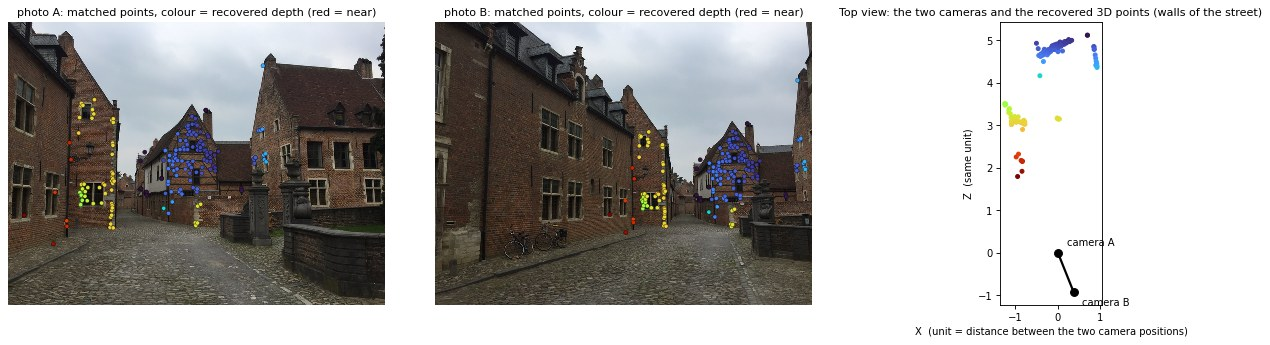

In [27]:
# --- 8.1 🔬 Two-view SfM on real photos of a street: matches → pose → triangulated 3D points  [measured] ---
sfm_a, sfm_b = imread_rgb(DATA / "sfm/leuvenA.jpg"), imread_rgb(DATA / "sfm/leuvenB.jpg")
K_sfm = np.array(
    [row.split() for row in (DATA / "sfm/essential_mat_data.txt").read_text().splitlines()[2:5]], dtype=float
)

pa, pb = match_sift(cv2.cvtColor(sfm_a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(sfm_b, cv2.COLOR_RGB2GRAY))  # step 1
E_sfm, mask_e = cv2.findEssentialMat(pa, pb, K_sfm, method=cv2.RANSAC, prob=0.999, threshold=1.0)  # step 2
n_front, R_ab, t_ab, mask_pose = cv2.recoverPose(E_sfm, pa, pb, K_sfm, mask=mask_e.copy())
good = mask_pose.ravel() > 0

P_a = K_sfm @ np.hstack([np.eye(3), np.zeros((3, 1))])  # camera A defines the world frame
P_b = K_sfm @ np.hstack([R_ab, t_ab.reshape(3, 1)])  # camera B = A moved by (R, t)
X_h = cv2.triangulatePoints(P_a, P_b, pa[good].T.astype(np.float64), pb[good].T.astype(np.float64))  # step 3
X_sfm = (X_h[:3] / X_h[3]).T  # homogeneous → (N, 3)


def reprojection_px(P: np.ndarray, X: np.ndarray, observed: np.ndarray) -> np.ndarray:
    """Distance in pixels between where a 3D point projects and where its feature was actually detected."""
    x = np.c_[X, np.ones(len(X))] @ P.T
    return np.linalg.norm(x[:, :2] / x[:, 2:3] - observed, axis=1)


err_a, err_b = reprojection_px(P_a, X_sfm, pa[good]), reprojection_px(P_b, X_sfm, pb[good])
centre_b = (-R_ab.T @ t_ab).ravel()  # where camera B stood, in A's frame
print(
    f"K of this camera (from OpenCV's sample file): fx = {K_sfm[0, 0]:.1f}, fy = {K_sfm[1, 1]:.1f}, "
    f"cx = {K_sfm[0, 2]:.1f}, cy = {K_sfm[1, 2]:.1f}"
)
print(
    f"{len(pa)} matches → {int(mask_e.sum())} essential-matrix inliers → {int(good.sum())} points in front of both cameras"
)
print(
    f"camera B: rotated {np.degrees(np.linalg.norm(cv2.Rodrigues(R_ab)[0])):.1f} deg, "
    f"moved along {centre_b.round(2)} (length is 1 by convention)"
)
print(
    f"reprojection error of the {len(X_sfm)} triangulated points: "
    f"{np.mean(np.r_[err_a, err_b]):.2f} px mean, {np.max(np.r_[err_a, err_b]):.2f} px max"
)

depth_cap = np.percentile(X_sfm[:, 2], 95)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
for ax, img, pts, name in ((axes[0], sfm_a, pa[good], "photo A"), (axes[1], sfm_b, pb[good], "photo B")):
    ax.imshow(img)
    ax.scatter(pts[:, 0], pts[:, 1], c=X_sfm[:, 2], cmap="turbo_r", s=14, vmax=depth_cap, edgecolor="k", linewidths=0.3)
    ax.set_title(f"{name}: matched points, colour = recovered depth (red = near)")
    ax.axis("off")
near = X_sfm[:, 2] < depth_cap
axes[2].scatter(X_sfm[near, 0], X_sfm[near, 2], c=X_sfm[near, 2], cmap="turbo_r", s=12, vmax=depth_cap)
axes[2].plot([0, centre_b[0]], [0, centre_b[2]], "k-o", lw=2, ms=7)
axes[2].annotate("camera A", (0, 0), textcoords="offset points", xytext=(8, 6))
axes[2].annotate("camera B", (centre_b[0], centre_b[2]), textcoords="offset points", xytext=(8, -12))
axes[2].set_xlabel("X  (unit = distance between the two camera positions)")
axes[2].set_ylabel("Z  (same unit)")
axes[2].set_aspect("equal")
axes[2].set_title("Top view: the two cameras and the recovered 3D points (walls of the street)")
plt.show()

bundle adjustment: 198 unknowns, 600 residuals, 5 iterations, 0.3 s
quantity                     before  after   reference                                 
---------------------------  ------  ------  ------------------------------------------
reprojection error (px RMS)  22.69   0.3855  pixel noise we added: 0.5                 
3D point error (cm, mean)    23.78   1.103   truth known only because this is simulated


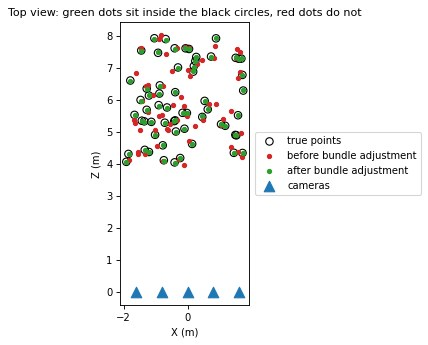

In [28]:
# --- 8.2 🔬 Bundle adjustment: refine all cameras and all points together  [simulated, so the truth is known] ---
rng_ba = np.random.default_rng(SEED)
K_ba = np.array([[700.0, 0, 320.0], [0, 700.0, 240.0], [0, 0, 1.0]])
N_CAMS, N_PTS, PIXEL_NOISE = 5, 60, 0.5

pts_true = np.column_stack([rng_ba.uniform(-2, 2, N_PTS), rng_ba.uniform(-1, 1, N_PTS), rng_ba.uniform(4, 8, N_PTS)])
centres_true = np.column_stack([np.linspace(-1.6, 1.6, N_CAMS), np.zeros(N_CAMS), np.zeros(N_CAMS)])
rvecs_true, tvecs_true = [], []
for c in centres_true:  # every camera looks at the middle of the scene
    yaw = np.arctan2(0.0 - c[0], 6.0 - c[2])
    R = np.array([[np.cos(yaw), 0, np.sin(yaw)], [0, 1, 0], [-np.sin(yaw), 0, np.cos(yaw)]]).T
    rvecs_true.append(cv2.Rodrigues(R)[0].ravel())
    tvecs_true.append(-R @ c)
rvecs_true, tvecs_true = np.array(rvecs_true), np.array(tvecs_true)


def project_all(rvecs: np.ndarray, tvecs: np.ndarray, pts: np.ndarray) -> np.ndarray:
    """Pixels of every point in every camera: array (N_CAMS, N_PTS, 2)."""
    return np.stack(
        [
            cv2.projectPoints(pts, r.reshape(3, 1), t.reshape(3, 1), K_ba, None)[0].reshape(-1, 2)
            for r, t in zip(rvecs, tvecs)
        ]
    )


observed = project_all(rvecs_true, tvecs_true, pts_true) + rng_ba.normal(
    0, PIXEL_NOISE, (N_CAMS, N_PTS, 2)
)  # noisy measurements

# A rough starting point, as incremental SfM would hand over: poses and points are all slightly wrong.
rvecs_0 = rvecs_true + rng_ba.normal(0, 0.02, rvecs_true.shape)  # about 1 degree
tvecs_0 = tvecs_true + rng_ba.normal(0, 0.08, tvecs_true.shape)  # about 8 cm
pts_0 = pts_true + rng_ba.normal(0, 0.15, pts_true.shape)  # about 15 cm
rvecs_0[:2], tvecs_0[:2] = rvecs_true[:2], tvecs_true[:2]  # cameras 0 and 1 are known → fixes position, rotation, scale


def unpack(params: np.ndarray):
    n = (N_CAMS - 2) * 3
    rvecs = np.vstack([rvecs_true[:2], params[:n].reshape(-1, 3)])
    tvecs = np.vstack([tvecs_true[:2], params[n : 2 * n].reshape(-1, 3)])
    return rvecs, tvecs, params[2 * n :].reshape(-1, 3)


def ba_residuals(params: np.ndarray) -> np.ndarray:
    """What bundle adjustment minimises: predicted pixel minus observed pixel, for every point in every camera."""
    return (project_all(*unpack(params)) - observed).ravel()


x0 = np.concatenate([rvecs_0[2:].ravel(), tvecs_0[2:].ravel(), pts_0.ravel()])
t0 = time.time()
solution = least_squares(ba_residuals, x0, method="trf", x_scale="jac", max_nfev=40)
rvecs_ba, tvecs_ba, pts_ba = unpack(solution.x)


def rms(values: np.ndarray) -> float:
    return float(np.sqrt(np.mean(values**2)))


print(
    f"bundle adjustment: {len(x0)} unknowns, {len(solution.fun)} residuals, "
    f"{solution.nfev} iterations, {time.time() - t0:.1f} s"
)
table(
    [
        (
            "reprojection error (px RMS)",
            rms(ba_residuals(x0)),
            rms(solution.fun),
            f"pixel noise we added: {PIXEL_NOISE}",
        ),
        (
            "3D point error (cm, mean)",
            100 * np.linalg.norm(pts_0 - pts_true, axis=1).mean(),
            100 * np.linalg.norm(pts_ba - pts_true, axis=1).mean(),
            "truth known only because this is simulated",
        ),
    ],
    ["quantity", "before", "after", "reference"],
)

fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
ax.scatter(pts_true[:, 0], pts_true[:, 2], s=45, facecolors="none", edgecolors="k", label="true points")
ax.scatter(pts_0[:, 0], pts_0[:, 2], s=14, color="tab:red", label="before bundle adjustment")
ax.scatter(pts_ba[:, 0], pts_ba[:, 2], s=14, color="tab:green", label="after bundle adjustment")
ax.scatter(centres_true[:, 0], centres_true[:, 2], marker="^", s=90, color="tab:blue", label="cameras")
ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_aspect("equal")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Top view: green dots sit inside the black circles, red dots do not")
plt.show()

quantity                                odometry only  after loop closure
--------------------------------------  -------------  ------------------
end-point gap: start vs. finish (m)     0.9748         0.0002656         
mean position error along the path (m)  0.6511         0.04615           
(pose-graph optimisation of 80 poses: 0.2 s)


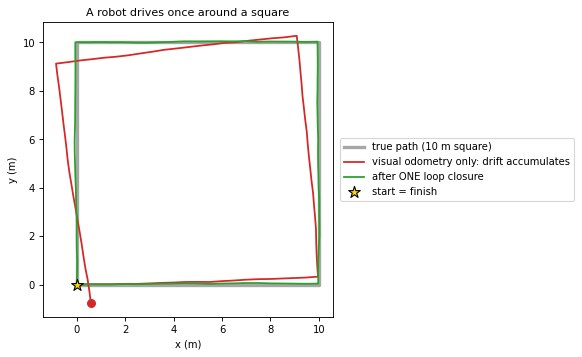

In [29]:
# --- 8.3 🔬 Visual odometry drifts; a loop closure pulls the map back together  [simulated] --------
rng_vo = np.random.default_rng(SEED)
STEP_M, SIDE_STEPS = 0.5, 20  # a robot drives a 10 m x 10 m square: 80 steps
N_STEPS = 4 * SIDE_STEPS
turn_true = np.zeros(N_STEPS)
turn_true[SIDE_STEPS - 1 :: SIDE_STEPS] = np.pi / 2  # turn left 90 deg at each corner
odo_true = np.column_stack(
    [np.full(N_STEPS, STEP_M), np.zeros(N_STEPS), turn_true]
)  # per step: (forward, sideways, turn)

SIGMA_T, SIGMA_ROT = 0.02 * STEP_M, np.radians(0.5)  # frame-to-frame errors of a visual odometry
odo_meas = odo_true + np.column_stack(
    [
        rng_vo.normal(0, SIGMA_T, N_STEPS),
        rng_vo.normal(0, SIGMA_T, N_STEPS),
        rng_vo.normal(np.radians(0.12), SIGMA_ROT, N_STEPS),
    ]
)  # includes a small systematic bias


def integrate(odometry: np.ndarray) -> np.ndarray:
    """Dead reckoning: chain the relative motions. Returns poses (x, y, heading), pose 0 = origin."""
    poses = np.zeros((len(odometry) + 1, 3))
    for k, (dx, dy, dth) in enumerate(odometry):
        x, y, th = poses[k]
        poses[k + 1] = (x + dx * np.cos(th) - dy * np.sin(th), y + dx * np.sin(th) + dy * np.cos(th), th + dth)
    return poses


def graph_residuals(flat: np.ndarray, i: np.ndarray, j: np.ndarray, meas: np.ndarray, weight: np.ndarray) -> np.ndarray:
    """Pose graph: every edge says 'seen from pose i, pose j is at `meas`'. Residual = prediction - measurement."""
    poses = np.vstack([np.zeros(3), flat.reshape(-1, 3)])  # pose 0 is fixed at the origin
    c, s = np.cos(poses[i, 2]), np.sin(poses[i, 2])
    dx, dy = poses[j, 0] - poses[i, 0], poses[j, 1] - poses[i, 1]
    err = np.column_stack([c * dx + s * dy, -s * dx + c * dy, poses[j, 2] - poses[i, 2]]) - meas
    err[:, 2] = (err[:, 2] + np.pi) % (2 * np.pi) - np.pi  # angles wrap around
    return (err * weight).ravel()


path_true, path_vo = integrate(odo_true), integrate(odo_meas)

# Edges: 80 odometry measurements + ONE loop closure "pose 80 is the same place as pose 0" (found by recognising the scene)
edge_i = np.r_[np.arange(N_STEPS), N_STEPS]
edge_j = np.r_[np.arange(1, N_STEPS + 1), 0]
edge_meas = np.vstack([odo_meas, [0.0, 0.0, 2 * np.pi]])  # same place, one full turn later
edge_w = np.vstack(
    [np.tile([1 / SIGMA_T, 1 / SIGMA_T, 1 / SIGMA_ROT], (N_STEPS, 1)), [1 / 0.01, 1 / 0.01, 1 / np.radians(0.2)]]
)
t0 = time.time()
graph = least_squares(graph_residuals, path_vo[1:].ravel(), args=(edge_i, edge_j, edge_meas, edge_w))
path_slam = np.vstack([np.zeros(3), graph.x.reshape(-1, 3)])

table(
    [
        (
            "end-point gap: start vs. finish (m)",
            float(np.linalg.norm(path_vo[-1, :2] - path_vo[0, :2])),
            float(np.linalg.norm(path_slam[-1, :2] - path_slam[0, :2])),
        ),
        (
            "mean position error along the path (m)",
            float(np.linalg.norm(path_vo[:, :2] - path_true[:, :2], axis=1).mean()),
            float(np.linalg.norm(path_slam[:, :2] - path_true[:, :2], axis=1).mean()),
        ),
    ],
    ["quantity", "odometry only", "after loop closure"],
)
print(f"(pose-graph optimisation of {N_STEPS} poses: {time.time() - t0:.1f} s)")

fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
ax.plot(path_true[:, 0], path_true[:, 1], "k-", lw=3, alpha=0.35, label="true path (10 m square)")
ax.plot(path_vo[:, 0], path_vo[:, 1], "-", color="tab:red", lw=1.6, label="visual odometry only: drift accumulates")
ax.plot(path_slam[:, 0], path_slam[:, 1], "-", color="tab:green", lw=1.6, label="after ONE loop closure")
ax.scatter([0], [0], s=120, marker="*", color="gold", edgecolor="k", zorder=3, label="start = finish")
ax.scatter(*path_vo[-1, :2], s=50, color="tab:red", zorder=3)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("A robot drives once around a square")
plt.show()

**Read the result.**
- **Two photos, no rig, no calibration target in the scene:** matched features alone gave the camera motion and a sparse 3D model of the
  street — from above, the near wall on the left and the house fronts at the end of the street form separate groups at different depths. `[measured]`
- **Scale is missing.** Everything is expressed in units of "the distance the camera moved". SfM from images alone can never say whether
  that was 1 m or 10 m. Metric scale needs one outside fact: a known baseline (stereo), an object of known size, GPS, an IMU, or a known camera height.
- **Bundle adjustment** pulled the reprojection error down to the level of the pixel noise we injected, and the 3D points moved from
  decimetres to about a centimetre from the truth. It works because every point constrains every camera that sees it, and vice versa.
- **Drift and loop closure:** each odometry step is accurate to about half a degree, yet after 80 steps the start and the finish no longer
  meet (see the gap in the table). A *single* constraint — "I have been here before" — corrects the **whole** trajectory, not just the end point.

**SfM vs SLAM** (§7.3): SfM is offline and aims for the most accurate reconstruction (photogrammetry, heritage scanning, drone mapping).
SLAM is online: track the camera *now*, keep a map, close loops (robot vacuums, AR headsets, drones).
**Connection to tracking** (§7.4): Day 35 followed *objects* through video while the camera was treated as fixed; SfM/SLAM follow the
*camera* through a scene that is treated as fixed — the same "associate across frames" problem, seen from the other side.

⚠️ **Pitfall.** A low reprojection error does not prove the reconstruction is right — a *wrong* pose can also fit its own inliers
(remember the failing pairs in Part 4.3). Check against something independent whenever you can.

✍️ **Exercise 8 (2 min).**
1. In cell 8.3, delete the loop-closure edge by setting its weights to zero (`[0, 0, 0]` as the last row of `edge_w`). What does the optimiser return, and why?
2. The camera in 8.1 moved mostly *forwards* along the street. Why is depth hard to estimate for points near the centre of the image in that case?
3. Why does bundle adjustment optimise cameras **and** points together, instead of first the cameras and then the points?

<details><summary>Show answer</summary>

1. Exactly the odometry-only path. Without the loop edge the odometry measurements do not contradict each other,
   so the starting guess already has zero error — there is nothing to correct. Drift is invisible until an independent constraint exposes it.
2. When the camera moves towards a point, that point's two viewing rays are almost parallel: it hardly shifts between the images
   (tiny parallax), so the ray intersection is poorly defined. The same $Z^2/(fB)$ sensitivity as in Part 5.1, with an effective baseline near zero.
3. The errors are coupled: a slightly wrong camera pose shifts every point triangulated from it, and wrong points bias the next pose.
   Only a joint optimisation can trade these errors off against each other and make the whole model consistent.

</details>

---
# Part 9 — Video: optical flow, temporal consistency, codecs  *(8 min · §8)*

🧠 **Concept.** A video is not a pile of unrelated pictures. It is one **spatiotemporal signal** — a tensor of shape
(time, height, width, channels) — in which neighbouring frames are almost identical. Everything in this part follows from that redundancy:

- **Optical flow** measures *how* consecutive frames differ: an apparent motion vector per pixel (Day 28 §9).
  *Lucas–Kanade* tracks a sparse set of corners; *Farnebäck* estimates a dense field.
- **Temporal consistency:** a model applied to each frame on its own has no reason to agree with itself from frame to frame → **flicker**.
- **Preprocessing** must respect time: a random crop has to be the *same* for every frame of a clip.
- **Compression** exploits the redundancy: keyframes (**I**) are stored whole, predicted frames (**P**, **B**) store only what changed.

**Real data.** `vtest.avi` — 80 s of footage from a fixed surveillance camera watching a pedestrian crossing (768 × 576, 10 fps).

*Needs:* Part 0 only (cell 9.3 additionally uses the depth network from Part 6 if it was loaded).

clip tensor: shape (60, 288, 384, 3) (T, H, W, C), 19.9 MB for 6 s of half-resolution video
whole file:  795 frames at 10 fps → 1.06 GB as raw pixels, but only 8.1 MB on disk (130x smaller, see 9.4)
84% of the pixels are static; the busiest row is y = 127


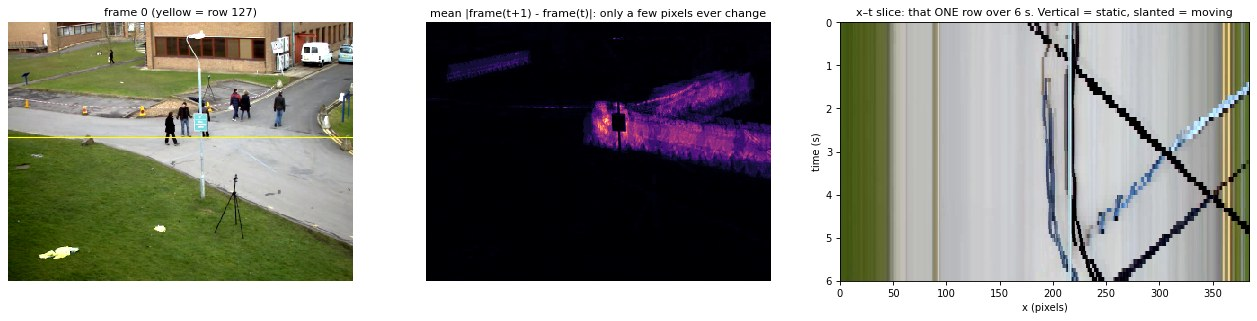

In [30]:
# --- 9.1 🔬 A video is a tensor (T, H, W, C) — and motion is visible as slanted streaks  [measured] ---
VIDEO = DATA / "video/vtest.avi"


def read_clip(path, start: int, count: int, scale: float = 0.5):
    """Decode `count` frames beginning at frame `start`. Returns (uint8 array (T, H, W, 3) in RGB, fps, total frames)."""
    cap = cv2.VideoCapture(str(path))
    assert cap.isOpened(), f"cannot open {path}"
    fps, total = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    for k in range(start + count):
        ok, frame = cap.read()  # sequential decoding — see 9.4 for why seeking is not free
        if not ok:
            break
        if k >= start:
            frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    return np.stack(frames), fps, total


clip, FPS, total_frames = read_clip(VIDEO, start=100, count=60)
clip_gray = np.stack([cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) for f in clip])
T, VH, VW, _ = clip.shape
raw_gb = total_frames * (2 * VH) * (2 * VW) * 3 / 1e9
print(
    f"clip tensor: shape {clip.shape} (T, H, W, C), {clip.nbytes / 1e6:.1f} MB for {T / FPS:.0f} s of half-resolution video"
)
print(
    f"whole file:  {total_frames} frames at {FPS:.0f} fps → {raw_gb:.2f} GB as raw pixels, but only "
    f"{VIDEO.stat().st_size / 1e6:.1f} MB on disk ({raw_gb * 1e9 / VIDEO.stat().st_size:.0f}x smaller, see 9.4)"
)

frame_change = np.abs(np.diff(clip_gray.astype(np.float32), axis=0))
static = frame_change.mean(axis=0) < 1.5  # pixels that (almost) never change in this clip
ROW = int(np.argmax(frame_change.mean(axis=(0, 2))))  # the image row with the most motion
print(f"{static.mean():.0%} of the pixels are static; the busiest row is y = {ROW}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), constrained_layout=True)
axes[0].imshow(clip[0])
axes[0].axhline(ROW, color="yellow", lw=1)
axes[0].set_title(f"frame 0 (yellow = row {ROW})")
axes[0].axis("off")
axes[1].imshow(frame_change.mean(axis=0), cmap="magma")
axes[1].set_title("mean |frame(t+1) - frame(t)|: only a few pixels ever change")
axes[1].axis("off")
axes[2].imshow(clip[:, ROW], aspect="auto", extent=(0, VW, T / FPS, 0))
axes[2].set_xlabel("x (pixels)")
axes[2].set_ylabel("time (s)")
axes[2].set_title("x–t slice: that ONE row over 6 s. Vertical = static, slanted = moving")
plt.show()

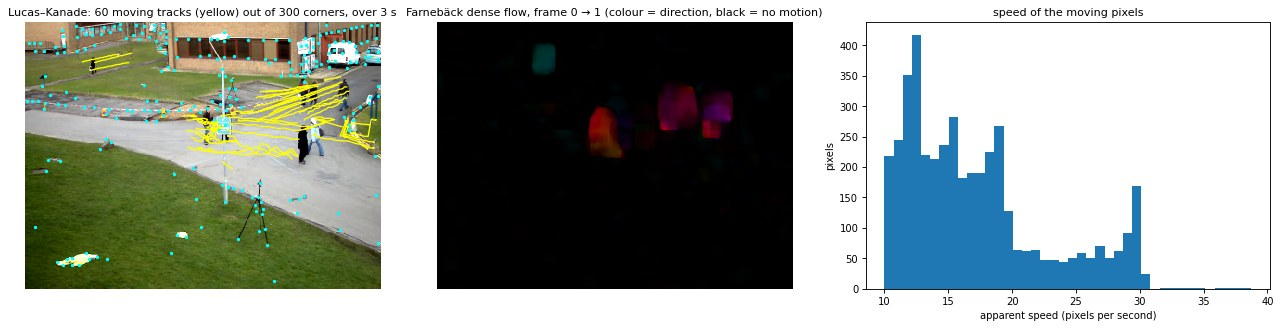

dense flow for 384x288 px: 34 ms | 3.9% of pixels move | median speed 1.6 px/frame = 16 px/s
To convert px/s into m/s you need metres per pixel at that spot — the scale ambiguity of Part 1 again.


In [31]:
# --- 9.2 🔬 Optical flow: sparse tracks (Lucas–Kanade) and a dense field (Farnebäck)  [measured] ----
def track_lucas_kanade(gray_frames: np.ndarray, max_corners: int = 300) -> np.ndarray:
    """Follow corners through a clip. Returns paths (T, N, 2); a lost track is NaN from then on."""
    pts = cv2.goodFeaturesToTrack(gray_frames[0], maxCorners=max_corners, qualityLevel=0.01, minDistance=6)
    pts = np.asarray(pts, np.float32).reshape(-1, 1, 2)
    paths = np.full((len(gray_frames), len(pts), 2), np.nan, np.float32)
    paths[0], alive = pts.reshape(-1, 2), np.ones(len(pts), bool)
    for t in range(1, len(gray_frames)):
        nxt, status, _ = cv2.calcOpticalFlowPyrLK(
            gray_frames[t - 1], gray_frames[t], pts, None, winSize=(21, 21), maxLevel=3
        )
        alive &= np.asarray(status).ravel().astype(bool)
        pts = np.asarray(nxt, np.float32).reshape(-1, 1, 2)
        paths[t, alive] = pts.reshape(-1, 2)[alive]
    return paths


def flow_to_rgb(flow: np.ndarray, max_mag: float) -> np.ndarray:
    """Standard flow picture: hue = direction, brightness = speed."""
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros(flow.shape[:2] + (3,), np.uint8)
    hsv[..., 0], hsv[..., 1] = (ang * 90 / np.pi).astype(np.uint8), 255
    hsv[..., 2] = np.clip(mag / max_mag * 255, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


paths = track_lucas_kanade(clip_gray[:30])
travelled = np.linalg.norm(paths[-1] - paths[0], axis=1)  # NaN for lost tracks
moving = travelled > 10

t0 = time.time()
flow = cv2.calcOpticalFlowFarneback(
    clip_gray[0], clip_gray[1], None, 0.5, 3, 15, 3, 5, 1.2, 0
)  # dense: one vector per pixel
t_flow = time.time() - t0
speed = np.linalg.norm(flow, axis=2)
walkers = speed > 1.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.0), constrained_layout=True)
axes[0].imshow(clip[29])
axes[0].scatter(paths[0, ~moving, 0], paths[0, ~moving, 1], s=4, color="cyan")
for n in np.nonzero(moving)[0]:
    axes[0].plot(paths[:, n, 0], paths[:, n, 1], color="yellow", lw=1.2)
axes[0].set_title(f"Lucas–Kanade: {int(moving.sum())} moving tracks (yellow) out of {paths.shape[1]} corners, over 3 s")
axes[0].axis("off")
axes[1].imshow(flow_to_rgb(flow, 6.0))
axes[1].set_title("Farnebäck dense flow, frame 0 → 1 (colour = direction, black = no motion)")
axes[1].axis("off")
axes[2].hist(speed[walkers] * FPS, bins=40, color="tab:blue")
axes[2].set_xlabel("apparent speed (pixels per second)")
axes[2].set_ylabel("pixels")
axes[2].set_title("speed of the moving pixels")
plt.show()
print(
    f"dense flow for {VW}x{VH} px: {t_flow * 1000:.0f} ms | {walkers.mean():.1%} of pixels move | "
    f"median speed {np.median(speed[walkers]):.1f} px/frame = {np.median(speed[walkers]) * FPS:.0f} px/s"
)
print("To convert px/s into m/s you need metres per pixel at that spot — the scale ambiguity of Part 1 again.")

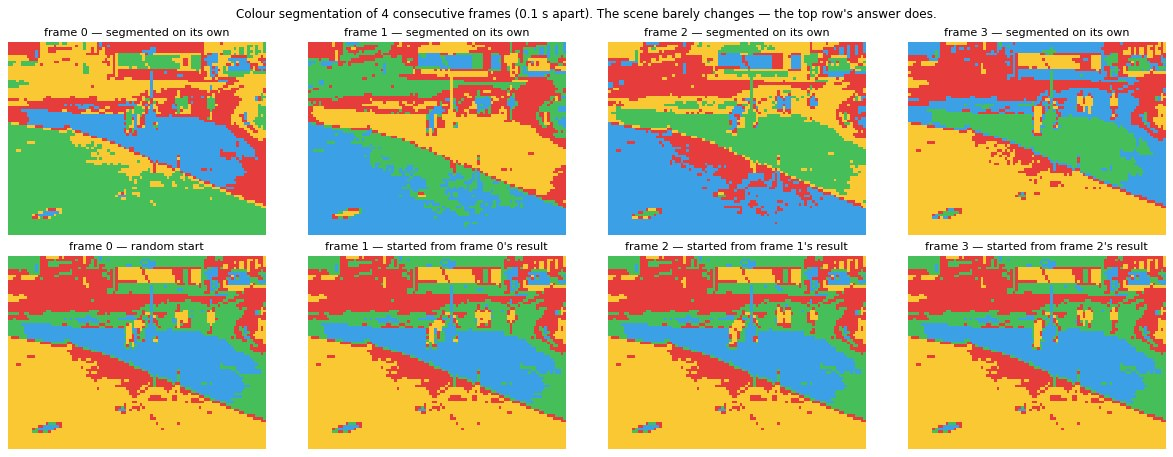

frame-to-frame change                                  share of pixels
-----------------------------------------------------  ---------------
pixels whose colour really changed (> 20 grey levels)  1.3%           
label changes, each frame segmented independently      69.4%          
label changes, initialised from the previous frame     1.3%           

MiDaS on static pixels — input changes by 0.09% of its range per frame, the network's output by 0.94%; after temporal smoothing 0.27%.

Random crop, mean |frame(t+1) - frame(t)| in grey levels:
  one crop for the whole clip: 2.8
  a new crop for every frame:  41.2   ← fake motion that a video model would have to explain


In [32]:
# --- 9.3 🔬 Temporal consistency: per-frame decisions flicker; using the previous frame fixes it  [measured] ---
rng_tc = np.random.default_rng(SEED)
PALETTE = np.array([[230, 60, 60], [60, 160, 230], [250, 200, 50], [70, 190, 90]], np.uint8)
small = np.stack([cv2.resize(f, (96, 72), interpolation=cv2.INTER_AREA) for f in clip[:12]])  # 12 consecutive frames


def kmeans_segment(image: np.ndarray, centres: np.ndarray, iterations: int):
    """Colour segmentation by k-means. Returns (label image, final cluster centres)."""
    pixels = image.reshape(-1, 3).astype(np.float32)
    for _ in range(iterations):
        labels = np.argmin(((pixels[:, None] - centres[None]) ** 2).sum(axis=2), axis=1)
        centres = np.stack(
            [pixels[labels == k].mean(axis=0) if np.any(labels == k) else centres[k] for k in range(len(centres))]
        )
    return labels.reshape(image.shape[:2]), centres


def random_centres(image: np.ndarray) -> np.ndarray:
    return image.reshape(-1, 3)[rng_tc.choice(image.shape[0] * image.shape[1], len(PALETTE), replace=False)].astype(
        np.float32
    )


independent = [
    kmeans_segment(frame, random_centres(frame), 10)[0] for frame in small
]  # every frame starts from scratch
consistent, centres = [], random_centres(small[0])
for frame in small:  # every frame starts from the PREVIOUS answer
    labels, centres = kmeans_segment(frame, centres, 10 if not consistent else 2)
    consistent.append(labels)


def flicker(label_frames) -> float:
    """Share of pixels whose label changes between consecutive frames."""
    return float(np.mean([np.mean(a != b) for a, b in zip(label_frames[:-1], label_frames[1:])]))


real_change = float(np.mean(np.abs(np.diff(small.astype(np.float32), axis=0)).max(axis=3) > 20))
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6), constrained_layout=True)
for col in range(4):
    axes[0, col].imshow(PALETTE[independent[col]])
    axes[0, col].set_title(f"frame {col} — segmented on its own")
    axes[1, col].imshow(PALETTE[consistent[col]])
    axes[1, col].set_title(f"frame {col} — started from frame {col - 1}'s result" if col else "frame 0 — random start")
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(
    "Colour segmentation of 4 consecutive frames (0.1 s apart). The scene barely changes — the top row's answer does."
)
plt.show()
table(
    [
        ("pixels whose colour really changed (> 20 grey levels)", f"{real_change:.1%}"),
        ("label changes, each frame segmented independently", f"{flicker(independent):.1%}"),
        ("label changes, initialised from the previous frame", f"{flicker(consistent):.1%}"),
    ],
    ["frame-to-frame change", "share of pixels"],
)

# The same effect in a real network: per-frame monocular depth on pixels where NOTHING moves
if globals().get("HAVE_MIDAS", False):
    depth_seq = np.stack([midas_inverse_depth(f) for f in clip[:12]])
    span = float(depth_seq.max() - depth_seq.min())
    smoothed = depth_seq.copy()
    for t in range(1, len(smoothed)):
        smoothed[t] = 0.7 * smoothed[t - 1] + 0.3 * depth_seq[t]  # exponential moving average over time
    per_frame = np.abs(np.diff(depth_seq, axis=0))[:, static].mean() / span
    after_ema = np.abs(np.diff(smoothed, axis=0))[:, static].mean() / span
    input_change = np.abs(np.diff(clip_gray[:12].astype(np.float32), axis=0))[:, static].mean() / 255
    print(
        f"\nMiDaS on static pixels — input changes by {input_change:.2%} of its range per frame, "
        f"the network's output by {per_frame:.2%}; "
        f"after temporal smoothing {after_ema:.2%}."
    )

# Preprocessing: the SAME random crop for the whole clip, or a new one for every frame?
CROP = 200
y0, x0 = rng_tc.integers(0, VH - CROP), rng_tc.integers(0, VW - CROP)
clip_crop = clip_gray[:12, y0 : y0 + CROP, x0 : x0 + CROP].astype(np.float32)
jitter_crop = np.stack(
    [
        clip_gray[t, y : y + CROP, x : x + CROP]
        for t, (y, x) in enumerate(zip(rng_tc.integers(0, VH - CROP, 12), rng_tc.integers(0, VW - CROP, 12)))
    ]
).astype(np.float32)
print(
    f"\nRandom crop, mean |frame(t+1) - frame(t)| in grey levels:\n"
    f"  one crop for the whole clip: {np.abs(np.diff(clip_crop, axis=0)).mean():.1f}\n"
    f"  a new crop for every frame:  {np.abs(np.diff(jitter_crop, axis=0)).mean():.1f}"
    "   ← fake motion that a video model would have to explain"
)

The idea in one line (JPEG, quality 80): a whole frame costs 20.5 KB, the difference to the previous frame only 3.4 KB.

stream                           frames  mean size
-------------------------------  ------  ---------
vtest.avi (MPEG-4): I-frames     4       72.9 KB  
vtest.avi (MPEG-4): P-frames     791     9.6 KB   
re-encoded with H.264: I-frames  3       99.2 KB  
re-encoded with H.264: P-frames  45      10.3 KB  
re-encoded with H.264: B-frames  42      2.0 KB   

keyframes of vtest.avi at frame numbers [0, 250, 500, 750] → to display frame 249 a player must first decode 249 frames (25 s of video).


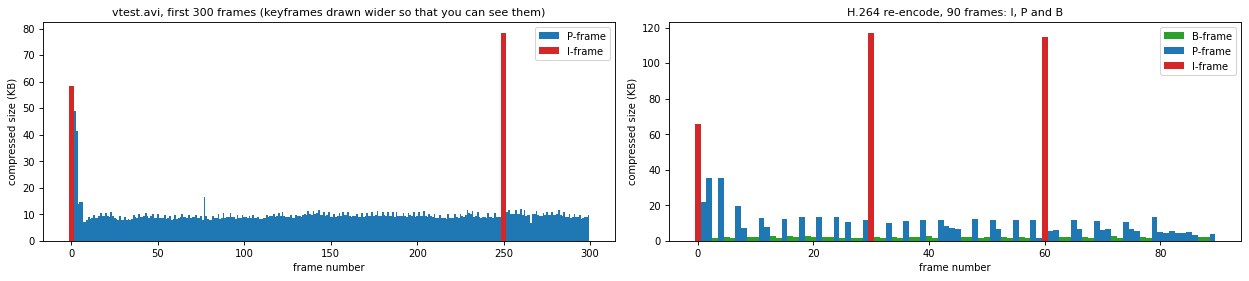

In [33]:
# --- 9.4 🔬 Compression: I-, P- and B-frames in a real file  [measured] -------------------------
def encoded_kb(image: np.ndarray) -> float:
    return len(cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, 80])[1]) / 1024


f0, f1 = clip_gray[10].astype(np.int16), clip_gray[11].astype(np.int16)
residual = np.clip(f1 - f0 + 128, 0, 255).astype(np.uint8)  # what changed, shifted to mid-grey
print(
    f"The idea in one line (JPEG, quality 80): a whole frame costs {encoded_kb(clip_gray[11]):.1f} KB, "
    f"the difference to the previous frame only {encoded_kb(residual):.1f} KB.\n"
)


def frame_types(path):
    """Ask ffprobe for (picture type, compressed size in bytes) of every frame. Returns None if ffprobe is unavailable."""
    if shutil.which("ffprobe") is None:
        return None
    out = subprocess.run(
        [
            "ffprobe",
            "-v",
            "error",
            "-select_streams",
            "v:0",
            "-show_entries",
            "frame=pict_type,pkt_size",
            "-of",
            "csv=p=0",
            str(path),
        ],
        capture_output=True,
        text=True,
    )
    frames = []
    for row in csv.reader(out.stdout.splitlines()):
        kind = [c for c in row if c.isalpha()]
        size = [c for c in row if c.isdigit()]
        if kind and size:
            frames.append((kind[0], int(size[0])))
    return frames or None


def summarise(frames, label: str):
    rows = []
    for kind in ("I", "P", "B"):
        sizes = [s for k, s in frames if k == kind]
        if sizes:
            rows.append((f"{label}: {kind}-frames", len(sizes), f"{np.mean(sizes) / 1024:.1f} KB"))
    return rows


original = frame_types(VIDEO)
if original is None:
    print(
        "ffprobe not found → skipping the real-file analysis (on Colab it is pre-installed; locally: install FFmpeg)."
    )
else:
    rows = summarise(original, "vtest.avi (MPEG-4)")
    h264_path, h264 = OUT / "vtest_h264.mp4", None
    if shutil.which("ffmpeg") is not None:  # re-encode 9 s with a modern codec that uses B-frames
        done = subprocess.run(
            [
                "ffmpeg",
                "-y",
                "-loglevel",
                "error",
                "-i",
                str(VIDEO),
                "-frames:v",
                "90",
                "-c:v",
                "libx264",
                "-g",
                "30",
                "-bf",
                "2",
                "-pix_fmt",
                "yuv420p",
                str(h264_path),
            ],
            capture_output=True,
            text=True,
        )
        h264 = frame_types(h264_path) if done.returncode == 0 else None
    if h264:
        rows += summarise(h264, "re-encoded with H.264")
    table(rows, ["stream", "frames", "mean size"])
    keyframes = [k for k, (kind, _) in enumerate(original) if kind == "I"]
    gap = int(np.max(np.diff(keyframes))) if len(keyframes) > 1 else len(original)
    print(
        f"\nkeyframes of vtest.avi at frame numbers {keyframes} → "
        f"to display frame {keyframes[0] + gap - 1} a player must first decode "
        f"{gap - 1} frames ({(gap - 1) / FPS:.0f} s of video)."
    )

    panels = [(original[:300], "vtest.avi, first 300 frames (keyframes drawn wider so that you can see them)")]
    if h264:
        panels.append((h264, "H.264 re-encode, 90 frames: I, P and B"))
    fig, axes = plt.subplots(1, len(panels), figsize=(7.75 * len(panels), 3.4), squeeze=False, constrained_layout=True)
    colour = {"I": "tab:red", "P": "tab:blue", "B": "tab:green"}
    for ax, (frames, title) in zip(axes[0], panels):
        for kind in ("B", "P", "I"):  # draw keyframes last, on top
            idx = [k for k, (c, _) in enumerate(frames) if c == kind]
            if idx:
                ax.bar(
                    idx,
                    [frames[k][1] / 1024 for k in idx],
                    color=colour[kind],
                    label=f"{kind}-frame",
                    width=max(1.0, len(frames) / 100) if kind == "I" else 1.0,
                )
        ax.set_xlabel("frame number")
        ax.set_ylabel("compressed size (KB)")
        ax.set_title(title)
        ax.legend()
    plt.show()

**Read the result.**
- **x–t slice:** static background makes vertical stripes; each walking person makes a slanted streak. The slope *is* the speed
  (pixels per second), and the direction of the slant is the walking direction. Motion has become a geometric shape in a 3D block of data.
- **Sparse vs dense flow:** Lucas–Kanade follows a few hundred well-textured corners cheaply (tracking, visual odometry in Part 8);
  Farnebäck gives every pixel a vector (motion segmentation, frame interpolation, the temporal-consistency checks below).
- **Flicker:** almost no pixel really changes between two frames, yet independent per-frame segmentation relabels a large share of the image.
  Much of that is the *same* regions receiving *different* labels — exactly the identity problem that tracking solved on Day 35.
  Carrying information over from the previous frame removes it. A real depth network shows the same effect on pixels where nothing moves at all.
- **Preprocessing:** a new random crop per frame turns a still scene into violent "motion". For video, sample augmentation parameters **once per clip**.
- **Codecs:** a keyframe is several times larger than a predicted frame; B-frames are the smallest. The price is random access —
  and the reason video data-loaders are slow when they jump to arbitrary frames.

🌍 **Real world.** Traffic and crowd analytics from CCTV (flow → speed and direction), video stabilisation, sports tracking,
and every video training pipeline: the decode cost of long-GOP video is often the real bottleneck, not the GPU.

⚠️ **Pitfall (§11).** A model that looks good on single frames can still be unusable as video. Measure temporal consistency explicitly
(here: change on pixels that should not change) — do not judge it from frame-by-frame scores.

✍️ **Exercise 9 (2 min).**
1. In the x–t slice, how would a person standing still for two seconds appear? And someone walking twice as fast as the others?
2. Why may the random crop differ between *clips* but not between *frames* of one clip?
3. The file has a keyframe only every 250 frames. Name one advantage and one disadvantage compared with a keyframe every 10 frames.

<details><summary>Show answer</summary>

1. Standing still → a vertical stripe (x does not change with time). Twice as fast → a streak with half the slope in this plot
   (twice the horizontal distance per second).
2. Between clips, variety is the purpose of augmentation. Within a clip, the model must see true motion; a changing crop adds a random
   shift to every pixel that has nothing to do with the scene and destroys the temporal signal.
3. Advantage: far smaller files, since P-frames cost a fraction of an I-frame. Disadvantage: slow seeking (up to 249 frames must be decoded first)
   and poor robustness — a damaged frame corrupts everything up to the next keyframe.

</details>

---
# Part 10 — Video diffusion and neural 3D representations  *(5 min · §9)*

🧠 **Concept.** Three ideas at the research frontier, each reduced to something you can run in a second:

| Idea | Core mechanism | What we run here `[toy]` |
|---|---|---|
| **Video diffusion** (§9.1) | an image-diffusion denoiser + **temporal layers**, so that each frame is denoised with knowledge of its neighbours | one denoising step on a real clip, with and without looking along time |
| **NeRF** (§9.2) | the scene is a *function* (x, y, z, direction) → (colour, density); a pixel is rendered by sampling that function along its ray | the volume-rendering equation on a hand-written field |
| **3D Gaussian Splatting** (§9.3) | the scene is an explicit list of coloured, semi-transparent 3D Gaussians that are projected and blended | a 30-line splatting renderer for the *same* scene |

We do **not** train a diffusion model, a NeRF or a splat scene here — that takes minutes to hours on a GPU.
We run the part that explains *why they work*: the image-formation step.

*Needs:* Part 0, and `clip_gray`, `static`, `ROW`, `FPS` from Part 9.

video                            PSNR     flicker (static px)  error, static px  error, moving px
-------------------------------  -------  -------------------  ----------------  ----------------
clean video (reference)          —        0.0009               —                 —               
noisy input x_t                  4.8 dB   0.6513               —                 —               
denoised frame by frame          19.8 dB  0.0927               0.0772            0.0850          
denoised with a look along time  22.6 dB  0.0088               0.0446            0.0658          

Looking along time cuts the error by 42% where nothing moves, but only by 23% where something moves.


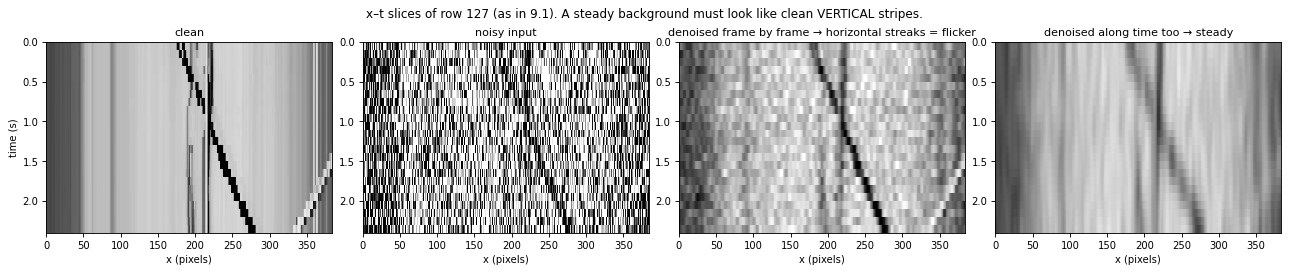

In [34]:
# --- 10.1 🔬 Why video diffusion needs temporal layers: denoise frame by frame vs. along time  [toy] ---
rng_vd = np.random.default_rng(SEED)
clean = clip_gray[:24].astype(np.float32) / 255.0  # 24 real frames, values 0…1
ALPHA_BAR = 0.75  # diffusion noise level: signal^2 share that is left
noisy = np.sqrt(ALPHA_BAR) * clean + np.sqrt(1 - ALPHA_BAR) * rng_vd.normal(
    size=clean.shape
)  # forward process q(x_t | x_0)

# Two stand-ins for "the denoiser" (a trained network in a real model). Both smooth in space; only one may look along time.
per_frame = ndimage.gaussian_filter(noisy, sigma=(0, 2.0, 2.0)) / np.sqrt(
    ALPHA_BAR
)  # sigma_time = 0 → each frame alone
with_time = ndimage.gaussian_filter(noisy, sigma=(2.0, 2.0, 2.0)) / np.sqrt(
    ALPHA_BAR
)  # also averages over neighbouring frames


def psnr(estimate: np.ndarray, reference: np.ndarray) -> float:
    return float(10 * np.log10(1.0 / np.mean((estimate - reference) ** 2)))


def flicker_static(video: np.ndarray) -> float:
    """Mean frame-to-frame change on pixels where the real scene does not change at all (0 = perfectly steady)."""
    return float(np.abs(np.diff(video, axis=0))[:, static].mean())


def mean_error(video: np.ndarray, where: np.ndarray) -> float:
    return float(np.abs(video - clean)[:, where].mean())


e_static = [mean_error(v, static) for v in (per_frame, with_time)]
e_moving = [mean_error(v, ~static) for v in (per_frame, with_time)]
table(
    [
        ("clean video (reference)", "—", f"{flicker_static(clean):.4f}", "—", "—"),
        (
            "noisy input x_t",
            f"{psnr(noisy / np.sqrt(ALPHA_BAR), clean):.1f} dB",
            f"{flicker_static(noisy / np.sqrt(ALPHA_BAR)):.4f}",
            "—",
            "—",
        ),
        (
            "denoised frame by frame",
            f"{psnr(per_frame, clean):.1f} dB",
            f"{flicker_static(per_frame):.4f}",
            f"{e_static[0]:.4f}",
            f"{e_moving[0]:.4f}",
        ),
        (
            "denoised with a look along time",
            f"{psnr(with_time, clean):.1f} dB",
            f"{flicker_static(with_time):.4f}",
            f"{e_static[1]:.4f}",
            f"{e_moving[1]:.4f}",
        ),
    ],
    ["video", "PSNR", "flicker (static px)", "error, static px", "error, moving px"],
)
print(
    f"\nLooking along time cuts the error by {1 - e_static[1] / e_static[0]:.0%} where nothing moves, but only by "
    f"{1 - e_moving[1] / e_moving[0]:.0%} where something moves."
)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.3), constrained_layout=True)
for ax, video, title in zip(
    axes,
    (clean, noisy / np.sqrt(ALPHA_BAR), per_frame, with_time),
    (
        "clean",
        "noisy input",
        "denoised frame by frame → horizontal streaks = flicker",
        "denoised along time too → steady",
    ),
):
    ax.imshow(
        video[:, ROW], cmap="gray", aspect="auto", vmin=0, vmax=1, extent=(0, video.shape[2], len(video) / FPS, 0)
    )
    ax.set_title(title)
    ax.set_xlabel("x (pixels)")
axes[0].set_ylabel("time (s)")
fig.suptitle(f"x–t slices of row {ROW} (as in 9.1). A steady background must look like clean VERTICAL stripes.")
plt.show()

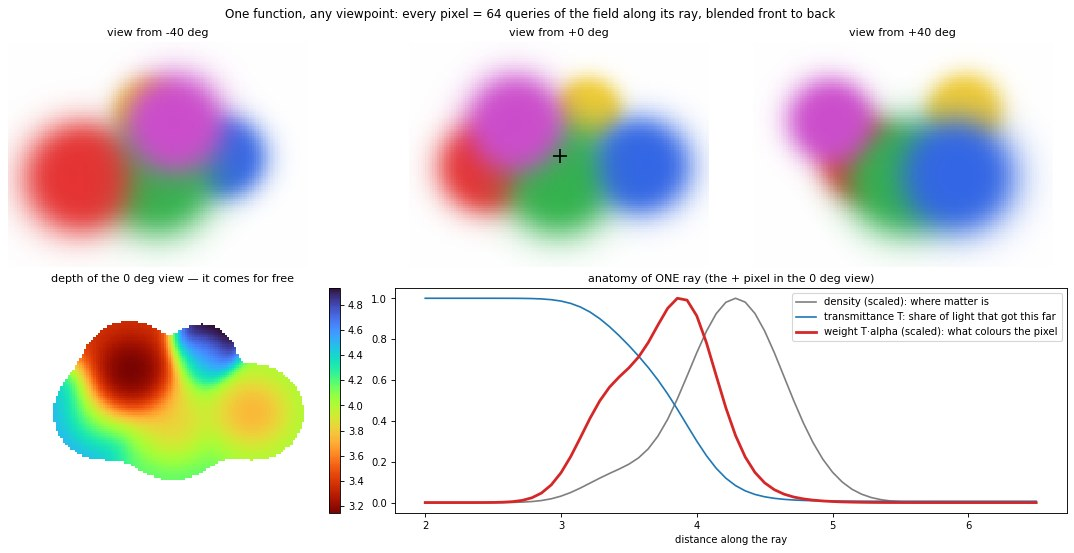

128x96 px x 64 samples = 786,432 field queries per image (529 ms each here; in a real NeRF every query is a neural-network evaluation)


In [35]:
# --- 10.2 🔬 NeRF in one equation: a scene stored as a function, rendered by sampling along rays  [toy] ---
# The "scene": 5 fuzzy coloured blobs. In a real NeRF this function is a neural network trained from photos.
BLOB_CENTRE = np.array([[-1.0, 0.2, 0.2], [0.0, 0.3, 0.0], [1.0, 0.1, -0.3], [0.45, -0.55, 0.8], [-0.45, -0.45, -0.8]])
BLOB_SIZE = np.array([0.30, 0.36, 0.28, 0.24, 0.24])
BLOB_COLOUR = np.array([[0.9, 0.2, 0.2], [0.2, 0.7, 0.3], [0.2, 0.4, 0.9], [0.95, 0.8, 0.2], [0.8, 0.3, 0.8]])
BLOB_DENSITY = np.array([9.0, 7.0, 9.0, 12.0, 10.0])
NV_W, NV_H, NV_F = 128, 96, 135.0  # a small virtual camera
N_SAMPLES, NEAR, FAR = 64, 2.0, 6.5


def radiance_field(points: np.ndarray):
    """F(x, y, z) → (colour, density). points: (..., 3). This plays the role of the NeRF network."""
    sq_dist = ((points[..., None, :] - BLOB_CENTRE) ** 2).sum(axis=-1)  # (..., 5)
    per_blob = BLOB_DENSITY * np.exp(-sq_dist / (2 * BLOB_SIZE**2))
    density = per_blob.sum(axis=-1)
    colour = (per_blob[..., None] * BLOB_COLOUR).sum(axis=-2) / (density[..., None] + 1e-9)
    return colour, density


def camera_rays(azimuth_deg: float, radius: float = 4.2, height: float = 0.6):
    """A camera on a circle around the scene, looking at the origin.

    Returns (camera centre, ray directions of shape (H, W, 3), rotation world → camera).
    """
    a = np.radians(azimuth_deg)
    centre = np.array([radius * np.sin(a), -height, -radius * np.cos(a)])
    forward = -centre / np.linalg.norm(centre)
    right = np.cross([0.0, 1.0, 0.0], forward)
    right /= np.linalg.norm(right)
    down = np.cross(forward, right)
    cam_to_world = np.column_stack([right, down, forward])
    u, v = np.meshgrid(np.arange(NV_W) + 0.5, np.arange(NV_H) + 0.5)
    dirs = np.stack([(u - NV_W / 2) / NV_F, (v - NV_H / 2) / NV_F, np.ones_like(u)], axis=-1) @ cam_to_world.T
    return centre, dirs / np.linalg.norm(dirs, axis=-1, keepdims=True), cam_to_world.T


def render_volume(centre: np.ndarray, dirs: np.ndarray, n_samples: int = N_SAMPLES):
    """Volume rendering:  C = sum_i  T_i * alpha_i * c_i

    with  alpha_i = 1 - exp(-density_i * step)  and  T_i = prod_{j<i} (1 - alpha_j).
    """
    t = np.linspace(NEAR, FAR, n_samples)
    points = centre + dirs[..., None, :] * t[:, None]  # (H, W, N, 3): N samples on every ray
    colour, density = radiance_field(points)
    alpha = 1.0 - np.exp(-density * (t[1] - t[0]))  # chance that the ray is stopped in this step
    transmittance = np.cumprod(np.concatenate([np.ones_like(alpha[..., :1]), 1.0 - alpha[..., :-1]], axis=-1), axis=-1)
    weights = transmittance * alpha  # how much each sample contributes to the pixel
    image = (weights[..., None] * colour).sum(axis=-2) + (1.0 - weights.sum(axis=-1, keepdims=True))  # white background
    depth = (weights * t).sum(axis=-1) / (weights.sum(axis=-1) + 1e-9)
    return image, depth, (t, density, transmittance, weights)


t0 = time.time()
views = {az: render_volume(*camera_rays(az)[:2]) for az in (-40, 0, 40)}
t_nerf = (time.time() - t0) / len(views)
image_0, depth_0, (t_ray, dens, trans, wts) = views[0]
py, px = NV_H // 2, NV_W // 2  # the ray through the centre pixel

fig, axd = plt.subplot_mosaic(
    [["-40", "0", "40"], ["depth", "ray", "ray"]], figsize=(13.5, 6.8), constrained_layout=True
)
for az, (img, _, _) in views.items():
    axd[str(az)].imshow(np.clip(img, 0, 1))
    axd[str(az)].set_title(f"view from {az:+d} deg")
    axd[str(az)].axis("off")
axd["0"].scatter([px], [py], marker="+", s=160, color="k")
opacity = wts.sum(axis=-1)
handle = axd["depth"].imshow(np.where(opacity > 0.5, depth_0, np.nan), cmap="turbo_r")
axd["depth"].set_title("depth of the 0 deg view — it comes for free")
axd["depth"].axis("off")
fig.colorbar(handle, ax=axd["depth"], fraction=0.046, pad=0.02)
axd["ray"].plot(t_ray, dens[py, px] / dens[py, px].max(), label="density (scaled): where matter is", color="tab:gray")
axd["ray"].plot(t_ray, trans[py, px], label="transmittance T: share of light that got this far", color="tab:blue")
axd["ray"].plot(
    t_ray,
    wts[py, px] / wts[py, px].max(),
    label="weight T·alpha (scaled): what colours the pixel",
    color="tab:red",
    lw=2.5,
)
axd["ray"].set_xlabel("distance along the ray")
axd["ray"].set_title("anatomy of ONE ray (the + pixel in the 0 deg view)")
axd["ray"].legend()
fig.suptitle("One function, any viewpoint: every pixel = 64 queries of the field along its ray, blended front to back")
plt.show()
print(
    f"{NV_W}x{NV_H} px x {N_SAMPLES} samples = {NV_W * NV_H * N_SAMPLES:,} field queries per image "
    f"({t_nerf * 1000:.0f} ms each here; "
    f"in a real NeRF every query is a neural-network evaluation)"
)

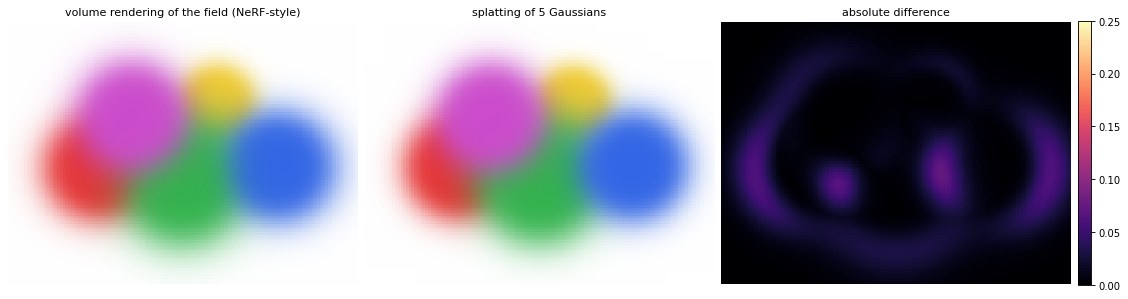

renderer                                  work per image                     time (NumPy, this machine)
----------------------------------------  ---------------------------------  --------------------------
NeRF-style: sample a function along rays  786,432 field queries              529.1 ms                  
splatting: draw explicit primitives       5 Gaussians, 27,090 pixel updates  1.8 ms                    
mean absolute difference between the two images: 0.0143 (on a 0…1 colour scale)


In [36]:
# --- 10.3 🔬 Gaussian splatting: the same scene as 5 explicit primitives, projected and blended  [toy] ---
def render_splats(centre: np.ndarray, world_to_cam: np.ndarray):
    """Project each 3D Gaussian to a 2D blob and alpha-blend front to back. Returns (image, number of pixel updates)."""
    cam = (BLOB_CENTRE - centre) @ world_to_cam.T  # blob centres in camera coordinates
    image, light_left, touched = np.zeros((NV_H, NV_W, 3)), np.ones((NV_H, NV_W)), 0
    for k in np.argsort(cam[:, 2]):  # nearest blob first
        u0, v0 = NV_F * cam[k, 0] / cam[k, 2] + NV_W / 2, NV_F * cam[k, 1] / cam[k, 2] + NV_H / 2
        radius_px = NV_F * BLOB_SIZE[k] / cam[k, 2]  # perspective: far blobs look smaller
        x_lo, x_hi = max(int(u0 - 4 * radius_px), 0), min(int(u0 + 4 * radius_px) + 1, NV_W)  # only touch its footprint
        y_lo, y_hi = max(int(v0 - 4 * radius_px), 0), min(int(v0 + 4 * radius_px) + 1, NV_H)
        if x_lo >= x_hi or y_lo >= y_hi:
            continue
        v, u = np.mgrid[y_lo:y_hi, x_lo:x_hi] + 0.5
        footprint = np.exp(-((u - u0) ** 2 + (v - v0) ** 2) / (2 * radius_px**2))
        alpha = 1.0 - np.exp(
            -BLOB_DENSITY[k] * BLOB_SIZE[k] * np.sqrt(2 * np.pi) * footprint
        )  # density integrated through the blob
        image[y_lo:y_hi, x_lo:x_hi] += (light_left[y_lo:y_hi, x_lo:x_hi] * alpha)[..., None] * BLOB_COLOUR[k]
        light_left[y_lo:y_hi, x_lo:x_hi] *= 1.0 - alpha
        touched += alpha.size
    return image + light_left[..., None], touched  # white background


centre_0, dirs_0, w2c_0 = camera_rays(0)
t0 = time.time()
for _ in range(20):
    splat_image, pixel_updates = render_splats(centre_0, w2c_0)
t_splat = (time.time() - t0) / 20
difference = np.abs(splat_image - image_0)

show(
    [np.clip(image_0, 0, 1), np.clip(splat_image, 0, 1), difference.mean(axis=2)],
    ["volume rendering of the field (NeRF-style)", "splatting of 5 Gaussians", "absolute difference"],
    cmap=[None, None, "magma"],
    vmin=0,
    vmax=0.25,
    figsize=(14, 3.6),
    colorbar=True,
)
table(
    [
        (
            "NeRF-style: sample a function along rays",
            f"{NV_W * NV_H * N_SAMPLES:,} field queries",
            f"{t_nerf * 1000:.1f} ms",
        ),
        (
            "splatting: draw explicit primitives",
            f"{len(BLOB_CENTRE)} Gaussians, {pixel_updates:,} pixel updates",
            f"{t_splat * 1000:.1f} ms",
        ),
    ],
    ["renderer", "work per image", "time (NumPy, this machine)"],
)
print(f"mean absolute difference between the two images: {difference.mean():.4f} (on a 0…1 colour scale)")

**Read the result.**
- **Video diffusion.** Denoising each frame alone leaves a *different* random error in every frame — in the x–t slice the steady background
  is torn into horizontal streaks. Letting the denoiser look along time removes most of the flicker **and** improves quality, because neighbouring
  frames are extra evidence about the same scene. The printed line shows the catch: the gain is clearly smaller where things move, because a fixed
  average also smears motion (look at the walker's streak in the last panel).
  Real video models therefore use learned temporal *attention* rather than a fixed average — that is the "temporal layer" of §9.1.
- **NeRF.** The ray plot is the whole method: density says where matter is, transmittance says how much light survives up to there,
  and their product decides which samples colour the pixel. Change the camera and the *same* function yields a new, consistent view (and a depth map).
  The cost is the number of queries per image.
- **Gaussian splatting.** The same picture from a list of five primitives, with a small fraction of the work — explicit geometry can be
  drawn, a function has to be searched. The small difference between the two images comes from blending whole blobs in depth order instead of
  integrating exactly along each ray.

**Back to the representation spectrum (§9.4)** — with what you measured today:

| Representation | Explicit or implicit? | Rendering speed | Novel views? | In this lab |
|---|---|---|---|---|
| Point cloud / mesh (§6.1) | explicit | fast | limited — gaps where nothing was captured | 7.1: black holes in the virtual photo |
| Voxel grid (§6.1) | explicit | fast, at high memory cost | limited — capped by resolution | 7.2: memory grows with resolution cubed |
| NeRF (§9.2) | implicit | slow — many queries per pixel | yes, its defining ability | 10.2: 64 queries for every pixel |
| Gaussian Splatting (§9.3) | explicit | fast — real-time | yes, with less compute than NeRF | 10.3: 5 primitives, a fraction of the work |

🌍 **Real world.** Text-to-video generation; virtual tours, VR and digital twins from phone photos; robot simulation in reconstructed places.
**The link back to Part 8:** both NeRF and Gaussian Splatting need the camera pose of every training photo — and that comes from
Structure from Motion. Training then adjusts the network weights (NeRF) or the Gaussians (3DGS) until rendered views match the photos.

✍️ **Exercise 10 (1 min).**
1. In the ray plot, why does the red weight curve drop to zero *behind* the first blob even where the density is still high?
2. Set `N_SAMPLES = 8` in cell 10.2 and re-run it; then try `4`. At which setting does the picture break, and what does that tell you about thin objects?
3. In 10.1 the temporal filter helps less on moving pixels. What would a smarter "temporal layer" do differently?

<details><summary>Show answer</summary>

1. Transmittance: the first blob already absorbed (almost) all of the light, so samples behind it cannot contribute —
   that is how occlusion emerges from the equation without any explicit visibility test.
2. With 8 samples (0.64 units apart) the picture is almost unchanged; with 4 (1.5 units apart) blobs fade or change brightness.
   A field must be sampled more finely than its smallest structure. These fuzzy blobs are about 0.3 units wide and forgive coarse sampling;
   real scenes have thin, sharp surfaces and do not — which is why NeRF needs many samples per ray (hierarchical sampling), and why it is slow.
3. Follow the motion instead of averaging in place: compare each pixel with where it *was* in the neighbouring frames
   (optical flow from Part 9, or attention that finds the matching content by itself).

</details>

---
# Part 11 — Debugging checklist, PP17 bridge, research frontiers  *(2 min · §10–11)*

A stereo pipeline has many stages, and a bad depth map can be caused by any of them. The notes give a checklist (§11);
here it is as code you can paste into your own project.

*Needs:* Parts 0, 3, 4 and 5.

In [37]:
# --- 11.1 🔬 Three silent bugs and one guard function  [measured on our own rig] ----------------
def stereo_sanity_check(focal_px: float, baseline_m: float, disparity: np.ndarray, image_width: int) -> list:
    """Cheap tests for the classic SILENT errors of a stereo pipeline. An empty list means nothing looks suspicious."""
    issues = []
    if not 0.01 <= baseline_m <= 2.0:
        issues.append(f"baseline {baseline_m:.3g} 'm' is not between 1 cm and 2 m — typed in mm or cm?")
    if not 0.3 <= focal_px / image_width <= 5.0:
        issues.append(f"focal length {focal_px:g} 'px' on a {image_width}-px image — typed in mm?")
    if float(np.nanmax(disparity)) > image_width:
        issues.append("disparity exceeds the image width — forgot to divide by 16?")
    if float(np.mean(disparity > 0)) < 0.2:
        issues.append(f"only {np.mean(disparity > 0):.0%} of pixels matched — check rectification and search range")
    return issues


f_ok, b_ok, d_ok = RECT_A["f"], RECT_A["baseline"], results["A"]["disp"]
corner_u, corner_v = np.round(rectified_corners(RECT_A, PAIR)[0]).astype(int).T


def board_distance(focal_px: float, baseline: float, disparity: np.ndarray) -> float:
    """Median depth at the checkerboard corners — the number a script would print without complaining."""
    d = disparity[corner_v, corner_u]
    return float(np.median(focal_px * baseline / d[d > 0]))


cases = [
    ("everything right", f_ok, b_ok, d_ok),
    ("baseline typed in millimetres", f_ok, b_ok * 1000, d_ok),
    ("SGBM output not divided by 16", f_ok, b_ok, d_ok * 16),
    ("focal length entered in mm (4.0)", 4.0, b_ok, d_ok),
]
rows = []
for name, f_px, base, disp in cases:
    issues = stereo_sanity_check(f_px, base, disp, IMG_SIZE[0])
    rows.append((name, f"{board_distance(f_px, base, disp):.4g}", issues[0] if issues else "OK"))
table(rows, ["what happened", "board distance printed", "stereo_sanity_check says"])
print(
    f"(true board distance: {np.mean(results['A']['z_ref']):.3f} m — none of the wrong runs raised an error by itself)\n"
)

with np.errstate(divide="ignore"):
    depth_all = f_ok * b_ok / d_ok  # careless: unmatched pixels carry disparity -1 (or 0)
print(
    f"Invalid pixels: without a mask, {np.mean(depth_all < 0):.0%} of the pixels get a depth of "
    f"{np.median(depth_all[depth_all < 0]):.1f} m "
    f"(behind the camera!) and any average is nonsense.\n"
    f"                With the mask: median depth of the matched pixels = {np.median(depth_all[d_ok > 0]):.2f} m"
)

what happened                     board distance printed  stereo_sanity_check says                                          
--------------------------------  ----------------------  ------------------------------------------------------------------
everything right                  0.3818                  OK                                                                
baseline typed in millimetres     381.8                   baseline 83.6 'm' is not between 1 cm and 2 m — typed in mm or cm?
SGBM output not divided by 16     0.02386                 disparity exceeds the image width — forgot to divide by 16?       
focal length entered in mm (4.0)  0.002933                focal length 4 'px' on a 640-px image — typed in mm?              
(true board distance: 0.384 m — none of the wrong runs raised an error by itself)

Invalid pixels: without a mask, 50% of the pixels get a depth of -43.6 m (behind the camera!) and any average is nonsense.
                With the mask: median depth 

### The §11 checklist — and where you already did each step today

| # | Check (work through them in this order) | Done in |
|---|---|---|
| 1 | **Verify calibration before debugging disparity.** A wrong $f$ or baseline scales every depth. | 3.2 (vs. reference file), 3.3, 3.4 |
| 2 | **Confirm rectification by inspection.** Corresponding points must share a row. | 4.4 (row-error table + yellow lines) |
| 3 | **Textureless failure is a property of the scene, not a bug.** | 6.1 (cost curves, real checkerboard) |
| 4 | **Do not score unmatched pixels as wrong.** Mask them; report density next to error. | 5.3, 11.1 |
| 5 | **Separate calibration error from disparity-estimation error** when comparing Path A and Path B. | 4.3, 4.4, 5.4 |
| 6 | **Keep units consistent:** baseline in metres, focal length and disparity in pixels. Sanity-check against one known distance. | 5.4 (board at 0.38 m), 11.1 |

**Reproducibility (§11).** RANSAC is random and a calibration depends on which photos you took. Fix seeds (cell 0.1),
and measure the spread instead of trusting one run — 3.4 did that for calibration, the 13-pair table in 4.3 for pose.

**Published benchmarks (§11).** Leaderboard numbers come from tuned or trained methods under controlled conditions.
Expect your error to be higher. The comparison that counts is *your* Path A against *your* Path B under identical settings.

---
### From this lab to assignment PP17 (3D Reconstruction from Stereo Images)

| PP17 deliverable | Technique shown in | What must be **your own** |
|---|---|---|
| **Path A** — disparity + depth for a calibrated, rectified pair; error vs. ground truth | 5.2, 5.3 | a pair of your choice (another Middlebury scene, or KITTI); your numbers, with density |
| **Path B** — own intrinsics, own fundamental matrix, own rectification, same matcher | 3.1–3.3, 4.1–4.4, 5.4 | your calibration and your pair (self-captured is the most instructive) |
| Point cloud (optional, encouraged) | 7.1 | back-projection with *your* intrinsics; a `.ply` you can open |
| **Comparison + written error attribution** (25 % of the grade) | 5.4 is the template | which stage causes which error in *your* data, backed by measurements |
| Code quality and README | every cell here: typed, commented, seeded | how to reproduce your results |

The lab shows the *method* on sample data. PP17 is graded on your data, your measurements and your reasoning —
re-using these functions is fine, re-using these numbers is not.

---
### Research frontiers (§10) — where each part of today leads

- **Real-time neural 3D reconstruction (§10.1):** Part 8's incremental SLAM + Part 10's neural rendering, built on the fly from a live camera.
- **Consistent long video generation (§10.2):** the flicker you measured in 9.3 and 10.1, over hundreds of frames instead of twelve.
- **3D-aware generative models (§10.3):** generate a scene that can be rendered from *any* viewpoint, not a single flat image.
- **Day 37 — medical imaging (§10.4):** CT and MRI are voxel grids by nature; the cubic memory growth from 7.2 becomes a daily constraint.

---
### What you did today

1. Showed that one image cannot give depth, and that a second view, a moving camera or a learned prior can (§1).
2. Built $P = K[R \mid t]$, calibrated a real camera to 0.03 % of a reference, and placed a virtual cube on a real board (§2).
3. Estimated $F$ and $E$ from matches, saw exactly when that fails, and rectified a real pair to 0.14 px (§3).
4. Wrote block matching, ran SGBM, measured depth to a millimetre on a calibrated rig — and saw a small pose error become centimetres (§4).
5. Reproduced the three stereo failure modes and caught a monocular network relying on memory instead of geometry (§5).
6. Stored one shape four ways, and trained a network whose answer cannot depend on point order (§6).
7. Reconstructed a street from two photos, refined a reconstruction with bundle adjustment, closed a loop (§7).
8. Turned video into a tensor, motion into slopes, flicker into a number, and read I/P/B frames out of a real file (§8).
9. Rendered the same scene as a function (NeRF) and as a list of Gaussians (splatting) (§9).

*(The specific numbers in items 2–4 are from the reference run of this notebook; yours should be close.)*

### Quick self-check
1. The disparity of an object halves. What happened to its depth?
2. Which matrix can be estimated without calibration, $F$ or $E$? What extra does the other one give you?
3. Why do we rectify before dense matching?
4. Name the three classic failure modes of stereo matching.
5. What makes PointNet independent of the order of its input points?
6. What quantity does bundle adjustment minimise?
7. Why is an I-frame larger than a P-frame, and what do we pay for having few I-frames?
8. NeRF vs Gaussian Splatting: which is implicit, which renders faster, and what do both need from SfM?

<details><summary>Show answers</summary>

1. It doubled ($Z = fB/d$). 2. $F$; $E$ additionally yields the rotation and the direction of translation (needs $K$).
3. To turn the 2D search for a match into a 1D search along one row. 4. Textureless regions, repetitive patterns, occlusions.
5. The same MLP is applied to every point and the results are combined by a symmetric function (max).
6. The total reprojection error over all cameras and all 3D points, jointly.
7. An I-frame stores the whole picture, a P-frame only the change; few I-frames mean slow random access and error propagation.
8. NeRF is implicit; splatting is explicit and renders faster; both need the camera pose of every training photo.

</details>

---
### References and data credits

**Background**
- R. Hartley, A. Zisserman. *Multiple View Geometry in Computer Vision*, 2nd ed. Cambridge University Press, 2004.
- Z. Zhang. "A flexible new technique for camera calibration." *IEEE TPAMI*, 2000.
- D. Lowe. "Distinctive image features from scale-invariant keypoints." *IJCV*, 2004.
- M. Fischler, R. Bolles. "Random sample consensus." *Communications of the ACM*, 1981.
- D. Scharstein, R. Szeliski. "A taxonomy and evaluation of dense two-frame stereo correspondence algorithms." *IJCV*, 2002.
- H. Hirschmüller. "Stereo processing by semiglobal matching and mutual information." *IEEE TPAMI*, 2008.
- R. Ranftl et al. "Towards robust monocular depth estimation: mixing datasets for zero-shot cross-dataset transfer." *IEEE TPAMI*, 2022. (MiDaS)
- C. Qi, H. Su, K. Mo, L. Guibas. "PointNet: deep learning on point sets for 3D classification and segmentation." *CVPR*, 2017.
- J. J. Park et al. "DeepSDF: learning continuous signed distance functions for shape representation." *CVPR*, 2019.
- R. Mur-Artal, J. Montiel, J. Tardós. "ORB-SLAM: a versatile and accurate monocular SLAM system." *IEEE Transactions on Robotics*, 2015.
- B. Lucas, T. Kanade. "An iterative image registration technique with an application to stereo vision." *IJCAI*, 1981.
- G. Farnebäck. "Two-frame motion estimation based on polynomial expansion." *SCIA*, 2003.
- J. Ho et al. "Video diffusion models." *NeurIPS*, 2022.
- B. Mildenhall et al. "NeRF: representing scenes as neural radiance fields for view synthesis." *ECCV*, 2020.
- B. Kerbl, G. Kopanas, T. Leimkühler, G. Drettakis. "3D Gaussian splatting for real-time radiance field rendering." *ACM Transactions on Graphics*, 2023.
- A. Geiger, P. Lenz, C. Stiller, R. Urtasun. "Vision meets robotics: the KITTI dataset." *IJRR*, 2013. (source of the ≈ 54 cm stereo baseline quoted in 5.1)

**Data used in this notebook**
- Checkerboard stereo photos, `left_intrinsics.yml`, the two street photos with their camera matrix, and `vtest.avi`:
  sample data of the OpenCV project, repository `opencv/opencv`, release tag `4.12.0`, folder `samples/data`.
- *Cones* and *Teddy*: D. Scharstein, R. Szeliski. "High-accuracy stereo depth maps using structured light." *CVPR*, 2003
  (Middlebury stereo datasets; fetched from the test data of `opencv/opencv_extra`, tag `4.12.0`). Cite this paper if you publish results on them.
- MiDaS v2.1-small ONNX model: repository `isl-org/MiDaS`, release `v2_1`, MIT licence.

**Assumptions made explicit:** checkerboard square = 25 mm (the value in OpenCV's reference calibration file; the physical board is not
otherwise documented) · the Cones camera in Part 7 ($f$ = 700 px, $B$ = 12 cm) is assumed, because Middlebury does not publish it for the 2003 scenes ·
matching error of 0.25 px in 5.1.